<a href="https://colab.research.google.com/github/Dewdahara/CRMCM_CW1_w2054873/blob/main/CRMCM_CW1_w2054873.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CRM & CM with Business Intelligence: Individual Coursework

## Task 1: Data Preparation and Feature Engineering

### Setup

 **Data snapshot update (10 November 2026):** Constituents and daily Close, Adjusted Close and Volume data are stored together in one frozen Excel workbook. Subsequent runs load this workbook and do not refresh Yahoo Finance prices. The benchmark (^GSPC) is included in the price worksheets. The current constituent list remains a point-in-time universe, not a historical membership archive; results are subject to survivorship and constituent-history bias.

In [8]:
# Install the extra packages: yfinance for the prices, lxml so pandas can read the Wikipedia table,
# and seaborn for the charts.
%pip install -q yfinance lxml seaborn

In [9]:
# Import the libraries and record the package versions used in this run.
import os, json, platform, warnings
from datetime import datetime, timezone
from io import StringIO

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
import scipy
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

PACKAGE_VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "matplotlib": matplotlib.__version__,
    "requests": requests.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__
}
PACKAGE_VERSIONS

{'python': '3.13.18',
 'pandas': '2.2.3',
 'numpy': '2.4.6',
 'yfinance': '0.2.66',
 'matplotlib': '3.10.0',
 'requests': '2.32.4',
 'seaborn': '0.13.2',
 'scipy': '1.16.3',
 'scikit-learn': '1.6.1'}

In [10]:
# Settings for the study period and the data checks. The end date is exclusive, so the last day used
# is 31 Dec 2024.
START_DATE = "2021-01-01"
END_DATE = "2025-01-01"
BENCHMARK = "^GSPC"
BASE_WINDOW = 20
ACTIVITY_WINDOW = 60
HIGH_VOL_MULT = 2.0
MIN_AVAILABILITY = 0.80
MIN_WEEKS = 52

# Prices are never filled in, so dates before a listing stay missing.
FILL_PRICES = False
# Setting this to True downloads fresh constituents and prices and replaces the workbook.
# Once the workbook is saved, set it back to False for every later run.
CREATE_DATA_SNAPSHOT = False
SNAPSHOT_XLSX = "sp500_market_data_snapshot.xlsx"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

### 1.1 Ticker selection and data acquisition

In [11]:
# Load the saved Excel workbook with the constituents and price history. In a fresh Colab session,
# upload the workbook created earlier.
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

snapshot_loaded = False
if os.path.exists(SNAPSHOT_XLSX) and not CREATE_DATA_SNAPSHOT:
    snapshot_loaded = True
    print("Using existing Excel data snapshot:", SNAPSHOT_XLSX)
else:
    if CREATE_DATA_SNAPSHOT:
        print("CREATE_DATA_SNAPSHOT=True: creating a fresh snapshot; any existing workbook will be replaced.")
    try:
        from google.colab import files
        if not CREATE_DATA_SNAPSHOT:
            print("Upload the previously created sp500_market_data_snapshot.xlsx workbook.")
            uploaded = files.upload()
            for filename, content in uploaded.items():
                if filename.lower().endswith(".xlsx"):
                    with open(SNAPSHOT_XLSX, "wb") as f:
                        f.write(content)
                    snapshot_loaded = True
                    break
    except ImportError:
        pass

if snapshot_loaded:
    constituents = pd.read_excel(SNAPSHOT_XLSX, sheet_name="Constituents")
    metadata_df = pd.read_excel(SNAPSHOT_XLSX, sheet_name="Metadata")
    retrieval_info = dict(zip(metadata_df["key"].astype(str), metadata_df["value"].astype(str)))

    # Rename the constituent columns to the names used below. The workbook can have the original
    # Wikipedia headers or the cleaned ones, with small spacing or case differences.
    original_headers = list(constituents.columns)
    header_lookup = {str(c).strip().lower(): c for c in constituents.columns}
    aliases = {
        "symbol": ["symbol", "ticker", "ticker symbol", "yahoo ticker"],
        "security": ["security", "company", "company name", "name"],
        "gics sector": ["gics sector", "sector", "gics_sector"],
    }
    rename_map = {}
    for target, candidates in aliases.items():
        for candidate in candidates:
            if candidate in header_lookup:
                source_col = header_lookup[candidate]
                if source_col != target:
                    rename_map[source_col] = target
                break
    constituents = constituents.rename(columns=rename_map)
    print("Constituent worksheet columns found:", original_headers)
    print("Constituent columns standardised for analysis:", list(constituents.columns))
    print("Constituents and price data will be loaded from the same frozen workbook.")
else:
    if not CREATE_DATA_SNAPSHOT:
        raise FileNotFoundError(
            f"{SNAPSHOT_XLSX} was not found. Upload the previously created Excel workbook, "
            "or set CREATE_DATA_SNAPSHOT = True for its one-time creation."
        )
    # First-time creation only: get the constituent list here. Prices are downloaded in the next
    # cell.
    resp = requests.get(
        WIKI_URL,
        headers={"User-Agent": "Mozilla/5.0 (university coursework)"},
        timeout=30,
    )
    resp.raise_for_status()
    tables = pd.read_html(StringIO(resp.text))
    constituents = tables[0].copy()
    retrieval_info = {
        "constituents_source": WIKI_URL,
        "constituents_retrieved": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
        "universe_note": "Current S&P 500 constituents retrieved on the recorded date; not historical membership.",
        "price_source": f"Yahoo Finance via yfinance {yf.__version__}; auto_adjust=False",
    }
    print("Retrieved constituent snapshot for one-time Excel workbook creation.")

required_cols = {"symbol", "security", "gics sector"}
assert required_cols.issubset(constituents.columns), (
    f"Constituent data missing required columns: {required_cols - set(constituents.columns)}"
)
assert constituents["symbol"].notna().all(), "Constituent data contains missing ticker symbols."
assert constituents["symbol"].astype(str).is_unique, "Constituent data contains duplicate ticker symbols."

print("Constituents loaded:", len(constituents))
print("Constituent retrieval timestamp:", retrieval_info.get("constituents_retrieved", "Not available"))
print("Universe limitation:", retrieval_info.get("universe_note", "Point-in-time S&P 500 constituents; not historical membership."))

Using existing Excel data snapshot: sp500_market_data_snapshot.xlsx
Constituent worksheet columns found: ['Ticker', 'Company', 'Sector']
Constituent columns standardised for analysis: ['symbol', 'security', 'gics sector']
Constituents and price data will be loaded from the same frozen workbook.
Constituents loaded: 503
Constituent retrieval timestamp: 2026-11-10 17:04 UTC
Universe limitation: Current S&P 500 constituents retrieved on the recorded date; not historical membership.


In [12]:
# Tidy up the constituents table. Tickers with a dot are changed to a dash for Yahoo Finance (BRK.B
# becomes BRK-B). The Excel file itself is not changed.
constituents["Ticker"] = constituents["symbol"].astype(str).str.replace(".", "-", regex=False)
constituents = constituents.rename(columns={"security": "Company", "gics sector": "Sector"})
constituents = constituents[["Ticker", "Company", "Sector"]].drop_duplicates("Ticker").reset_index(drop=True)

tickers = constituents["Ticker"].tolist()
print(f"{len(tickers)} tickers loaded from the frozen Excel snapshot")
print("No live Wikipedia scraping is performed in this cleaning/downstream step.")
display(constituents.head())

# Output:
# 503 tickers are loaded. The first five rows are MMM, AOS, ABT, ABBV and ACN with their company and
# sector.

503 tickers loaded from the frozen Excel snapshot
No live Wikipedia scraping is performed in this cleaning/downstream step.


,Ticker,Company,Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [13]:
# Load the saved price history from the workbook, or download it once when creating the workbook.
if snapshot_loaded:
    prices = {
        "close": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Close", index_col=0, parse_dates=True),
        "adj_close": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Adj_Close", index_col=0, parse_dates=True),
        "volume": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Volume", index_col=0, parse_dates=True),
    }
    print("Historical prices loaded from the uploaded/saved Excel snapshot; Yahoo Finance was not queried.")
else:
    if not CREATE_DATA_SNAPSHOT:
        raise RuntimeError("No frozen Excel snapshot is loaded. Enable CREATE_DATA_SNAPSHOT only for one-time creation.")
    symbols = tickers + [BENCHMARK]
    frames = []
    for batch in np.array_split(symbols, 6):
        block = yf.download(
            [str(s) for s in batch], start=START_DATE, end=END_DATE,
            auto_adjust=False, actions=False, progress=True, threads=True,
        )
        frames.append(block)
    raw = pd.concat(frames, axis=1)
    prices = {"close": raw["Close"], "adj_close": raw["Adj Close"], "volume": raw["Volume"]}

    # Record where and when the data came from.
    retrieval_info["prices_downloaded"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    retrieval_info["price_source"] = f"Yahoo Finance via yfinance {yf.__version__}; auto_adjust=False; actions=False"
    retrieval_info["study_start_inclusive"] = START_DATE
    retrieval_info["study_end_exclusive"] = END_DATE
    retrieval_info["benchmark"] = BENCHMARK

    # Save everything into one Excel workbook, one sheet per table.
    metadata_df = pd.DataFrame({"key": list(retrieval_info.keys()), "value": [str(v) for v in retrieval_info.values()]})
    with pd.ExcelWriter(SNAPSHOT_XLSX, engine="openpyxl") as writer:
        constituents.to_excel(writer, sheet_name="Constituents", index=False)
        prices["close"].to_excel(writer, sheet_name="Close", index_label="Date")
        prices["adj_close"].to_excel(writer, sheet_name="Adj_Close", index_label="Date")
        prices["volume"].to_excel(writer, sheet_name="Volume", index_label="Date")
        metadata_df.to_excel(writer, sheet_name="Metadata", index=False)
    print("Created frozen Excel snapshot:", SNAPSHOT_XLSX)
    try:
        from google.colab import files
        files.download(SNAPSHOT_XLSX)
    except ImportError:
        print("Excel snapshot saved in the current working directory.")

# Keep only the constituent tickers and the benchmark.
keep_cols = set(tickers + [BENCHMARK])
for name, df in prices.items():
    df.columns = df.columns.astype(str)
    prices[name] = df.loc[:, [c for c in df.columns if c in keep_cols]]

missing_downloads = sorted(set(tickers) - set(prices["adj_close"].columns))
print("Tickers absent from downloaded price table:", missing_downloads)
print("Price download timestamp:", retrieval_info.get("prices_downloaded", "Not available in workbook"))

Historical prices loaded from the uploaded/saved Excel snapshot; Yahoo Finance was not queried.
Tickers absent from downloaded price table: []
Price download timestamp: 2026-11-10 17:06 UTC


In [14]:
# Check that the three tables cover the right dates and include the benchmark.
for name, df in prices.items():
    print(
        f"{name:10s} shape={df.shape}  first={pd.to_datetime(df.index.min()).date()}  last={pd.to_datetime(df.index.max()).date()}"
    )
print("Benchmark column present:", BENCHMARK in prices["adj_close"].columns)

# Output:
# Each table has 1005 trading days and 504 columns (503 tickers plus the S&P 500 benchmark), running
# from 2021-01-04 to 2024-12-31.
# The benchmark column is there and no 2025 dates are included.

close      shape=(1005, 504)  first=2021-01-04  last=2024-12-31
adj_close  shape=(1005, 504)  first=2021-01-04  last=2024-12-31
volume     shape=(1005, 504)  first=2021-01-04  last=2024-12-31
Benchmark column present: True


### 1.2 Data validation and alignment

In [15]:
# Tidy the date index (no time zone, sorted) and check for duplicate dates. If there are any, the
# first record is kept.
def clean_index(df):
    df = df.copy()
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    return df.sort_index()


close, adj_close, volume = (clean_index(prices[k]) for k in ["close", "adj_close", "volume"])

dup_dates = {
    n: int(d.index.duplicated().sum())
    for n, d in zip(["close", "adj_close", "volume"], [close, adj_close, volume])
}
print("Duplicate dates found:", dup_dates)

close, adj_close, volume = (d[~d.index.duplicated(keep="first")] for d in (close, adj_close, volume))

# Output:
# None of the three tables has duplicate dates.

Duplicate dates found: {'close': 0, 'adj_close': 0, 'volume': 0}


In [16]:
# Split the benchmark from the shares and use its trading days as the common calendar. Every share
# is lined up to that calendar, so missing days show up as NaN and nothing is filled here.
bench = pd.DataFrame(
    {"close": close[BENCHMARK], "adj_close": adj_close[BENCHMARK], "volume": volume[BENCHMARK]}
)
close, adj_close, volume = (d.drop(columns=BENCHMARK) for d in (close, adj_close, volume))

calendar = bench["adj_close"].dropna().index

print("Benchmark trading days:", len(calendar), "|", calendar.min().date(), "to", calendar.max().date())
print("Benchmark non-positive prices:", int((bench[["close", "adj_close"]] <= 0).sum().sum()))
assert calendar.min() >= pd.Timestamp(START_DATE) and calendar.max() < pd.Timestamp(
    END_DATE
), "Data outside study period"

print("Share dates not in benchmark calendar:", len(close.index.difference(calendar)))
close, adj_close, volume = (d.reindex(calendar) for d in (close, adj_close, volume))

# Output:
# The calendar has 1005 trading days (2021-01-04 to 2024-12-31). The benchmark has no zero or
# negative prices and no share has a date outside the calendar.

Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31
Benchmark non-positive prices: 0
Share dates not in benchmark calendar: 0


In [17]:
# Check 1: count the missing values for each share.
missing = pd.DataFrame(
    {
        "missing_close": close.isna().sum(),
        "missing_adj_close": adj_close.isna().sum(),
        "missing_volume": volume.isna().sum(),
    }
)
print("Shares with any missing value:", int((missing.sum(axis=1) > 0).sum()))
display(missing[missing.sum(axis=1) > 0].head(16))

# Output:
# 15 shares have missing values. Five of them (FDXF, HONA, Q, SNDK and VYLR) are missing all 1005
# days because no data came back.
# The other ten are only partly missing because they started trading later: GEV (812 missing days),
# SOLV (811), RDDT (808), VLTO (692), GEHC (492), CEG (263), HOOD (143), APP (70), COIN (69) and EXE
# (26).
# Close, Adj Close and Volume are missing on the same number of days for each share.

Shares with any missing value: 15


,missing_close,missing_adj_close,missing_volume
APP,70,70,70
CEG,263,263,263
COIN,69,69,69
EXE,26,26,26
FDXF,1005,1005,1005
GEHC,492,492,492
GEV,812,812,812
HONA,1005,1005,1005
HOOD,143,143,143
Q,1005,1005,1005


In [18]:
# Check 2: look for prices that are zero or negative.
nonpos = pd.DataFrame({"nonpos_close": (close <= 0).sum(), "nonpos_adj_close": (adj_close <= 0).sum()})
print("Shares with non-positive prices:", int((nonpos.sum(axis=1) > 0).sum()))
display(nonpos[nonpos.sum(axis=1) > 0])

# Output:
# No share has a zero or negative price, so the table is empty.

Shares with non-positive prices: 0


,nonpos_close,nonpos_adj_close


In [19]:
# Check 3: look for zero or negative volume, which is not realistic for an S&P 500 share.
vol_err = pd.DataFrame({"vol_negative": (volume < 0).sum(), "vol_zero": (volume == 0).sum()})
print("Shares with volume errors:", int((vol_err.sum(axis=1) > 0).sum()))
display(vol_err[vol_err.sum(axis=1) > 0])

# Output:
# Two shares have volume problems. FERG has 27 days with zero volume and SW has 424. Neither has
# negative volume.

Shares with volume errors: 2


,vol_negative,vol_zero
FERG,0,27
SW,0,424


In [20]:
# Work out how much price and volume history each share has. Missing values stay missing, and a
# share is flagged if its price or volume availability is below the threshold.
history = pd.DataFrame({
    "n_obs": adj_close.notna().sum(),
    "first_date": adj_close.apply(pd.Series.first_valid_index),
    "last_date": adj_close.apply(pd.Series.last_valid_index),
})
history["availability"] = history["n_obs"] / len(calendar)
history["vol_availability"] = volume.notna().sum() / len(calendar)
AVAIL_THRESHOLD = MIN_AVAILABILITY
history["short_history"] = (history["availability"] < AVAIL_THRESHOLD) | (history["vol_availability"] < AVAIL_THRESHOLD)
print(f"Availability threshold: {AVAIL_THRESHOLD:.0%} of {len(calendar)} benchmark trading days")
print("Shares below threshold:", int(history["short_history"].sum()))
display(history[history["availability"] < 1].sort_values("availability").head(20))

Availability threshold: 80% of 1005 benchmark trading days
Shares below threshold: 11


,n_obs,first_date,last_date,availability,vol_availability,short_history
HONA,0,NaT,NaT,0.0000,0.0000,True
FDXF,0,NaT,NaT,0.0000,0.0000,True
SNDK,0,NaT,NaT,0.0000,0.0000,True
Q,0,NaT,NaT,0.0000,0.0000,True
VYLR,0,NaT,NaT,0.0000,0.0000,True
GEV,193,2024-03-27,2024-12-31,0.1920,0.1920,True
SOLV,194,2024-03-26,2024-12-31,0.1930,0.1930,True
RDDT,197,2024-03-21,2024-12-31,0.1960,0.1960,True
VLTO,313,2023-10-04,2024-12-31,0.3114,0.3114,True
GEHC,513,2022-12-15,2024-12-31,0.5104,0.5104,True


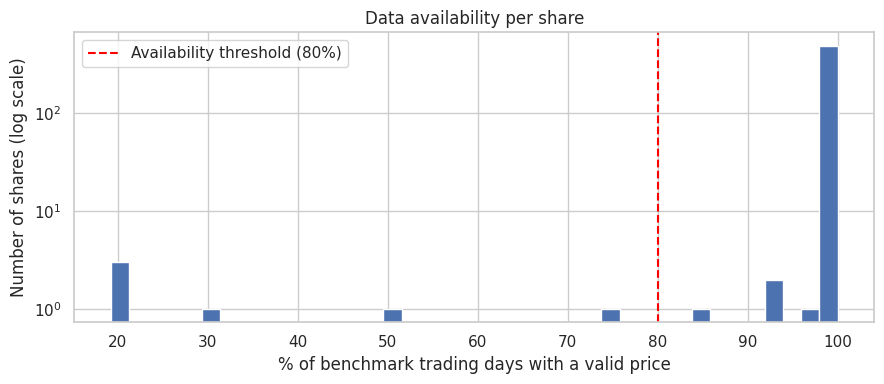

In [21]:
# Chart: how complete each share's price history is, with the availability threshold as a red line.
fig, ax = plt.subplots(figsize=(9, 4))
avail = history.loc[history["n_obs"] > 0, "availability"] * 100
ax.hist(avail, bins=40, color="#4C72B0", edgecolor="white")
ax.axvline(
    AVAIL_THRESHOLD * 100,
    color="red",
    linestyle="--",
    label=f"Availability threshold ({AVAIL_THRESHOLD:.0%})",
)
ax.set_yscale("log")
ax.set_xlabel("% of benchmark trading days with a valid price")
ax.set_ylabel("Number of shares (log scale)")
ax.set_title("Data availability per share")
ax.legend()
plt.tight_layout()
plt.show()

# Output:
# Almost every share sits at about 100%, so the y-axis is on a log scale to make the others visible.
# A few shares sit far to the left (about 20% to 75%) and fail the threshold. A few others between
# about 85% and 97% pass.

In [22]:
# Screen for corporate actions and extreme moves. Close and Adj Close are kept as separate fields:
# Adj Close is used for returns and Close x Volume for traded value. A jump that looks like a split
# is only a flag to review, not proof that the price is unadjusted.
ratio = adj_close / close
ratio_change = ratio / ratio.shift(1) - 1
price_ratio = close / close.shift(1)
extreme = (price_ratio - 1).abs() > 0.40
split_ratios = [1/2, 1/3, 1/4, 1/5, 1/10, 1/20, 2, 3, 4, 5, 10, 20]
split_like = pd.DataFrame(False, index=price_ratio.index, columns=price_ratio.columns)
for r in split_ratios:
    split_like |= (price_ratio / r - 1).abs() < 0.03
corp = pd.DataFrame({
    "dividend_adjustment_steps": (ratio_change.abs() > 1e-4).sum(),
    "ratio_jump_gt_10pct": (ratio_change.abs() > 0.10).sum(),
    "extreme_daily_moves_gt_40pct": extreme.sum(),
    "split_like_events_for_review": split_like.sum(),
})
corp.to_csv(f"{DATA_DIR}/corporate_action_checks.csv")

# Only add a ticker to this list after checking its corporate-action record and confirming the price
# series really has an unadjusted split.
CONFIRMED_UNADJUSTED_SPLIT_TICKERS = []
print("Shares with split-like events requiring review:", int((corp["split_like_events_for_review"] > 0).sum()))
print("Confirmed unadjusted split tickers excluded:", CONFIRMED_UNADJUSTED_SPLIT_TICKERS)
print("Shares with >40% daily price moves requiring review:", int((corp["extreme_daily_moves_gt_40pct"] > 0).sum()))
display(corp[(corp["split_like_events_for_review"] > 0) | (corp["ratio_jump_gt_10pct"] > 0) | (corp["extreme_daily_moves_gt_40pct"] > 0)])

Shares with split-like events requiring review: 0
Confirmed unadjusted split tickers excluded: []
Shares with >40% daily price moves requiring review: 7


,dividend_adjustment_steps,ratio_jump_gt_10pct,extreme_daily_moves_gt_40pct,split_like_events_for_review
APP,0,0,1,0
BE,0,0,1,0
CVNA,0,0,5,0
DXCM,0,0,1,0
GL,16,0,1,0
HOOD,0,0,1,0
RDDT,0,0,1,0


In [23]:
# List every day with a price move bigger than 40% so each one can be reviewed. They are kept unless
# they look like a split.
rows = []
for t in extreme.columns[extreme.any()]:
    for d in extreme.index[extreme[t]]:
        rows.append({"Ticker": t, "Date": d.date(), "Daily_price_move": price_ratio.loc[d, t] - 1})
display(pd.DataFrame(rows))

# Output:
# There are 11 such days across 7 shares: APP, BE, CVNA (5 days), DXCM, GL, HOOD and RDDT.
# The biggest gain is BE at +59% on 2024-11-15 and the biggest drop is GL at -53% on 2024-04-11.
# None of them matches a split ratio, so they are treated as real price moves and kept.

,Ticker,Date,Daily_price_move
0,APP,2024-11-07,0.4627
1,BE,2024-11-15,0.5919
2,CVNA,2022-08-05,0.4007
3,CVNA,2022-12-07,-0.4292
4,CVNA,2023-01-12,0.4600
5,CVNA,2023-06-08,0.5602
6,CVNA,2023-07-19,0.4020
7,DXCM,2024-07-26,-0.4066
8,GL,2024-04-11,-0.5314
9,HOOD,2021-08-04,0.5041


In [24]:
# Build the inclusion/exclusion log (the evidence tables and charts are in section 1.5.1). A share
# is kept only if it has data, at least 80% price and volume availability, positive prices, valid
# volume, no confirmed unadjusted split and a complete final 80-session window. Prices are not
# filled in.
RFM_HISTORY = BASE_WINDOW + ACTIVITY_WINDOW
recent = pd.DataFrame({
    "recent_missing": adj_close.iloc[-RFM_HISTORY:].isna().sum()
        + close.iloc[-RFM_HISTORY:].isna().sum()
        + volume.iloc[-RFM_HISTORY:].isna().sum()
})
checks = pd.concat([
    missing, nonpos, vol_err,
    history[["n_obs", "availability", "vol_availability"]], corp, recent
], axis=1).reindex(tickers)
no_data = checks["n_obs"].isna() | (checks["n_obs"] == 0)

rules = pd.DataFrame({
    "R1 no data downloaded": no_data,
    "R2 below availability threshold": ~no_data & ((checks["availability"] < AVAIL_THRESHOLD) | (checks["vol_availability"] < AVAIL_THRESHOLD)),
    "R3 non-positive price": (checks[["nonpos_close", "nonpos_adj_close"]] > 0).any(axis=1),
    "R4 volume error": (checks[["vol_negative", "vol_zero"]] > 0).any(axis=1),
    "R5 confirmed unadjusted split": checks.index.to_series().isin(CONFIRMED_UNADJUSTED_SPLIT_TICKERS).to_numpy(),
    "R6 gaps in latest 80 sessions": ~no_data & (checks["recent_missing"] > 0),
})
R = {c.split()[0]: c for c in rules.columns}
log = constituents.set_index("Ticker").copy()
log["exclusion_reason"] = rules.apply(lambda r: "; ".join(r.index[r.to_numpy()]), axis=1)
log["included"] = log["exclusion_reason"] == ""
valid_tickers = log.index[log["included"]].tolist()
print(f"Included after validation: {len(valid_tickers)} | excluded: {int((~log["included"]).sum())}")

Included after validation: 490 | excluded: 13


In [25]:
# Summarise the exclusions by reason and list the excluded shares.
display(log.loc[~log["included"], "exclusion_reason"].value_counts().to_frame("shares"))
display(log.loc[~log["included"], ["Company", "Sector", "exclusion_reason"]].head(18))

# Output:
# 6 shares fail R2 (availability below 80%), 5 fail R1 (no data) and 2 fail R4 (volume errors: FERG
# and SW).
# Most of the excluded shares are recent spin-offs or listings, for example GEV, SOLV, GEHC, VLTO,
# RDDT and CEG.
# Only today's index members are used, so companies that left the index since 2021 are missing. This
# is survivorship bias, so the results describe the survivors only.

,shares
exclusion_reason,
R2 below availability threshold,6
R1 no data downloaded,5
R4 volume error,2


,Company,Sector,exclusion_reason
Ticker,,,
CEG,Constellation Energy,Utilities,R2 below availability threshold
FDXF,FedEx Freight,Industrials,R1 no data downloaded
FERG,Ferguson Enterprises,Industrials,R4 volume error
GEHC,GE HealthCare,Health Care,R2 below availability threshold
GEV,GE Vernova,Industrials,R2 below availability threshold
HONA,Honeywell Aerospace,Industrials,R1 no data downloaded
Q,Qnity Electronics,Information Technology,R1 no data downloaded
RDDT,Reddit,Communication Services,R2 below availability threshold
SNDK,Sandisk,Information Technology,R1 no data downloaded


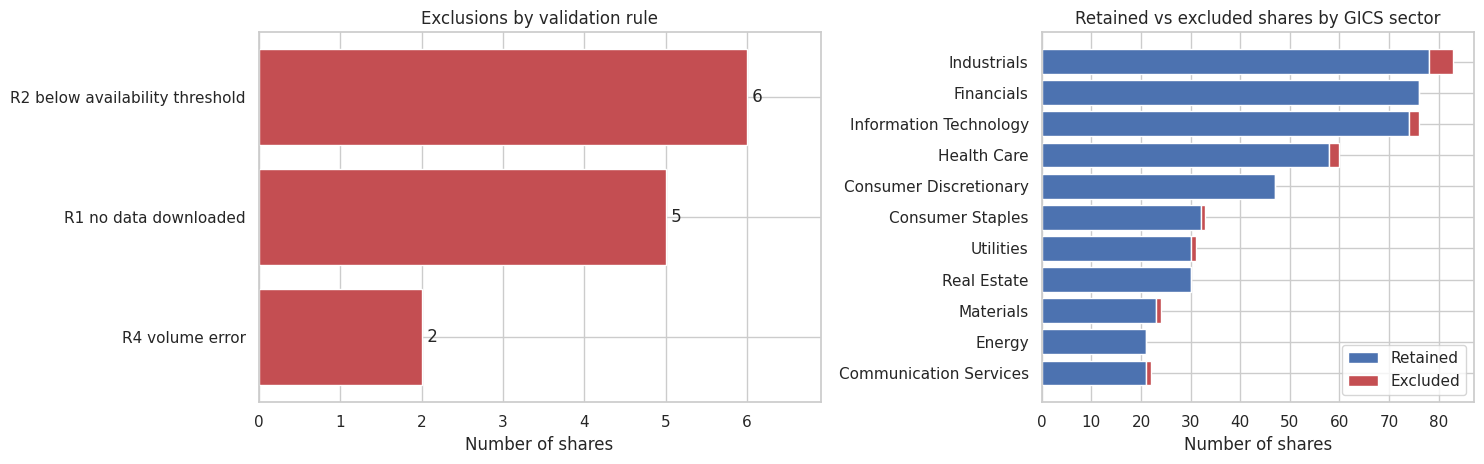

In [26]:
# Chart: number of exclusions for each rule (left) and retained vs excluded shares for each GICS
# sector (right).
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

reason_counts = rules.sum().sort_values()
reason_counts = reason_counts[reason_counts > 0]
if len(reason_counts):
    axes[0].barh(reason_counts.index, reason_counts.values, color="#C44E52")
    for y, v in enumerate(reason_counts.values):
        axes[0].text(v, y, f" {v}", va="center")
axes[0].set_xlim(0, (reason_counts.max() if len(reason_counts) else 1) * 1.15)
axes[0].set_title("Exclusions by validation rule")
axes[0].set_xlabel("Number of shares")

sector_counts = (
    log.groupby(["Sector", "included"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "Retained", False: "Excluded"})
)
sector_counts = sector_counts.reindex(columns=["Retained", "Excluded"], fill_value=0)
sector_counts = sector_counts.sort_values("Retained")
axes[1].barh(sector_counts.index, sector_counts["Retained"], color="#4C72B0", label="Retained")
axes[1].barh(
    sector_counts.index,
    sector_counts["Excluded"],
    left=sector_counts["Retained"],
    color="#C44E52",
    label="Excluded",
)
axes[1].set_title("Retained vs excluded shares by GICS sector")
axes[1].set_xlabel("Number of shares")
axes[1].legend()
plt.tight_layout()
plt.show()

# Output:
# Left chart: 6 shares for R2, 5 for R1 and 2 for R4.
# Right chart: Industrials loses the most shares (5: FDXF, FERG, GEV, HONA and VLTO). Health Care
# (GEHC, SOLV) and Information Technology (Q, SNDK) lose 2 each. Consumer Staples (VYLR), Utilities
# (CEG), Communication Services (RDDT) and Materials (SW) lose 1 each, and Energy, Financials,
# Consumer Discretionary and Real Estate lose none.

In [27]:
# Keep the observed prices exactly as downloaded. No forward-fill or back-fill is used (FILL_PRICES
# = False), so every missing value stays NaN. Close and Adj Close should be missing on exactly the
# same days.
assert not FILL_PRICES, "Price imputation must remain disabled"
close_v = close[valid_tickers].copy()
adj_close_v = adj_close[valid_tickers].copy()
volume_v = volume[valid_tickers].copy()

missingness_difference = int((close_v.isna() != adj_close_v.isna()).to_numpy().sum())
print("Close vs Adj Close missingness disagreements (investigate if non-zero):", missingness_difference)
print("Validated raw price shape:", close_v.shape)
print("Shares with missing historical prices retained as NaN:", int(adj_close_v.isna().any().sum()))

Close vs Adj Close missingness disagreements (investigate if non-zero): 0
Validated raw price shape: (1005, 490)
Shares with missing historical prices retained as NaN: 4


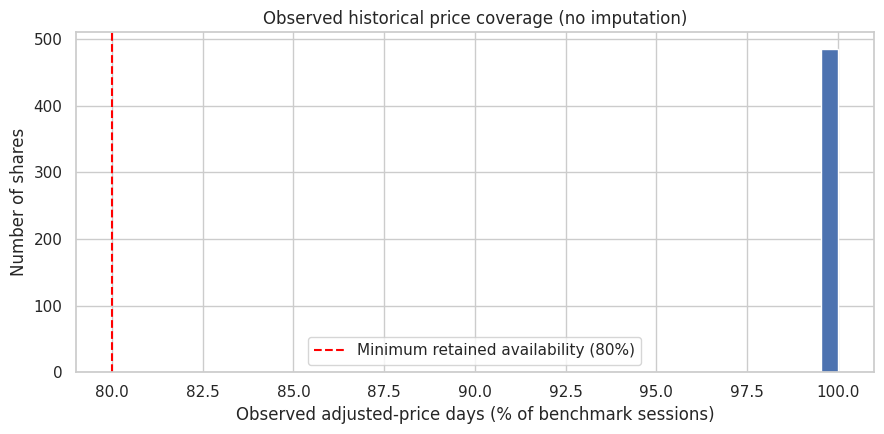

In [28]:
# Chart: price coverage for the retained shares. No prices are filled in.
coverage = adj_close_v.notna().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(coverage * 100, bins=30, edgecolor="white")
ax.axvline(AVAIL_THRESHOLD * 100, color="red", linestyle="--", label=f"Minimum retained availability ({AVAIL_THRESHOLD:.0%})")
ax.set_xlabel("Observed adjusted-price days (% of benchmark sessions)")
ax.set_ylabel("Number of shares")
ax.set_title("Observed historical price coverage (no imputation)")
ax.legend()
plt.tight_layout()
plt.show()

### 1.3 Weekly return and weekly beta

In [29]:
# Friday-ending weekly prices, using the last available trading price in each week. Weeks before a
# listing stay missing, and incomplete first or last weeks are dropped.
weekly_adj = adj_close_v.resample("W-FRI").last()
weekly_bench = bench["adj_close"].resample("W-FRI").last()
week_end = weekly_adj.index
week_start = week_end - pd.Timedelta(days=4)
complete = (week_start >= pd.Timestamp(START_DATE)) & (week_end < pd.Timestamp(END_DATE))
print("Incomplete weeks dropped:", [d.date().isoformat() for d in week_end[~complete]])
weekly_adj, weekly_bench = weekly_adj.loc[complete], weekly_bench.loc[complete]
print("Missing weekly prices across retained shares:", int(weekly_adj.isna().sum().sum()), "| benchmark:", int(weekly_bench.isna().sum()))
print("Weekly price labels:", len(weekly_adj), "from", weekly_adj.index.min().date(), "to", weekly_adj.index.max().date())

Incomplete weeks dropped: ['2025-01-03']
Missing weekly prices across retained shares: 62 | benchmark: 0
Weekly price labels: 208 from 2021-01-08 to 2024-12-27


In [30]:
# Weekly returns are only worked out from two valid weekly prices next to each other.
# fill_method=None stops pandas carrying an old price over a missing week, which would give a false
# return.
weekly_ret = weekly_adj.pct_change(fill_method=None).iloc[1:]
bench_ret = weekly_bench.pct_change(fill_method=None).iloc[1:]
common_weeks = weekly_ret.index.intersection(bench_ret.index)
weekly_ret, bench_ret = weekly_ret.loc[common_weeks], bench_ret.loc[common_weeks]
assert weekly_ret.index.equals(bench_ret.index)

weekly_obs = weekly_ret.count()
print("Common weekly labels:", len(common_weeks))
print("Per-share valid adjacent weekly returns: min / median / max =",
      int(weekly_obs.min()), int(weekly_obs.median()), int(weekly_obs.max()))
print("Benchmark valid weekly returns:", int(bench_ret.notna().sum()))
print("Benchmark Close and Adj Close identical:", bool(np.allclose(bench["close"], bench["adj_close"], equal_nan=True)))

Common weekly labels: 207
Per-share valid adjacent weekly returns: min / median / max = 178 207 207
Benchmark valid weekly returns: 207
Benchmark Close and Adj Close identical: True


#### 1.3.1 Mean weekly return

In [31]:
# Mean weekly return for each share: the average of its observed weekly returns.
mean_weekly_return = weekly_ret.mean(axis=0, skipna=True)
n_weeks = weekly_ret.count()
assert (n_weeks >= MIN_WEEKS).all(), "A retained share has fewer than MIN_WEEKS valid weekly returns"
for t in weekly_ret.columns:
    assert np.isclose(mean_weekly_return[t], weekly_ret[t].dropna().mean())
print("Valid weekly observations per share: min / median / max =", int(n_weeks.min()), int(n_weeks.median()), int(n_weeks.max()))
display(mean_weekly_return.describe().to_frame("mean_weekly_return"))

Valid weekly observations per share: min / median / max = 178 207 207


,mean_weekly_return
count,490.0000
mean,0.0029
std,0.0027
min,-0.0045
25%,0.0012
50%,0.0027
75%,0.0043
max,0.0178


#### 1.3.2 Weekly beta

In [32]:
# Function for weekly beta: Cov(share, market) / Var(market), using only the weeks where both
# returns exist (at least 52 weeks needed). Then calculate the beta of every share.
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename("share"), market_returns.rename("market")], axis=1)
        paired = paired.replace([np.inf, -np.inf], np.nan).dropna()
        variance = paired["market"].var(ddof=1)
        beta_value = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta_value = paired["share"].cov(paired["market"]) / variance
        results.append({"Share": share, "Beta": beta_value, "Paired_weeks": len(paired)})
    return pd.DataFrame(results, columns=["Share", "Beta", "Paired_weeks"]).set_index("Share")


beta_df = calculate_weekly_beta(weekly_ret, bench_ret, min_weeks=MIN_WEEKS)
beta = beta_df["Beta"]

print("Paired weekly observations used for beta (unique values):", beta_df["Paired_weeks"].unique())
print("Shares without a beta (fewer than MIN_WEEKS paired weeks):", int(beta.isna().sum()))
display(beta.describe().to_frame("weekly_beta"))

# Output:
# Every share has at least 178 paired weekly returns (207 for most), well above the 52-week minimum,
# so all 490 shares get a beta.
# The average beta is 0.98 and the median is 0.95. The range is 0.06 to 3.78 and 75% of the shares
# are below 1.19.

Paired weekly observations used for beta (unique values): [207 193 202 178]
Shares without a beta (fewer than MIN_WEEKS paired weeks): 0


,weekly_beta
count,490.0000
mean,0.9823
std,0.4229
min,0.0555
25%,0.6678
50%,0.9547
75%,1.1886
max,3.7786


In [33]:
# Two extra checks on beta using the same paired weeks: the covariance/variance version and an OLS
# slope.
vectorised = pd.Series({t: weekly_ret[t].cov(bench_ret) / bench_ret[weekly_ret[t].notna()].var() for t in weekly_ret.columns})
ols_slope = {}
for t in weekly_ret.columns:
    paired = pd.concat([weekly_ret[t], bench_ret], axis=1).dropna()
    ols_slope[t] = np.polyfit(paired.iloc[:, 1].to_numpy(), paired.iloc[:, 0].to_numpy(), 1)[0]
ols_slope = pd.Series(ols_slope)
print("Beta matches pairwise Cov/Var:", bool(np.allclose(beta, vectorised, equal_nan=True)))
print("Beta matches pairwise OLS slope:", bool(np.allclose(beta, ols_slope, equal_nan=True)))

Beta matches pairwise Cov/Var: True
Beta matches pairwise OLS slope: True


In [34]:
# Put the benchmark return next to the share returns to see the weekly data the betas are calculated
# from.
beta_input_dataset = weekly_ret.copy()
beta_input_dataset.insert(0, "S&P 500 Benchmark (^GSPC)", bench_ret)

print(f"Dataset Shape: {beta_input_dataset.shape} (Weeks x Assets)")
display(beta_input_dataset.head(10))

# Output:
# The table has 207 weeks and 491 columns (the benchmark plus 490 shares). In the first week shown
# (2021-01-15) the benchmark fell by 1.48%.

Dataset Shape: (207, 491) (Weeks x Assets)


,S&P 500 Benchmark (^GSPC),MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,ABNB,AKAM,ALB,...,WELL,WST,WDC,WY,WSM,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.0148,-0.0064,0.0119,0.0012,0.0423,-0.0365,-0.0557,-0.0674,0.0858,0.0447,-0.0067,0.0041,0.1302,0.0289,-0.0215,...,0.0250,-0.0264,-0.0118,-0.0258,0.1573,0.0563,0.0148,-0.0224,-0.0257,-0.0122,-0.0361,-0.0049,0.0092,0.0074,-0.0390
2021-01-22,0.0194,0.0211,0.0164,0.0138,0.0031,0.0044,0.0313,0.0519,-0.0181,-0.0011,0.0010,-0.0115,0.0744,0.0245,-0.0357,...,-0.0184,0.0028,-0.0098,0.0212,0.0641,-0.0400,-0.0007,0.0583,0.0115,-0.0031,-0.0087,0.0044,-0.0009,0.0056,0.0125
2021-01-29,-0.0331,0.0392,-0.0553,0.0953,-0.0756,-0.0504,-0.0289,-0.0771,-0.0940,-0.0269,-0.0488,-0.0594,0.0097,0.0181,-0.0636,...,-0.0392,-0.0020,0.1128,-0.0608,-0.0257,-0.0171,-0.0172,-0.0340,-0.0737,-0.0119,-0.0586,-0.0523,-0.0514,-0.0456,-0.0556
2021-02-05,0.0465,0.0191,0.1050,0.0036,0.0610,0.0480,0.0727,0.0264,0.1013,0.0060,0.0250,-0.0510,0.0636,0.0328,-0.0338,...,0.0564,-0.0272,0.0587,0.1029,-0.0013,0.0405,0.1033,0.1601,0.1754,-0.0086,0.0166,0.0379,0.0497,0.0405,0.0326
2021-02-12,0.0123,0.0065,0.0062,0.0339,-0.0395,0.0155,0.0137,0.0668,0.0622,0.0323,0.0390,0.0292,0.0889,-0.1141,0.0475,...,0.0545,0.0091,0.0976,0.0186,-0.0166,0.0340,0.0157,0.0660,0.0074,-0.0299,0.0095,0.0060,0.1735,0.0093,0.0466
2021-02-19,-0.0071,-0.0121,-0.0121,-0.0405,0.0055,-0.0124,-0.0395,-0.0447,-0.0077,0.0320,-0.0087,0.0128,-0.0546,-0.0269,-0.0514,...,0.0222,-0.0424,0.0505,-0.0014,0.0254,-0.0088,-0.0107,-0.0178,0.0493,0.0086,0.0091,-0.0032,0.0276,-0.0292,-0.0402
2021-02-26,-0.0245,-0.0084,-0.0045,-0.0265,0.0260,-0.0133,-0.0406,-0.0566,-0.0618,-0.0040,-0.0378,-0.0313,0.0263,-0.0441,0.0067,...,-0.0072,-0.0032,-0.0051,-0.0320,0.0112,0.0088,-0.0193,-0.1128,0.0653,-0.0561,-0.0018,-0.0152,0.0173,0.0408,-0.0297
2021-03-05,0.0081,0.0328,0.0524,-0.0211,-0.0097,-0.0055,-0.0410,-0.0709,-0.0215,0.0430,-0.0486,0.0321,-0.1286,0.0278,-0.0848,...,0.0348,-0.0650,-0.0067,0.0018,-0.0238,0.0622,0.0334,-0.0333,0.0121,0.0471,0.0068,0.0077,-0.0426,-0.0280,-0.0616
2021-03-12,0.0264,0.0228,0.0304,-0.0046,0.0142,0.0619,0.0079,0.0322,0.0947,0.0378,0.0456,0.0358,0.1498,0.0043,0.0959,...,0.0549,0.0447,0.0059,0.0637,0.0539,0.0033,-0.0231,0.0663,0.0280,0.0194,0.0163,0.0046,-0.0111,0.0294,0.0473


In [35]:
# Turn the weekly return table into a long table (one row per share per week), attach each share's
# beta, then check for missing values.
combined_df = (
    weekly_ret.rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(id_vars="Week", var_name="Share", value_name="Weekly_Return")
    .join(beta, on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)
print("Null values per column:")
print(combined_df.isna().sum())

rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)
print("Rows removed:", rows_before - len(combined_df), "| Rows remaining:", len(combined_df))
combined_df.to_csv(f"{DATA_DIR}/weekly_returns_long.csv", index=False)
combined_df.head()

# Output:
# 62 weekly returns are missing, so 62 rows were removed and 101,368 rows remain (490 shares x 207
# weeks = 101,430, minus 62). Share A, for example, has a beta of 1.0747.

Null values per column:
Week              0
Share             0
Weekly_Return    62
Beta              0
dtype: int64
Rows removed: 62 | Rows remaining: 101368


,Week,Share,Weekly_Return,Beta
0,2021-01-15,A,-0.0067,1.0747
1,2021-01-22,A,0.0010,1.0747
2,2021-01-29,A,-0.0488,1.0747
3,2021-02-05,A,0.0250,1.0747
4,2021-02-12,A,0.0390,1.0747


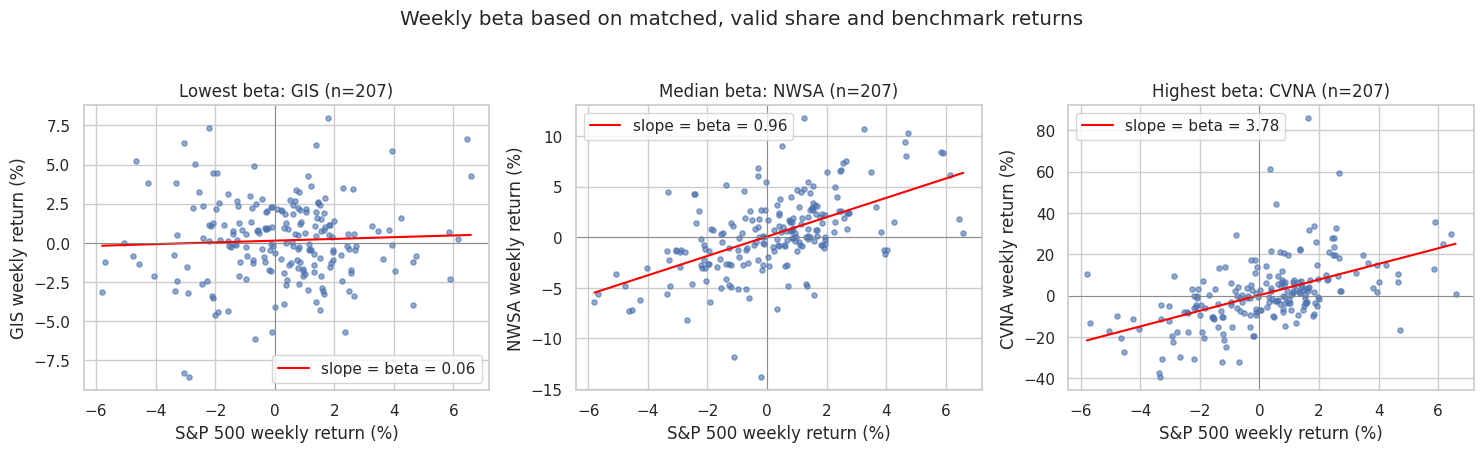

In [36]:
# Chart: the shares with the lowest, median and highest beta, each plotted against the market using
# matched weekly returns.
b = beta.dropna()
pick = {"Lowest beta": b.idxmin(), "Median beta": (b - b.median()).abs().idxmin(), "Highest beta": b.idxmax()}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True)
for ax, (label, t) in zip(axes, pick.items()):
    paired = pd.concat([weekly_ret[t].rename("share"), bench_ret.rename("market")], axis=1).dropna()
    x, y = paired["market"].to_numpy(), paired["share"].to_numpy()
    intercept = y.mean() - beta[t] * x.mean()
    xs = np.linspace(x.min(), x.max(), 50)
    ax.scatter(x * 100, y * 100, s=14, alpha=0.6)
    ax.plot(xs * 100, (intercept + beta[t] * xs) * 100, color="red", label=f"slope = beta = {beta[t]:.2f}")
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(f"{label}: {t} (n={len(paired)})")
    ax.set_xlabel("S&P 500 weekly return (%)"); ax.set_ylabel(f"{t} weekly return (%)")
    ax.legend()
fig.suptitle("Weekly beta based on matched, valid share and benchmark returns")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

In [39]:
# Check how many valid weekly returns each share has and confirm the gaps are not filled.
weekly_coverage = pd.DataFrame({
    "valid_weekly_returns": weekly_ret.count(),
    "missing_weekly_returns": weekly_ret.isna().sum(),
    "first_valid_week": weekly_ret.apply(pd.Series.first_valid_index),
    "last_valid_week": weekly_ret.apply(pd.Series.last_valid_index),
})
weekly_coverage.to_csv(f"{DATA_DIR}/weekly_return_coverage.csv")
display(weekly_coverage.sort_values("valid_weekly_returns").head(15))
assert weekly_coverage["valid_weekly_returns"].ge(MIN_WEEKS).all()

,valid_weekly_returns,missing_weekly_returns,first_valid_week,last_valid_week
HOOD,178,29,2021-08-06,2024-12-27
COIN,193,14,2021-04-23,2024-12-27
APP,193,14,2021-04-23,2024-12-27
EXE,202,5,2021-02-19,2024-12-27
WSM,207,0,2021-01-15,2024-12-27
WY,207,0,2021-01-15,2024-12-27
WDC,207,0,2021-01-15,2024-12-27
WST,207,0,2021-01-15,2024-12-27
WELL,207,0,2021-01-15,2024-12-27
WFC,207,0,2021-01-15,2024-12-27


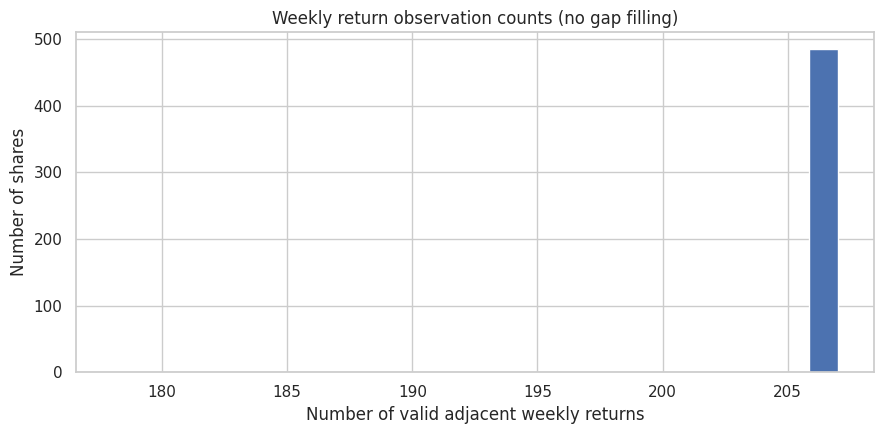

In [40]:
# Chart: number of valid weekly returns per share. Missing weeks are unavailable data, not zero
# returns.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(weekly_coverage["valid_weekly_returns"], bins=25, edgecolor="white")
ax.set_xlabel("Number of valid adjacent weekly returns")
ax.set_ylabel("Number of shares")
ax.set_title("Weekly return observation counts (no gap filling)")
plt.tight_layout(); plt.show()

### 1.4 Adapted RFM calculations

In [41]:
# Find the last date where every retained share and the benchmark have data (the observation date)
# and the latest 60 trading sessions up to it. The final 80-session check in 1.2 already guarantees
# these windows are complete.
common_dates = close_v.dropna(how="any").index.intersection(adj_close_v.dropna(how="any").index).intersection(bench["adj_close"].dropna().index)
observation_date = common_dates.max()
window_dates = calendar[calendar <= observation_date][-ACTIVITY_WINDOW:]
assert len(window_dates) == ACTIVITY_WINDOW
assert close_v.loc[window_dates].notna().all().all()
assert adj_close_v.loc[window_dates].notna().all().all()
assert volume_v.loc[window_dates].notna().all().all()
print("Observation date:", observation_date.date())
print(f"Latest {ACTIVITY_WINDOW} trading sessions:", window_dates.min().date(), "to", window_dates.max().date())

Observation date: 2024-12-31
Latest 60 trading sessions: 2024-10-07 to 2024-12-31


In [42]:
# Flag the high-volume days. A day counts as an event when its volume is more than 2 times the
# average of the previous 20 sessions (the day being tested is left out of that average).
vol = volume_v.loc[:observation_date]
baseline = vol.rolling(BASE_WINDOW).mean().shift(1)
threshold = HIGH_VOL_MULT * baseline
event = vol > threshold

print("Total high-volume events flagged:", int(event.sum().sum()))

# Output:
# 18,494 high-volume share-days are flagged across the 490 retained shares. The first 20 sessions of
# the sample have no baseline, so no event can be flagged there.
# The rule is rebuilt separately and tested in section 1.5.2.

Total high-volume events flagged: 18494


In [43]:
# Check the event flags against a direct calculation for a sample of retained shares.
assert len(vol) >= BASE_WINDOW + ACTIVITY_WINDOW
assert baseline.loc[window_dates].notna().all().all(), "Baseline missing inside the final 60-session window"
rng = np.random.default_rng(42)
for t in rng.choice(event.columns, min(3, len(event.columns)), replace=False):
    v = vol[t].to_numpy(dtype=float)
    valid = vol[t].notna().to_numpy()
    naive = np.zeros(len(v), dtype=bool)
    for i in range(BASE_WINDOW, len(v)):
        prev = v[i-BASE_WINDOW:i]
        naive[i] = valid[i] and np.isfinite(prev).all() and v[i] > HIGH_VOL_MULT * prev.mean()
    assert np.array_equal(naive, event[t].fillna(False).to_numpy()), f"Mismatch for {t}"
print("Manual rolling-threshold checks passed: preceding 20 sessions only; no look-ahead.")

Manual rolling-threshold checks passed: preceding 20 sessions only; no look-ahead.


#### 1.4.1 Recency

In [44]:
# Recency: find the date of each share's latest high-volume day and count the calendar days from
# there to the observation date. A share with no event would get a missing value, not 0.
last_event_date = pd.to_datetime(
    pd.Series(
        {t: (event.index[event[t].to_numpy()].max() if event[t].any() else pd.NaT) for t in event.columns}
    )
)

recency = (observation_date - last_event_date).dt.days

print("Shares with no event (Recency missing):", int(recency.isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((recency == 0).sum()))
display(recency.describe().to_frame("Recency"))

# Output:
# Every share had at least one high-volume day (0 missing) and none had one on 2024-12-31 (0 with R
# = 0).
# The smallest Recency is 4 days, the median is 11 days and the largest is 222 days (one share that
# last spiked about 7 months before the end).
# The median equals the 25th percentile (11) because many shares have the same latest spike date, as
# the next chart shows.

Shares with no event (Recency missing): 0
Shares with an event on the observation date (R = 0): 0


,Recency
count,490.0000
mean,20.5122
std,21.3432
min,4.0000
25%,11.0000
50%,11.0000
75%,17.2500
max,222.0000


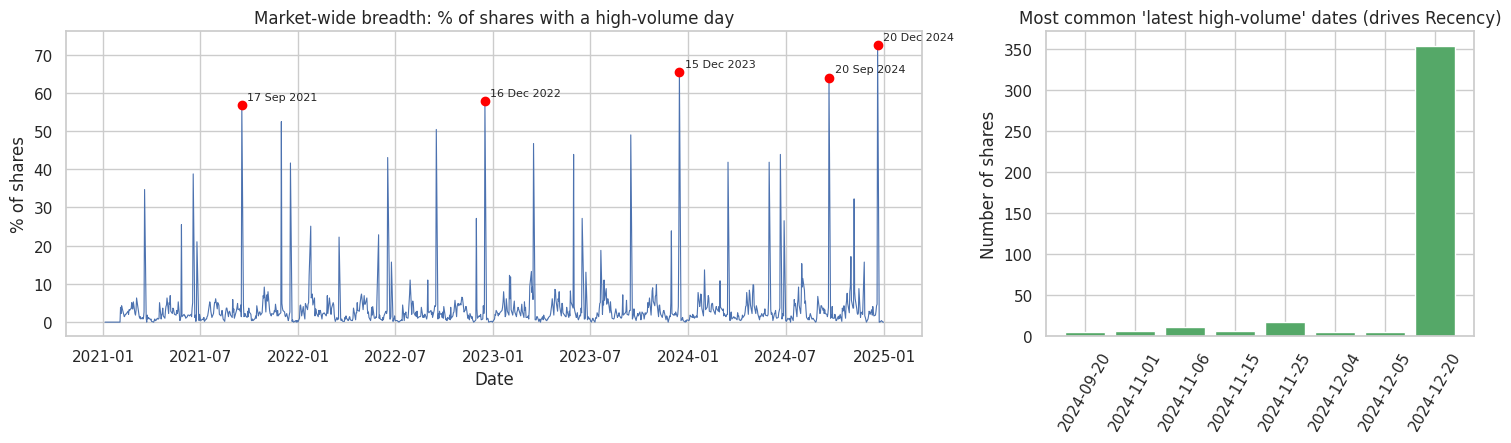

In [45]:
# Chart: percentage of shares with a high-volume day on each date (left, five busiest days marked)
# and the most common latest high-volume dates, which drive Recency (right).
breadth = event.sum(axis=1) / event.shape[1] * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2, 1]})

axes[0].plot(breadth.index, breadth.values, lw=0.8, color="#4C72B0")
for d, v in breadth.nlargest(5).items():
    axes[0].scatter(d, v, color="red", zorder=3)
    axes[0].annotate(d.strftime("%d %b %Y"), (d, v), textcoords="offset points", xytext=(4, 4), fontsize=8)
axes[0].set_title("Market-wide breadth: % of shares with a high-volume day")
axes[0].set_ylabel("% of shares")
axes[0].set_xlabel("Date")

last_counts = last_event_date.dt.strftime("%Y-%m-%d").value_counts().head(8).sort_index()
axes[1].bar(last_counts.index, last_counts.values, color="#55A868")
axes[1].set_title("Most common 'latest high-volume' dates (drives Recency)")
axes[1].set_ylabel("Number of shares")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

# Output:
# The spikes in the left chart are market-wide days when about 57% to 72% of shares had a
# high-volume day at once.
# The five busiest are 17 Sep 2021, 16 Dec 2022, 15 Dec 2023, 20 Sep 2024 and 20 Dec 2024. All of
# them are the third Friday of a quarter-end month, so this looks like quarterly options expiry and
# index rebalancing, although the data does not prove it.
# On the right, about 350 shares have 2024-12-20 as their latest spike, which is why most Recency
# values are 11.

#### 1.4.2 Frequency

In [46]:
# Frequency: count the high-volume days inside the latest 60 sessions (days only, not trades or
# shares).
frequency = event.loc[window_dates].sum()
display(frequency.describe().to_frame("Frequency"))

# Output:
# All 490 shares were counted. A typical share had about 3 high-volume days in the 60 sessions (mean
# 3.0, median 3).
# The minimum is 0 (a completely quiet share in this window) and the maximum is 8.

,Frequency
count,490.0000
mean,2.9980
std,1.3300
min,0.0000
25%,2.0000
50%,3.0000
75%,4.0000
max,8.0000


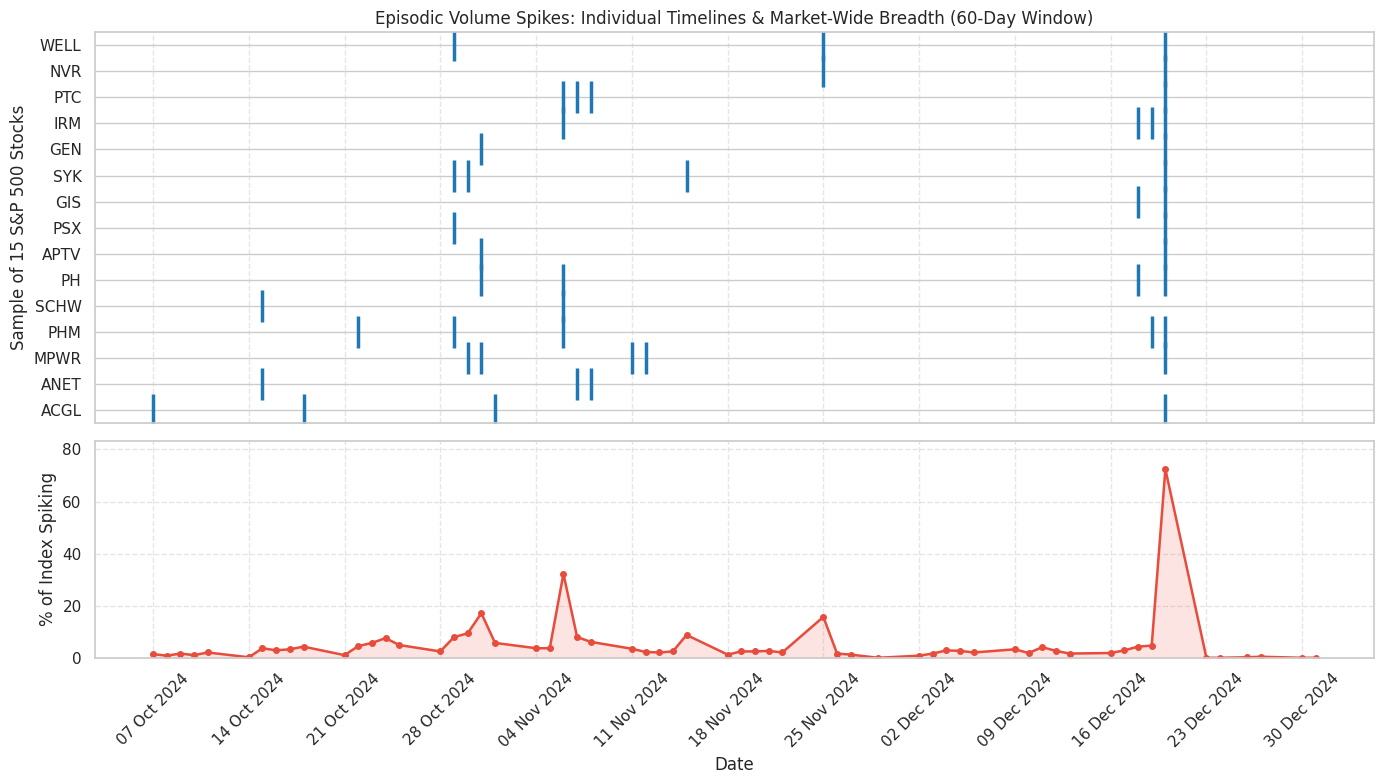

In [47]:
# Chart: barcode plot of high-volume days for a sample of shares (top) and the percentage of the
# index spiking on each day (bottom), for the final 60 sessions.
event_window = event.loc[window_dates]

# Pick a sample of 15 shares to show how individual spikes come and go
rng = np.random.default_rng(42)
sample_shares = rng.choice(event_window.columns, 15, replace=False)

# Two panels: individual shares on top, market breadth below
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={'height_ratios': [1.8, 1]})

# Top panel: one row per share with a mark on each high-volume day
for i, share in enumerate(sample_shares):
    # Dates when an event happened
    event_dates = event_window.index[event_window[share]]
    ax1.scatter(event_dates, [i] * len(event_dates), marker='|', s=500,
                color='#1f77b4', linewidth=2.5)

ax1.set_yticks(range(len(sample_shares)))
ax1.set_yticklabels(sample_shares)
ax1.set_ylabel("Sample of 15 S&P 500 Stocks")
ax1.set_title("Episodic Volume Spikes: Individual Timelines & Market-Wide Breadth (60-Day Window)")
ax1.grid(True, axis='x', linestyle='--', alpha=0.5)
ax1.set_ylim(-0.5, len(sample_shares) - 0.5)

# Bottom panel: % of all shares with a high-volume day on each date
breadth_window = event_window.mean(axis=1) * 100
ax2.plot(breadth_window.index, breadth_window.values, color='#e74c3c', lw=1.8, marker='o', markersize=4)
ax2.fill_between(breadth_window.index, breadth_window.values, color='#e74c3c', alpha=0.15)
ax2.set_ylabel("% of Index Spiking")
ax2.set_xlabel("Date")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_ylim(0, max(breadth_window.values) * 1.15)

# Format the dates on the x-axis
ax2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### 1.4.3 Monetary

In [48]:
# Monetary: add up Close x Volume over the latest 60 sessions to get the approximate dollar value
# traded for each share.
daily_traded_value = close_v.loc[window_dates] * vol.loc[window_dates]
monetary = daily_traded_value.sum()

display(monetary.describe().to_frame("Monetary (USD)"))

# Output:
# The average share traded about $39.8 billion over the 60 sessions, but the median is only $16.8
# billion, so a few very large shares pull the average up.
# The smallest is about $1.3 billion and the largest is about $1.85 trillion (TSLA, as the next
# chart shows).

,Monetary (USD)
count,490.0000
mean,"39,844,439,243.4305"
std,"128,892,252,349.0320"
min,"1,297,482,617.0479"
25%,"10,251,022,367.6052"
50%,"16,796,672,784.0942"
75%,"32,621,670,382.5271"
max,"1,847,697,379,221.8428"


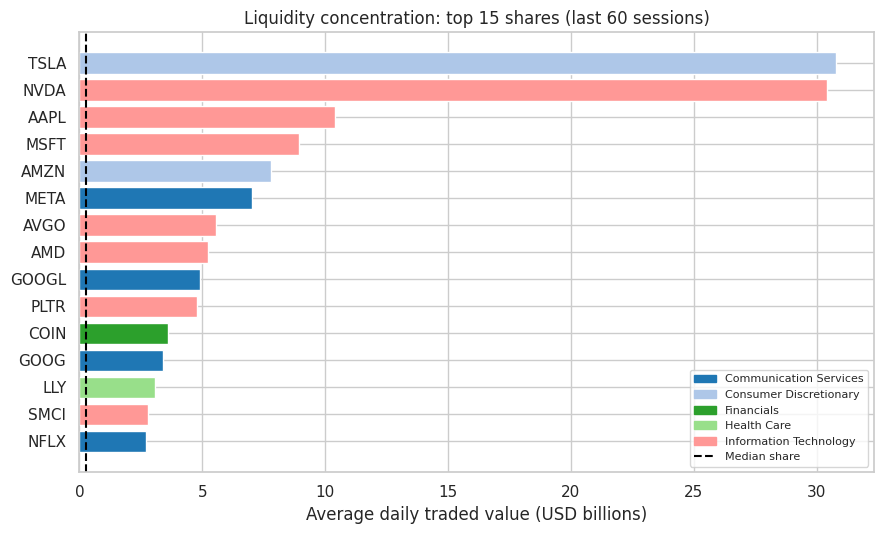

In [49]:
# Chart: top 15 shares by average daily traded value over the last 60 sessions, coloured by sector,
# with the median share as a dashed line.
top15 = (monetary / ACTIVITY_WINDOW / 1e9).nlargest(15).iloc[::-1]
sector_of = constituents.set_index("Ticker")["Sector"]
palette = dict(zip(sorted(sector_of.unique()), sns.color_palette("tab20", sector_of.nunique())))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top15.index, top15.values, color=[palette[sector_of[t]] for t in top15.index])
ax.axvline(monetary.median() / ACTIVITY_WINDOW / 1e9, color="black", ls="--", label="Median share")
ax.set_xlabel("Average daily traded value (USD billions)")
ax.set_title(f"Liquidity concentration: top 15 shares (last {ACTIVITY_WINDOW} sessions)")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[s]) for s in sorted({sector_of[t] for t in top15.index})]
ax.legend(
    handles + [plt.Line2D([0], [0], color="black", ls="--")],
    sorted({sector_of[t] for t in top15.index}) + ["Median share"],
    fontsize=8,
    loc="lower right",
)
plt.tight_layout()
plt.show()

# Output:
# TSLA and NVDA are far ahead at about $30 billion a day each, followed by AAPL (about $10 billion),
# MSFT and AMZN.
# Information Technology has the most names in the top 15 (7 of 15). The median share (dashed line)
# trades only about $0.28 billion a day.

#### 1.4.4 Feature table for the common share set

In [50]:
# Feature table with one row per share: the five features plus a few extra columns for reference.
features = pd.DataFrame({
    "mean_weekly_return": mean_weekly_return,
    "weekly_beta": beta,
    "n_weekly_obs": n_weeks,
    "n_beta_obs": beta_df["Paired_weeks"],
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary,
    "last_high_volume_date": last_event_date,
}).join(constituents.set_index("Ticker")[["Company", "Sector"]])
core = ["mean_weekly_return", "weekly_beta", "Recency", "Frequency", "Monetary"]
features_final = features.dropna(subset=core).copy()
features_final["Recency"] = features_final["Recency"].astype(int)
features_final["Frequency"] = features_final["Frequency"].astype(int)
features_final = features_final[["Company", "Sector"] + [c for c in features_final.columns if c not in ("Company", "Sector")]]

# Log any extra exclusions caused by too few weekly returns or no high-volume event.
dropped = features.index.difference(features_final.index)
for ticker in dropped:
    reasons = []
    if pd.isna(features.loc[ticker, "mean_weekly_return"]) or pd.isna(features.loc[ticker, "weekly_beta"]):
        reasons.append("insufficient valid weekly return/beta observations")
    if pd.isna(features.loc[ticker, "Recency"]):
        reasons.append("no qualifying high-volume event in valid history")
    log.loc[ticker, "included"] = False
    log.loc[ticker, "exclusion_reason"] = "; ".join(reasons) or "missing required feature"
features_final.to_csv(f"{DATA_DIR}/features_table.csv")
features_final.to_excel(f"{DATA_DIR}/features_table.xlsx")
display(features_final.head())
print(f"Final common share set: {len(features_final)} | additional feature exclusions: {len(dropped)}")

,Company,Sector,mean_weekly_return,weekly_beta,n_weekly_obs,n_beta_obs,Recency,Frequency,Monetary,last_high_volume_date
MMM,3M,Industrials,0.0011,0.8691,207,207,11,4,"25,991,458,733.3420",2024-12-20
AOS,A. O. Smith,Industrials,0.0020,1.0428,207,207,11,2,"4,748,980,279.6021",2024-12-20
ABT,Abbott Laboratories,Health Care,0.0010,0.5835,207,207,11,1,"35,230,272,606.2744",2024-12-20
ABBV,AbbVie,Health Care,0.0037,0.4254,207,207,11,3,"68,370,537,641.6611",2024-12-20
ACN,Accenture,Information Technology,0.0024,1.1433,207,207,11,2,"51,994,299,403.1158",2024-12-20


Final common share set: 490 | additional feature exclusions: 0


### 1.5 Metric interpretation and supporting evidence

#### 1.5.1 Validation rules and inclusion/exclusion log

In [51]:
# Table of the validation rules: what each one tests, its threshold and how many shares fail it.
# 'Failing only this rule' counts the shares where it is the only reason for exclusion.
n_rules_failed = rules.sum(axis=1)
n_fail_F1 = int(features[["mean_weekly_return", "weekly_beta"]].isna().any(axis=1).sum())
n_fail_F2 = int(features["Recency"].isna().sum())

rule_rows = [
    (R["R1"], "No adjusted-close observation at all (nothing downloaded)", "n_obs = 0", int(rules[R["R1"]].sum()), int((rules[R["R1"]] & (n_rules_failed == 1)).sum())),
    (R["R2"], "Price or volume available on too few benchmark sessions", f"availability < {MIN_AVAILABILITY:.0%}", int(rules[R["R2"]].sum()), int((rules[R["R2"]] & (n_rules_failed == 1)).sum())),
    (R["R3"], "Zero or negative Close or Adj Close", "price <= 0", int(rules[R["R3"]].sum()), int((rules[R["R3"]] & (n_rules_failed == 1)).sum())),
    (R["R4"], "Zero or negative daily volume", "volume <= 0", int(rules[R["R4"]].sum()), int((rules[R["R4"]] & (n_rules_failed == 1)).sum())),
    (R["R5"], "Unadjusted split confirmed against the corporate-action record", "manual list", int(rules[R["R5"]].sum()), int((rules[R["R5"]] & (n_rules_failed == 1)).sum())),
    (R["R6"], f"Any missing Close, Adj Close or Volume in the latest {RFM_HISTORY} sessions ({BASE_WINDOW} baseline + {ACTIVITY_WINDOW} window)", f"gaps > 0 in last {RFM_HISTORY}", int(rules[R["R6"]].sum()), int((rules[R["R6"]] & (n_rules_failed == 1)).sum())),
    ("F1 too few weekly returns", "Fewer valid paired weekly returns than needed for mean return and beta", f"< {MIN_WEEKS} weeks", n_fail_F1, n_fail_F1),
    ("F2 no event in history", "No high-volume event in the share's history, so Recency is undefined", "no event", n_fail_F2, n_fail_F2),
]
rule_table = pd.DataFrame(rule_rows, columns=["Rule", "What is tested", "Threshold", "Shares failing", "Failing only this rule"]).set_index("Rule")
display(rule_table)
print(f"Constituents: {len(tickers)} | excluded by R1-R6: {int((n_rules_failed > 0).sum())} | "
      f"excluded by F1-F2: {n_fail_F1 + n_fail_F2} | retained: {len(features_final)}")

,What is tested,Threshold,Shares failing,Failing only this rule
Rule,,,,
R1 no data downloaded,No adjusted-close observation at all (nothing ...,n_obs = 0,5,5
R2 below availability threshold,Price or volume available on too few benchmark...,availability < 80%,6,6
R3 non-positive price,Zero or negative Close or Adj Close,price <= 0,0,0
R4 volume error,Zero or negative daily volume,volume <= 0,2,2
R5 confirmed unadjusted split,Unadjusted split confirmed against the corpora...,manual list,0,0
R6 gaps in latest 80 sessions,"Any missing Close, Adj Close or Volume in the ...",gaps > 0 in last 80,0,0
F1 too few weekly returns,Fewer valid paired weekly returns than needed ...,< 52 weeks,0,0
F2 no event in history,"No high-volume event in the share's history, s...",no event,0,0


Constituents: 503 | excluded by R1-R6: 13 | excluded by F1-F2: 0 | retained: 490


In [52]:
# Inclusion/exclusion log with one row per constituent and the evidence behind each decision (saved
# as CSV).
log_full = (
    log.join(checks[["n_obs", "availability", "vol_availability", "recent_missing"]])
       .join(history[["first_date", "last_date"]])
)
log_full.index.name = "Ticker"
log_full.to_csv(f"{DATA_DIR}/inclusion_exclusion_log.csv")

# Reconciliation: the log must match the share set used in every later step.
assert len(log_full) == len(tickers) == len(constituents)
assert set(log_full.index[log_full["included"]]) == set(features_final.index)
print(f"Constituents: {len(log_full)} | included: {int(log_full['included'].sum())} | excluded: {int((~log_full['included']).sum())}")

print("\nExclusions by reason:")
display(log_full.loc[~log_full["included"], "exclusion_reason"].value_counts().to_frame("shares"))
print("Excluded shares:")
display(log_full.loc[~log_full["included"], ["Company", "Sector", "exclusion_reason", "n_obs", "availability", "first_date"]])

# Shares that were kept even though they were not listed for the whole period (they pass the 80%
# rule).
print("Included with partial history:")
partial = log_full[log_full["included"] & (log_full["availability"] < 1)]
display(partial[["Company", "Sector", "n_obs", "availability", "first_date"]])

Constituents: 503 | included: 490 | excluded: 13

Exclusions by reason:


,shares
exclusion_reason,
R2 below availability threshold,6
R1 no data downloaded,5
R4 volume error,2


Excluded shares:


,Company,Sector,exclusion_reason,n_obs,availability,first_date
Ticker,,,,,,
CEG,Constellation Energy,Utilities,R2 below availability threshold,742,0.7383,2022-01-19
FDXF,FedEx Freight,Industrials,R1 no data downloaded,0,0.0000,NaT
FERG,Ferguson Enterprises,Industrials,R4 volume error,1005,1.0000,2021-01-04
GEHC,GE HealthCare,Health Care,R2 below availability threshold,513,0.5104,2022-12-15
GEV,GE Vernova,Industrials,R2 below availability threshold,193,0.1920,2024-03-27
HONA,Honeywell Aerospace,Industrials,R1 no data downloaded,0,0.0000,NaT
Q,Qnity Electronics,Information Technology,R1 no data downloaded,0,0.0000,NaT
RDDT,Reddit,Communication Services,R2 below availability threshold,197,0.1960,2024-03-21
SNDK,Sandisk,Information Technology,R1 no data downloaded,0,0.0000,NaT


Included with partial history:


,Company,Sector,n_obs,availability,first_date
Ticker,,,,,
APP,AppLovin,Communication Services,935,0.9303,2021-04-15
COIN,Coinbase,Financials,936,0.9313,2021-04-14
EXE,Expand Energy,Energy,979,0.9741,2021-02-10
HOOD,Robinhood Markets,Financials,862,0.8577,2021-07-29


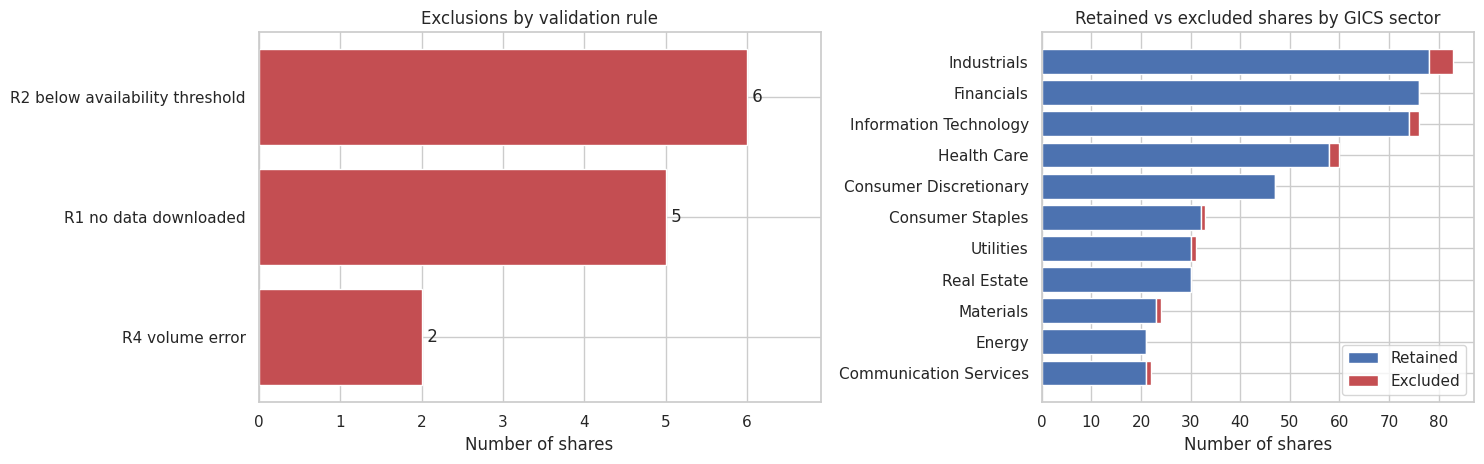

In [53]:
# Chart: number of exclusions for each rule (left) and retained vs excluded shares for each GICS
# sector (right).
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

reason_counts = rules.sum().sort_values()
reason_counts = reason_counts[reason_counts > 0]
if len(reason_counts):
    axes[0].barh(reason_counts.index, reason_counts.values, color="#C44E52")
    for y, v in enumerate(reason_counts.values):
        axes[0].text(v, y, f" {v}", va="center")
axes[0].set_xlim(0, (reason_counts.max() if len(reason_counts) else 1) * 1.15)
axes[0].set_title("Exclusions by validation rule")
axes[0].set_xlabel("Number of shares")

sector_counts = (
    log.groupby(["Sector", "included"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "Retained", False: "Excluded"})
)
sector_counts = sector_counts.reindex(columns=["Retained", "Excluded"], fill_value=0)
sector_counts = sector_counts.sort_values("Retained")
axes[1].barh(sector_counts.index, sector_counts["Retained"], color="#4C72B0", label="Retained")
axes[1].barh(
    sector_counts.index,
    sector_counts["Excluded"],
    left=sector_counts["Retained"],
    color="#C44E52",
    label="Excluded",
)
axes[1].set_title("Retained vs excluded shares by GICS sector")
axes[1].set_xlabel("Number of shares")
axes[1].legend()
plt.tight_layout()
plt.show()

# Output:
# Left chart: R2 removes 6 shares, R1 removes 5 and R4 removes 2 (13 in total). No share fails R3,
# R5 or R6.
# Right chart: Industrials loses the most shares (5: FDXF, FERG, GEV, HONA and VLTO). Health Care
# (GEHC, SOLV) and Information Technology (Q, SNDK) lose 2 each. Consumer Staples (VYLR), Utilities
# (CEG), Communication Services (RDDT) and Materials (SW) lose 1 each. Energy, Financials, Consumer
# Discretionary and Real Estate lose none.

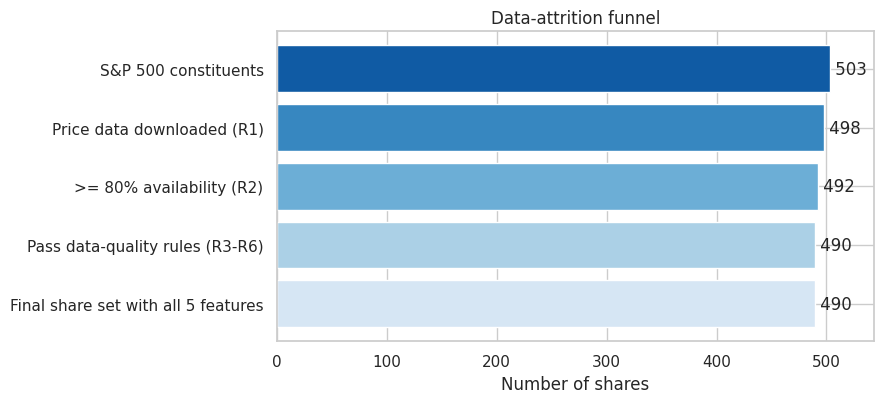

In [54]:
# Chart: how many shares are left after each step, from the 503 index members to the final set.
stage_R12 = ~rules[[R["R1"], R["R2"]]].any(axis=1)
stage_all = stage_R12 & ~rules[[R["R3"], R["R4"], R["R5"], R["R6"]]].any(axis=1)
funnel = pd.Series(
    {
        "S&P 500 constituents": len(tickers),
        "Price data downloaded (R1)": int((~rules[R["R1"]]).sum()),
        f">= {AVAIL_THRESHOLD:.0%} availability (R2)": int(stage_R12.sum()),
        "Pass data-quality rules (R3-R6)": int(stage_all.sum()),
        "Final share set with all 5 features": len(features_final),
    }
)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=sns.color_palette("Blues_r", len(funnel))[::-1])
for y, v in enumerate(funnel.values[::-1]):
    ax.text(v, y, f" {v}", va="center")
ax.set_xlim(0, len(tickers) * 1.08)
ax.set_xlabel("Number of shares")
ax.set_title("Data-attrition funnel")
plt.tight_layout()
plt.show()

# Output:
# 503 constituents, 498 with price data (R1), 492 above 80% availability (R2), 490 after the
# data-quality rules (R3 to R6) and 490 in the final set with all five features.

#### 1.5.2 Event threshold, no-event handling, sufficient history and the common share set

In [55]:
# (1) Threshold alignment. Rebuild the event rule separately (shift first, then roll) and compare it
# with the event matrix from 1.4.
example = next(t for t in ["AAPL"] + list(event.columns) if t in last_event_date.dropna().index)

independent_threshold = HIGH_VOL_MULT * vol.shift(1).rolling(BASE_WINDOW).mean()
independent_event = vol > independent_threshold
n_mismatch = int((independent_event != event).to_numpy().sum())
print("Event flags that differ from the independent rebuild:", n_mismatch)
assert n_mismatch == 0

# Strict inequality: a volume exactly equal to the threshold is not an event.
at_threshold = vol == threshold
print("Share-days with volume exactly equal to the threshold:", int(at_threshold.to_numpy().sum()),
      "| of which flagged:", int((at_threshold & event).to_numpy().sum()))
assert not (at_threshold & event).to_numpy().any()

# No look-ahead: changing a day's own volume should not change that day's baseline, but it should
# change the next day's.
t_idx = window_dates[-5]
t_next = vol.index[vol.index.get_loc(t_idx) + 1]
vol_perturbed = vol[example].copy()
vol_perturbed.loc[t_idx] *= 10
baseline_perturbed = vol_perturbed.rolling(BASE_WINDOW).mean().shift(1)
assert np.isclose(baseline_perturbed.loc[t_idx], baseline.loc[t_idx, example])
assert not np.isclose(baseline_perturbed.loc[t_next], baseline.loc[t_next, example])
print(f"No look-ahead: a 10x volume change on {t_idx.date()} leaves that day's baseline unchanged and moves {t_next.date()}'s.")

# Spot check three random shares against a plain loop over the previous 20 sessions.
rng = np.random.default_rng(42)
for t in rng.choice(event.columns, min(3, len(event.columns)), replace=False):
    v = vol[t].to_numpy(dtype=float)
    naive = np.zeros(len(v), dtype=bool)
    for i in range(BASE_WINDOW, len(v)):
        prev = v[i - BASE_WINDOW : i]
        naive[i] = np.isfinite(v[i]) and np.isfinite(prev).all() and v[i] > HIGH_VOL_MULT * prev.mean()
    assert np.array_equal(naive, event[t].fillna(False).to_numpy()), f"Mismatch for {t}"
print("Plain-loop spot checks passed for 3 random shares.")

# Recency and Frequency must come from the same event matrix as the rebuild.
last_event_check = pd.to_datetime(independent_event.apply(lambda s: s.index[s.to_numpy()].max() if s.any() else pd.NaT))
recency_check = (observation_date - last_event_check).dt.days
frequency_check = independent_event.loc[window_dates].sum()
assert np.array_equal(recency_check.reindex(recency.index).to_numpy(dtype=float), recency.to_numpy(dtype=float), equal_nan=True)
assert np.array_equal(frequency_check.reindex(frequency.index).to_numpy(), frequency.to_numpy())
print("Recency and Frequency match the independent rebuild for all", len(frequency), "shares.")

# Frequency only looks at the latest 60 sessions, while Recency looks at the whole history.
last_in_window = last_event_date >= window_dates.min()
assert ((frequency > 0) == last_in_window).all()
display(pd.DataFrame(
    {"Shares": [int(last_in_window.sum()), int((~last_in_window).sum())]},
    index=[f"Latest event inside the {ACTIVITY_WINDOW}-session window (Frequency >= 1)",
           "Latest event before the window (Frequency = 0, Recency still defined)"],
))
display(features_final.loc[features_final["Frequency"] == 0, ["Company", "Recency", "Frequency", "last_high_volume_date"]])

Event flags that differ from the independent rebuild: 0
Share-days with volume exactly equal to the threshold: 1 | of which flagged: 0
No look-ahead: a 10x volume change on 2024-12-24 leaves that day's baseline unchanged and moves 2024-12-26's.
Plain-loop spot checks passed for 3 random shares.
Recency and Frequency match the independent rebuild for all 490 shares.


,Shares
Latest event inside the 60-session window (Frequency >= 1),480
"Latest event before the window (Frequency = 0, Recency still defined)",10


,Company,Recency,Frequency,last_high_volume_date
AZO,AutoZone,98,0,2024-09-24
COR,Cencora,102,0,2024-09-20
CB,Chubb Limited,102,0,2024-09-20
DUK,Duke Energy,102,0,2024-09-20
FCX,Freeport-McMoRan,96,0,2024-09-26
HRL,Hormel Foods,102,0,2024-09-20
MKC,McCormick & Company,91,0,2024-10-01
MDT,Medtronic,102,0,2024-09-20
NVDA,Nvidia,222,0,2024-05-23
WEC,WEC Energy Group,151,0,2024-08-02


In [56]:
# (2) No-event handling. Recency is the number of days since a share's latest event. If a share
# never had an event, Recency is missing (never 0, which would mean an event today) and Frequency is
# 0. The function below applies the same rule as 1.4 to one volume series, so it can be tested on
# the real example and on two made-up series: flat volume (never above 2x its own average) and a
# single spike on the observation date.
def recency_frequency(vol_series, obs_date, win_dates):
    base = vol_series.rolling(BASE_WINDOW).mean().shift(1)
    ev = vol_series > HIGH_VOL_MULT * base
    last = vol_series.index[ev.to_numpy()].max() if ev.any() else pd.NaT
    rec = (obs_date - last).days if pd.notna(last) else np.nan
    return rec, int(ev.loc[win_dates].sum())

r_real, f_real = recency_frequency(vol[example], observation_date, window_dates)
flat = pd.Series(1_000_000.0, index=vol.index)
r_flat, f_flat = recency_frequency(flat, observation_date, window_dates)
spike = flat.copy()
spike.loc[observation_date] = 5_000_000.0
r_spike, f_spike = recency_frequency(spike, observation_date, window_dates)

display(pd.DataFrame(
    {"Recency": [r_real, r_flat, r_spike], "Frequency": [f_real, f_flat, f_spike]},
    index=[f"{example} (real data)", "Flat volume (no event)", "Spike on observation date"],
))
assert r_real == recency[example] and f_real == frequency[example]
assert np.isnan(r_flat) and f_flat == 0
assert r_spike == 0 and f_spike == 1

# Sessions without a full baseline can never be events, because NaN comparisons are False.
early = vol.index[:BASE_WINDOW]
print(f"Events flagged in the first {BASE_WINDOW} sessions (no baseline yet):", int(event.loc[early].to_numpy().sum()))
assert not event.loc[early].to_numpy().any()

print("Shares with no event in the whole history (Recency missing):", int(recency.isna().sum()))
print(f"Shares with no event in the latest {ACTIVITY_WINDOW} sessions (Frequency = 0):", int((frequency == 0).sum()))
print("Shares dropped because Recency is missing (rule F2):", n_fail_F2)

,Recency,Frequency
AAPL (real data),11.0000,2
Flat volume (no event),NaN,0
Spike on observation date,0.0000,1


Events flagged in the first 20 sessions (no baseline yet): 0
Shares with no event in the whole history (Recency missing): 0
Shares with no event in the latest 60 sessions (Frequency = 0): 10
Shares dropped because Recency is missing (rule F2): 0


In [57]:
# (3) Enough history for both the 20-session baseline and the 60-session window. The first window
# day needs 20 valid sessions before it, so each share needs 80 valid sessions ending on the
# observation date. Beta needs at least 52 paired weekly returns.
needed_dates = calendar[calendar <= observation_date][-RFM_HISTORY:]
first_window_day = window_dates[0]
assert len(needed_dates) == RFM_HISTORY and needed_dates[BASE_WINDOW] == first_window_day

hist_check = pd.DataFrame({
    "valid_volume_sessions_of_80": volume_v.loc[needed_dates].notna().sum(),
    "valid_close_sessions_of_80": close_v.loc[needed_dates].notna().sum(),
    "first_valid_session": history.loc[volume_v.columns, "first_date"],
    "first_date_with_baseline": baseline.apply(pd.Series.first_valid_index),
    "baseline_valid_every_window_day": baseline.loc[window_dates].notna().all(),
    "window_close_and_volume_valid": volume_v.loc[window_dates].notna().all() & close_v.loc[window_dates].notna().all(),
    "valid_weekly_returns": weekly_ret.count(),
    "paired_weeks_for_beta": beta_df["Paired_weeks"],
})
hist_check["ok_20_session_baseline"] = (hist_check["first_date_with_baseline"] <= first_window_day) & hist_check["baseline_valid_every_window_day"]
hist_check["ok_60_session_window"] = (
    (hist_check["valid_volume_sessions_of_80"] == RFM_HISTORY)
    & (hist_check["valid_close_sessions_of_80"] == RFM_HISTORY)
    & hist_check["window_close_and_volume_valid"]
)
hist_check["ok_weekly_returns"] = (hist_check["valid_weekly_returns"] >= MIN_WEEKS) & (hist_check["paired_weeks_for_beta"] >= MIN_WEEKS)
hist_check.to_csv(f"{DATA_DIR}/history_sufficiency_checks.csv")

print(f"Observation date: {observation_date.date()} | sessions needed: {RFM_HISTORY} "
      f"({needed_dates[0].date()} to {observation_date.date()}) | first window day: {first_window_day.date()}")
print(f"Retained shares: {len(hist_check)}")
for col in ["ok_20_session_baseline", "ok_60_session_window", "ok_weekly_returns"]:
    print(f"  {col}: {int(hist_check[col].sum())} pass, {int((~hist_check[col]).sum())} fail")
print("Latest date at which any retained share first has a valid baseline:", hist_check["first_date_with_baseline"].max().date(),
      f"(window starts {first_window_day.date()})")
assert hist_check[["ok_20_session_baseline", "ok_60_session_window", "ok_weekly_returns"]].all().all()

print("\nShares with the shortest history (these are the ones most at risk of failing):")
display(hist_check.sort_values("first_date_with_baseline", ascending=False)
        [["first_valid_session", "first_date_with_baseline", "valid_weekly_returns", "paired_weeks_for_beta"]].head(6))

Observation date: 2024-12-31 | sessions needed: 80 (2024-09-09 to 2024-12-31) | first window day: 2024-10-07
Retained shares: 490
  ok_20_session_baseline: 490 pass, 0 fail
  ok_60_session_window: 490 pass, 0 fail
  ok_weekly_returns: 490 pass, 0 fail
Latest date at which any retained share first has a valid baseline: 2021-08-26 (window starts 2024-10-07)

Shares with the shortest history (these are the ones most at risk of failing):


,first_valid_session,first_date_with_baseline,valid_weekly_returns,paired_weeks_for_beta
HOOD,2021-07-29,2021-08-26,178,178
APP,2021-04-15,2021-05-13,193,193
COIN,2021-04-14,2021-05-12,193,193
EXE,2021-02-10,2021-03-11,202,202
NUE,2021-01-04,2021-02-02,207,207
NRG,2021-01-04,2021-02-02,207,207


In [58]:
# (4) Common valid share set. The risk-return and activity solutions are compared on exactly the
# same shares, so any difference between them comes from the features and not from a different
# sample.
valid_rr = mean_weekly_return.notna() & beta.notna()
valid_rfm = recency.notna() & frequency.notna() & monetary.notna()
valid_rfm = valid_rfm.reindex(valid_rr.index)
common_set = valid_rr.index[valid_rr & valid_rfm]

display(pd.DataFrame({"Shares": {
    "Constituents": len(tickers),
    "Passed daily validation (R1-R6)": len(valid_tickers),
    "Valid for risk-return features (return and beta)": int(valid_rr.sum()),
    "Valid for activity features (Recency, Frequency, Monetary)": int(valid_rfm.sum()),
    "Valid for both = common valid share set": len(common_set),
    "Valid for one lens only (would be dropped)": int((valid_rr ^ valid_rfm).sum()),
    "Dropped at the feature stage (F1/F2) after passing R1-R6": len(valid_tickers) - len(common_set),
}}))
assert set(common_set) == set(features_final.index) and set(common_set) <= set(valid_tickers)
assert not features_final[core].isna().any().any()

common_df = features_final[["Company", "Sector"]].copy()
common_df.index.name = "Ticker"
common_df.to_csv(f"{DATA_DIR}/common_valid_share_set.csv")
saved_features = pd.read_csv(f"{DATA_DIR}/features_table.csv", index_col=0)
assert list(saved_features.index) == list(features_final.index) == list(common_df.index)
print(f"Common valid share set: {len(common_set)} shares. features_table.csv, which Task 2 loads, contains exactly these shares.")

,Shares
Constituents,503
Passed daily validation (R1-R6),490
Valid for risk-return features (return and beta),490
"Valid for activity features (Recency, Frequency, Monetary)",490
Valid for both = common valid share set,490
Valid for one lens only (would be dropped),0
Dropped at the feature stage (F1/F2) after passing R1-R6,0


Common valid share set: 490 shares. features_table.csv, which Task 2 loads, contains exactly these shares.


#### 1.5.3 Worked RFM example: AAPL

In [59]:
# Worked example for one share (AAPL): build Recency, Frequency and Monetary step by step and check
# each one against the pipeline values from 1.4.
example = next(t for t in ["AAPL"] + list(event.columns) if t in last_event_date.dropna().index)
ex_vol = vol[example]
ev_date = last_event_date[example]
pos = ex_vol.index.get_loc(ev_date)
prev20 = ex_vol.iloc[pos - BASE_WINDOW : pos]

print(f"Example share: {example}")
print(f"Latest high-volume day: {ev_date.date()} | volume = {ex_vol.iloc[pos]:,.0f}")
print(
    f"Mean of previous 20 sessions = {prev20.mean():,.0f} -> threshold (2x) = {HIGH_VOL_MULT * prev20.mean():,.0f}"
)
print(
    f"Recency = {observation_date.date()} - {ev_date.date()} = {(observation_date - ev_date).days} calendar days"
)
assert (
    ex_vol.iloc[pos] > HIGH_VOL_MULT * prev20.mean() and (observation_date - ev_date).days == recency[example]
)

ex_window = pd.DataFrame(
    {
        "Close": close_v.loc[window_dates, example],
        "Volume": ex_vol.loc[window_dates],
        "Threshold": threshold.loc[window_dates, example],
        "High_volume": event.loc[window_dates, example],
    }
)
display(ex_window[ex_window["High_volume"]])
print(f"Frequency = {int(ex_window['High_volume'].sum())}")

m_manual = float(np.dot(ex_window["Close"].to_numpy(), ex_window["Volume"].to_numpy()))
print(f"Monetary = sum(Close x Volume over {ACTIVITY_WINDOW} sessions) = ${m_manual:,.0f}")
assert int(ex_window["High_volume"].sum()) == frequency[example] and np.isclose(m_manual, monetary[example])

# Output:
# AAPL's latest high-volume day is 2024-12-20 with a volume of 147.5 million, against a threshold of
# 90.0 million (2 x the previous 20-day average of 45.0 million).
# Recency is 11 calendar days to 2024-12-31. Two days in the window passed the threshold (2024-11-25
# and 2024-12-20), so Frequency is 2.
# Monetary is about $623.3 billion and the dot-product check matches.

Example share: AAPL
Latest high-volume day: 2024-12-20 | volume = 147,495,300
Mean of previous 20 sessions = 45,004,605 -> threshold (2x) = 90,009,210
Recency = 2024-12-31 - 2024-12-20 = 11 calendar days


,Close,Volume,Threshold,High_volume
Date,,,,
2024-11-25,232.8700,90152800,"87,641,480.0000",True
2024-12-20,254.4900,147495300,"90,009,210.0000",True


Frequency = 2
Monetary = sum(Close x Volume over 60 sessions) = $623,303,377,707


In [60]:
# AAPL summary: hand calculation vs pipeline value for each RFM feature, followed by the share's
# full feature row (the five features used in Task 2).
worked = pd.DataFrame(
    {
        "Hand calculation": [(observation_date - ev_date).days, int(ex_window["High_volume"].sum()), m_manual],
        "Pipeline value (1.4)": [recency[example], frequency[example], monetary[example]],
    },
    index=["Recency (calendar days)", "Frequency (days in window)", "Monetary (USD)"],
)
worked["Match"] = np.isclose(worked["Hand calculation"].astype(float), worked["Pipeline value (1.4)"].astype(float))
assert worked["Match"].all()
display(worked.assign(**{c: worked[c].map("{:,.0f}".format) for c in ["Hand calculation", "Pipeline value (1.4)"]}))
display(features_final.loc[[example], core + ["last_high_volume_date"]])

,Hand calculation,Pipeline value (1.4),Match
Recency (calendar days),11,11,True
Frequency (days in window),2,2,True
Monetary (USD),"623,303,377,707","623,303,377,707",True


,mean_weekly_return,weekly_beta,Recency,Frequency,Monetary,last_high_volume_date
AAPL,0.0039,1.1748,11,2,"623,303,377,706.5842",2024-12-20


#### 1.5.4 What each metric captures and a summary of the feature values

In [61]:
# Summary statistics of the five features in their original units, plus skewness. Also check how
# much log1p reduces the skew of Monetary.
summary = features_final[core].describe().T
summary["skew"] = features_final[core].skew()
display(summary)
summary.to_csv(f"{DATA_DIR}/feature_summary.csv")
print("Skew of log1p(Monetary):", round(float(np.log1p(features_final["Monetary"]).skew()), 3))

# Output:
# The mean weekly return is about 0.29% and beta averages 0.98. Recency has a median of 11 days with
# a long tail up to 222, Frequency averages about 3 and Monetary averages $39.8 billion.
# Monetary is by far the most skewed (11.65), then Recency (3.61). After log1p the skew of Monetary
# falls to 1.07.

,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return,490.0000,0.0029,0.0027,-0.0045,0.0012,0.0027,0.0043,0.0178,0.9353
weekly_beta,490.0000,0.9823,0.4229,0.0555,0.6678,0.9547,1.1886,3.7786,1.2461
Recency,490.0000,20.5122,21.3432,4.0000,11.0000,11.0000,17.2500,222.0000,3.6114
Frequency,490.0000,2.9980,1.3300,0.0000,2.0000,3.0000,4.0000,8.0000,0.4122
Monetary,490.0000,"39,844,439,243.4305","128,892,252,349.0320","1,297,482,617.0479","10,251,022,367.6052","16,796,672,784.0942","32,621,670,382.5271","1,847,697,379,221.8428",11.6497


Skew of log1p(Monetary): 1.066


In [62]:
# Find the most common latest high-volume date.
top_date = last_event_date.value_counts()
print(f"Most common latest-event date: {top_date.index[0].date()} for {int(top_date.iloc[0])} of {len(last_event_date)} shares ({top_date.iloc[0] / len(last_event_date):.0%})")

Most common latest-event date: 2024-12-20 for 354 of 490 shares (72%)


In [63]:
# Feature medians by GICS sector, so the summary is not dominated by a few very large or very
# volatile shares.
by_sector = features_final.groupby("Sector").agg(
    Shares=("Company", "size"),
    Median_weekly_return_pct=("mean_weekly_return", lambda s: s.median() * 100),
    Median_beta=("weekly_beta", "median"),
    Median_Recency_days=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_traded_value_per_day_USDm=("Monetary", lambda s: s.median() / ACTIVITY_WINDOW / 1e6),
).sort_values("Median_beta")
display(by_sector)
by_sector.to_csv(f"{DATA_DIR}/feature_summary_by_sector.csv")

,Shares,Median_weekly_return_pct,Median_beta,Median_Recency_days,Median_Frequency,Median_traded_value_per_day_USDm
Sector,,,,,,
Consumer Staples,32,0.1009,0.4689,11.0000,3.0000,295.0181
Utilities,30,0.1963,0.5111,11.0000,3.0000,183.4389
Health Care,58,0.1032,0.7591,11.0000,3.0000,333.8527
Energy,21,0.5761,0.8282,11.0000,2.0000,350.0260
Real Estate,30,0.2086,0.8805,11.0000,3.0000,150.5267
Communication Services,21,0.2949,0.9316,11.0000,4.0000,426.4014
Materials,23,0.1687,0.9352,11.0000,3.0000,229.5434
Industrials,78,0.2915,0.9992,11.0000,3.0000,242.8672
Financials,76,0.3318,1.0214,11.0000,3.0000,274.8141


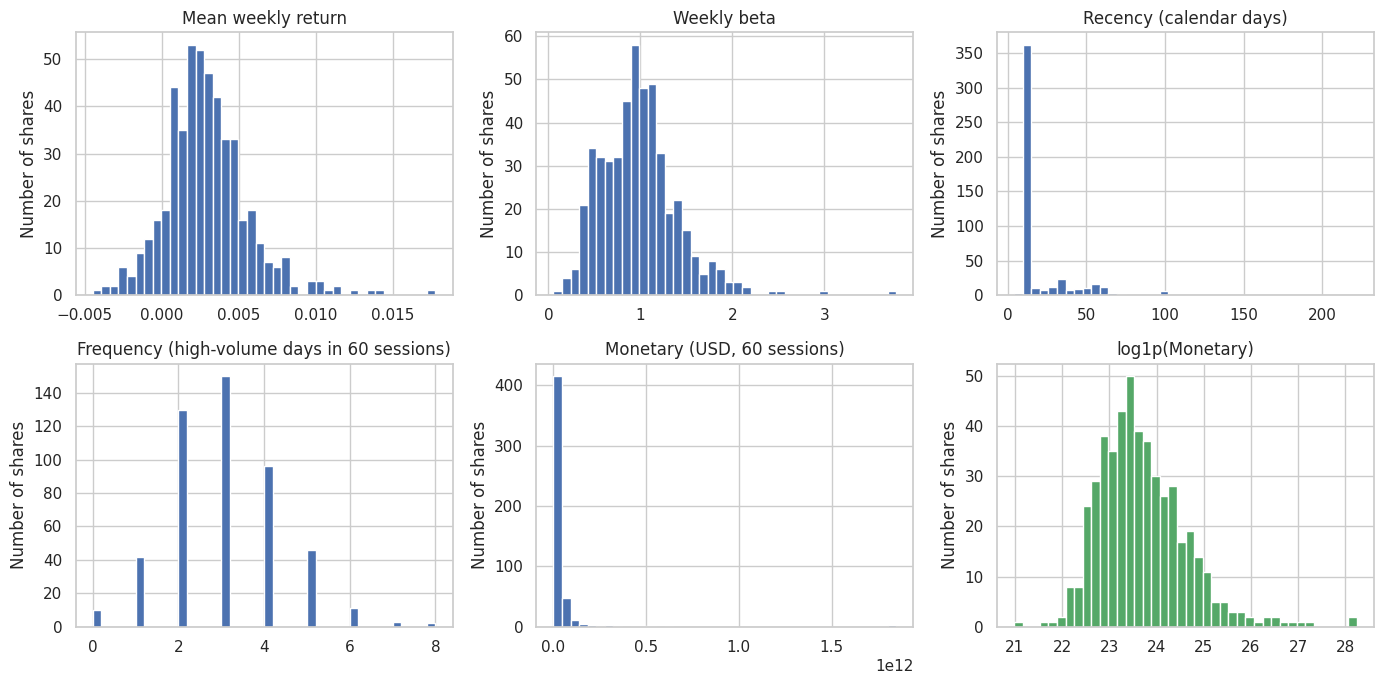

In [64]:
# Chart: histograms of the five features, with Monetary also shown after log1p (bottom right,
# green).
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plots = [
    ("mean_weekly_return", "Mean weekly return"),
    ("weekly_beta", "Weekly beta"),
    ("Recency", "Recency (calendar days)"),
    ("Frequency", "Frequency (high-volume days in 60 sessions)"),
    ("Monetary", "Monetary (USD, 60 sessions)"),
]
for ax, (col, title) in zip(axes.ravel(), plots):
    ax.hist(features_final[col], bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Number of shares")
axes.ravel()[5].hist(np.log1p(features_final["Monetary"]), bins=40, color="#55A868", edgecolor="white")
axes.ravel()[5].set_title("log1p(Monetary)")
axes.ravel()[5].set_ylabel("Number of shares")
plt.tight_layout()
plt.show()

# Output:
# Return and beta look roughly bell-shaped with a tail to the right. Recency is one tall bar near 11
# days with a few shares spread out to the right.
# Frequency sits mostly at 2 to 4 days. Raw Monetary is squashed against zero because of a few very
# large shares, while log1p(Monetary) looks much closer to a bell shape.

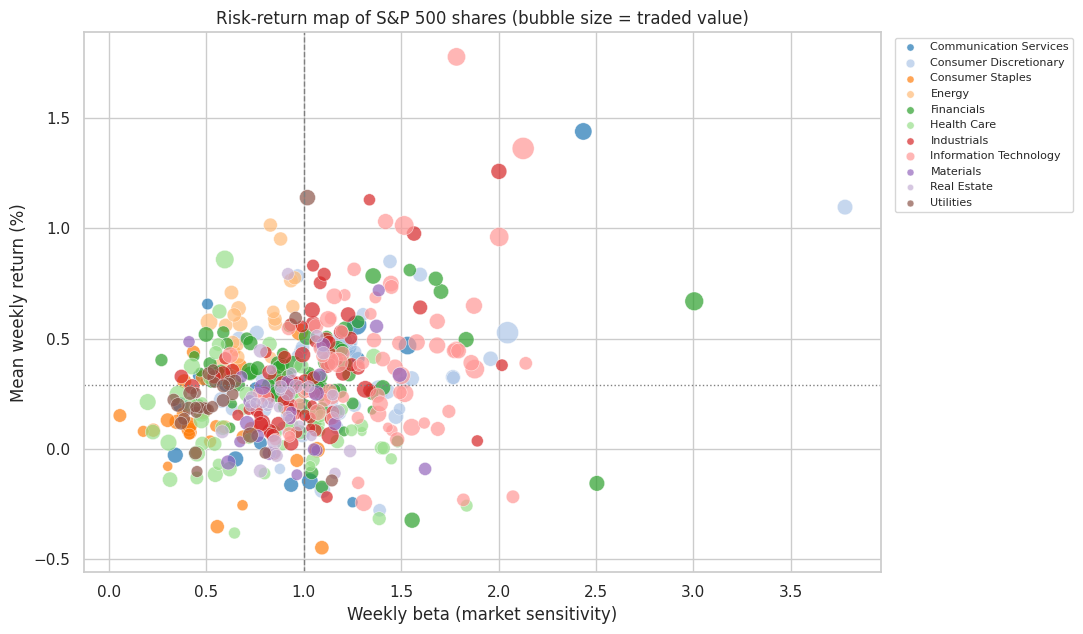

In [65]:
# Chart: risk-return map of the shares (beta on x, mean weekly return on y), coloured by sector,
# with bubble size showing traded value.
logM = np.log1p(features_final["Monetary"])
size = 12 + 240 * (logM - logM.min()) / (logM.max() - logM.min())
sectors = sorted(features_final["Sector"].unique())
colors = dict(zip(sectors, sns.color_palette("tab20", len(sectors))))
fig, ax = plt.subplots(figsize=(11, 6.5))
for sec in sectors:
    g = features_final[features_final["Sector"] == sec]
    ax.scatter(
        g["weekly_beta"],
        g["mean_weekly_return"] * 100,
        s=size[g.index],
        color=colors[sec],
        alpha=0.7,
        label=sec,
        edgecolor="white",
        lw=0.4,
    )
ax.axvline(1, color="grey", ls="--", lw=1)
ax.axhline(features_final["mean_weekly_return"].mean() * 100, color="grey", ls=":", lw=1)
ax.set_xlabel("Weekly beta (market sensitivity)")
ax.set_ylabel("Mean weekly return (%)")
ax.set_title("Risk-return map of S&P 500 shares (bubble size = traded value)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, markerscale=0.5)
plt.tight_layout()
plt.show()

# Output:
# Shares with a higher beta tend to have a slightly higher return, but the cloud is wide (the
# correlation is only 0.28, see the heatmap below).
# The top-right area is mostly Information Technology plus a few large Communication Services,
# Industrials and Consumer Discretionary names.
# The low-beta, low-return corner is mostly Consumer Staples and Health Care. CVNA stands out at a
# beta of about 3.8.

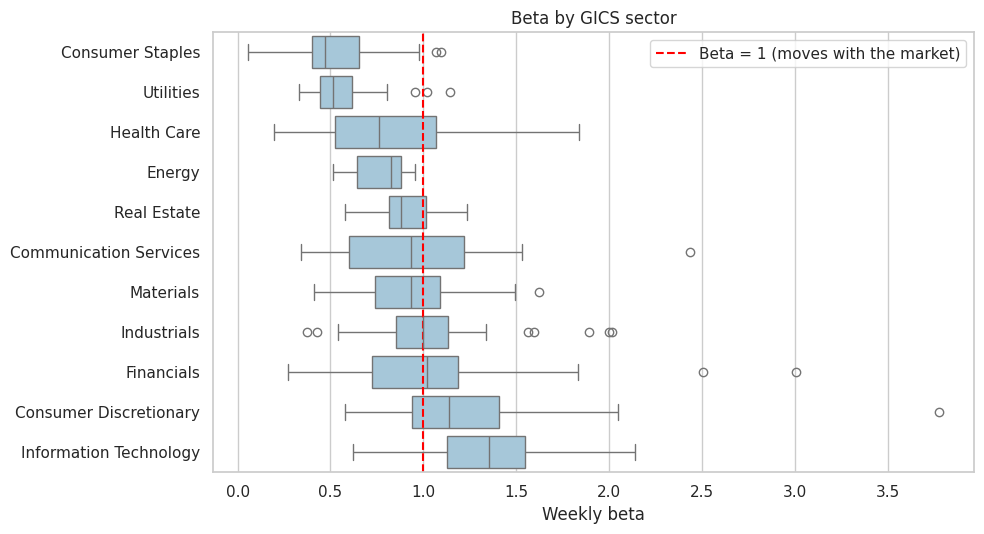

In [66]:
# Chart: boxplots of beta for each GICS sector, ordered by median beta, with a red line at beta = 1.
order = features_final.groupby("Sector")["weekly_beta"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=features_final, y="Sector", x="weekly_beta", order=order, color="#9ecae1", ax=ax)
ax.axvline(1, color="red", ls="--", label="Beta = 1 (moves with the market)")
ax.set_xlabel("Weekly beta")
ax.set_ylabel("")
ax.set_title("Beta by GICS sector")
ax.legend()
plt.tight_layout()
plt.show()

# Output:
# Consumer Staples (median about 0.47) and Utilities (about 0.5) have the lowest betas, well below
# 1.
# Information Technology has the highest median (about 1.35), followed by Consumer Discretionary
# (about 1.14).
# Health Care, Energy and Real Estate are below 1, and Industrials and Financials are around 1.
# Consumer Discretionary has the biggest outlier (CVNA at about 3.8).

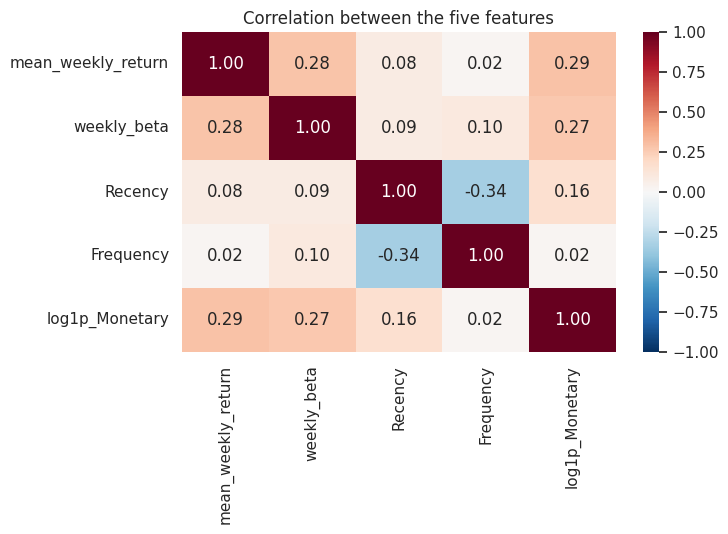

In [67]:
# Chart: correlation heatmap of the five features.
corr_in = features_final[core].copy()
corr_in["log1p_Monetary"] = np.log1p(corr_in.pop("Monetary"))
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(corr_in.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation between the five features")
plt.tight_layout()
plt.show()

# Output:
# Most pairs are only weakly related. The strongest is Recency and Frequency at -0.34 (shares with a
# recent spike tend to have more spikes).
# Return, beta and log1p(Monetary) have small positive links of 0.27 to 0.29 with each other. Apart
# from Recency, Frequency is almost unrelated to the other features.

#### 1.5.5 Limits of interpreting the features as investment signals

In [68]:
# Limit 1: estimation error. Compare the typical standard error of each estimate with how much the
# estimates differ between shares. If the two are similar, much of the apparent difference between
# shares is noise.
se_mean = weekly_ret.std() / np.sqrt(weekly_ret.count())
t_mean = mean_weekly_return / se_mean

def beta_standard_error(share):
    p = pd.concat([weekly_ret[share], bench_ret], axis=1, keys=["y", "x"]).dropna()
    x, y = p["x"].to_numpy(), p["y"].to_numpy()
    sxx = ((x - x.mean()) ** 2).sum()
    slope = ((x - x.mean()) * (y - y.mean())).sum() / sxx
    resid = y - (y.mean() + slope * (x - x.mean()))
    return float(np.sqrt((resid ** 2).sum() / (len(x) - 2) / sxx))

se_beta = pd.Series({s: beta_standard_error(s) for s in weekly_ret.columns})
precision_tbl = pd.DataFrame(
    {
        "Spread across shares (std)": [mean_weekly_return.std(), beta.std()],
        "Typical standard error (median)": [se_mean.median(), se_beta.median()],
        "Share of shares NOT distinguishable from the benchmark value": [(t_mean.abs() < 2).mean(), (((beta - 1) / se_beta).abs() < 2).mean()],
    },
    index=["Mean weekly return (vs 0)", "Weekly beta (vs 1)"],
)
display(precision_tbl)

# Limit 2: Recency is squeezed together because many shares share one latest event date.
top_date = last_event_date.value_counts()
print(f"Most common latest-event date: {top_date.index[0].date()} for {int(top_date.iloc[0])} of {len(last_event_date)} shares "
      f"({top_date.iloc[0] / len(last_event_date):.0%})")

,Spread across shares (std),Typical standard error (median),Share of shares NOT distinguishable from the benchmark value
Mean weekly return (vs 0),0.0027,0.0027,0.8898
Weekly beta (vs 1),0.4229,0.1009,0.4388


Most common latest-event date: 2024-12-20 for 354 of 490 shares (72%)


In [69]:
# Limit 3: Frequency depends on the chosen multiplier. Recount Frequency with other multipliers
# (same 20-session baseline and 60-session window) and compare the rankings with the 2x version used
# in the notebook.
rows = []
for m in [1.5, 2.0, 3.0]:
    f_m = (vol.loc[window_dates] > m * baseline.loc[window_dates]).sum()
    rows.append({"Multiplier": m, "Mean Frequency": f_m.mean(), "Shares with Frequency 0": int((f_m == 0).sum()),
                 "Rank correlation with 2x Frequency": f_m.corr(frequency, method="spearman")})
thr_sens = pd.DataFrame(rows).set_index("Multiplier")
display(thr_sens)
assert np.isclose(thr_sens.loc[2.0, "Mean Frequency"], frequency.mean())

,Mean Frequency,Shares with Frequency 0,Rank correlation with 2x Frequency
Multiplier,,,
1.5000,7.0980,0,0.3930
2.0000,2.9980,10,1.0000
3.0000,0.9204,176,0.3736


### Reproducibility record

In [70]:
# Save a record of the run: package versions, source timestamps, dates, parameters and final counts.
run_metadata = {
    "package_versions": PACKAGE_VERSIONS,
    "retrieval_info": retrieval_info,
    "study_period": {"start": START_DATE, "end_exclusive": END_DATE, "benchmark": BENCHMARK},
    "observation_date": str(observation_date.date()),
    "activity_window_sessions": {"first": str(window_dates.min().date()), "last": str(window_dates.max().date())},
    "parameters": {"base_window": BASE_WINDOW, "activity_window": ACTIVITY_WINDOW, "high_volume_multiplier": HIGH_VOL_MULT},
    "cleaning": {
        "minimum_availability": AVAIL_THRESHOLD,
        "price_imputation": False,
        "volume_imputation": False,
        "confirmed_unadjusted_split_tickers": CONFIRMED_UNADJUSTED_SPLIT_TICKERS,
        "minimum_weekly_observations": MIN_WEEKS,
    },
    "counts": {
        "constituents": len(tickers),
        "passed_daily_validation": len(valid_tickers),
        "final_common_feature_shares": len(features_final),
        "excluded_total": int((~log["included"]).sum()),
        "weekly_price_labels": int(len(weekly_adj)),
        "benchmark_weekly_returns": int(bench_ret.notna().sum()),
        "weekly_return_observations_min": int(n_weeks.min()),
        "weekly_return_observations_max": int(n_weeks.max()),
    },
}
run_metadata["validation"] = {
    "rule_failures": {k: int(rules[k].sum()) for k in rules.columns},
    "feature_stage_failures": {"too_few_weekly_returns": n_fail_F1, "no_event_in_history": n_fail_F2},
    "event_rule": f"volume > {HIGH_VOL_MULT} x mean of the previous {BASE_WINDOW} sessions (strict; tested day excluded)",
    "sessions_required_before_observation_date": RFM_HISTORY,
    "history_checks_passed": bool(hist_check[["ok_20_session_baseline", "ok_60_session_window", "ok_weekly_returns"]].all().all()),
    "common_valid_share_set": int(len(common_set)),
}
with open(f"{DATA_DIR}/run_metadata.json", "w") as f:
    json.dump(run_metadata, f, indent=2, default=str)
run_metadata["counts"]

{'constituents': 503,
 'passed_daily_validation': 490,
 'final_common_feature_shares': 490,
 'excluded_total': 13,
 'weekly_price_labels': 208,
 'benchmark_weekly_returns': 207,
 'weekly_return_observations_min': 178,
 'weekly_return_observations_max': 207}

In [71]:
# Zip the data folder so it can be downloaded (it downloads in Colab, otherwise the zip is just
# saved).
import shutil

shutil.make_archive("task1_data", "zip", DATA_DIR)
try:
    from google.colab import files

    files.download("task1_data.zip")
except ImportError:
    print("Not running in Colab - the zip is saved as task1_data.zip")

# Output:
# The zip download was triggered in Colab (task1_data.zip).

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 2: Clustering and Segmentation

In [72]:
# Import the clustering tools: Ward linkage and dendrogram from scipy, and scaling, K-means,
# agglomerative clustering, the cluster-quality scores and PCA from scikit-learn.
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [73]:
# Settings for Task 2: random seed, the range of k to test (2 to 8), number of K-means starts, and
# the rule for a usable k (at least 3 clusters and the smallest cluster holding at least 5% of the
# shares).
SEED = 42
K_RANGE = list(range(2, 9))
N_INIT = 50
MIN_K = 3
MIN_CLUSTER_SHARE = 0.05

# Index used to pick k among the feasible values: "silhouette" (used in the report),
# "calinski_harabasz" (higher is better) or "davies_bouldin" (lower is better). Change it to
# experiment.
SELECTION_METRIC = "silhouette"

DATA_DIR = "data"
FEATURES_CSV = f"{DATA_DIR}/features_table.csv"
os.makedirs(DATA_DIR, exist_ok=True)

In [74]:
# Load the feature table saved in Task 1 (asks for an upload in Colab if the file is missing) and
# check the columns, unique tickers and missing values.
if not os.path.exists(FEATURES_CSV):
    try:
        from google.colab import files

        print("Upload the features_table.csv created by the Task 1 notebook")
        for name, content in files.upload().items():
            if name.lower().endswith(".csv"):
                open(FEATURES_CSV, "wb").write(content)
                break
    except ImportError:
        raise FileNotFoundError(f"{FEATURES_CSV} not found - run Task 1 first")

features = pd.read_csv(FEATURES_CSV, index_col=0)

RAW_COLS = ["mean_weekly_return", "weekly_beta", "Recency", "Frequency", "Monetary"]
missing_cols = [c for c in RAW_COLS + ["Company", "Sector"] if c not in features.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"
assert features.index.is_unique, "Duplicate tickers"
assert features[RAW_COLS].notna().all().all(), "Missing feature values"

print(f"Loaded {len(features)} shares x {len(features.columns)} columns (the common share set from Task 1)")
display(features[["Company", "Sector"] + RAW_COLS].head())

# Output:
# 490 shares and 10 columns were loaded, and the preview matches the Task 1 feature table.

Loaded 490 shares x 10 columns (the common share set from Task 1)


,Company,Sector,mean_weekly_return,weekly_beta,Recency,Frequency,Monetary
MMM,3M,Industrials,0.0011,0.8691,11,4,"25,991,458,733.3420"
AOS,A. O. Smith,Industrials,0.0020,1.0428,11,2,"4,748,980,279.6021"
ABT,Abbott Laboratories,Health Care,0.0010,0.5835,11,1,"35,230,272,606.2744"
ABBV,AbbVie,Health Care,0.0037,0.4254,11,3,"68,370,537,641.6611"
ACN,Accenture,Information Technology,0.0024,1.1433,11,2,"51,994,299,403.1158"


### 2.1 Feature preparation

In [75]:
# Step 1: look at the skew of the raw features, plus Monetary after log1p.
skew_raw = features[RAW_COLS].skew()
skew_view = pd.DataFrame({"skew_raw": skew_raw})
skew_view.loc["log1p(Monetary)"] = np.log1p(features["Monetary"]).skew()
display(skew_view)

# Output:
# Monetary is the most skewed (11.65) and log1p brings it down to 1.07. Recency is also heavily
# skewed (3.61).
# Return (0.94), beta (1.25) and Frequency (0.41) are much less skewed.

,skew_raw
mean_weekly_return,0.9353
weekly_beta,1.2461
Recency,3.6114
Frequency,0.4122
Monetary,11.6497
log1p(Monetary),1.0657


In [76]:
# Step 2: count the outliers with two rules, the IQR rule (beyond 1.5 x IQR from the quartiles) and
# |z| > 3, and show the largest value of each feature.
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


check = features[RAW_COLS].copy()
check["log1p(Monetary)"] = np.log1p(check["Monetary"])
outlier_table = pd.DataFrame(
    {
        "IQR outliers": check.apply(lambda s: int(iqr_outliers(s).sum())),
        "IQR outliers %": check.apply(lambda s: iqr_outliers(s).mean() * 100),
        "|z| > 3": check.apply(lambda s: int((((s - s.mean()) / s.std()).abs() > 3).sum())),
        "Largest value": check.max(),
        "Largest share": check.idxmax(),
    }
)
display(outlier_table)

# Output:
# Recency has by far the most outliers (102 by the IQR rule, 20.8%), because most shares have the
# same Recency of about 11 days.
# Monetary has 47 IQR outliers, which drops to 13 after log1p. Return has 16, beta 11 and Frequency
# only 2.
# The largest values belong to SMCI (return 0.0178), CVNA (beta 3.78), NVDA (Recency 222), CI
# (Frequency 8) and TSLA (Monetary).

,IQR outliers,IQR outliers %,|z| > 3,Largest value,Largest share
mean_weekly_return,16,3.2653,6,0.0178,SMCI
weekly_beta,11,2.2449,4,3.7786,CVNA
Recency,102,20.8163,11,222.0000,NVDA
Frequency,2,0.4082,5,8.0000,CI
Monetary,47,9.5918,5,"1,847,697,379,221.8428",TSLA
log1p(Monetary),13,2.6531,6,28.2450,TSLA


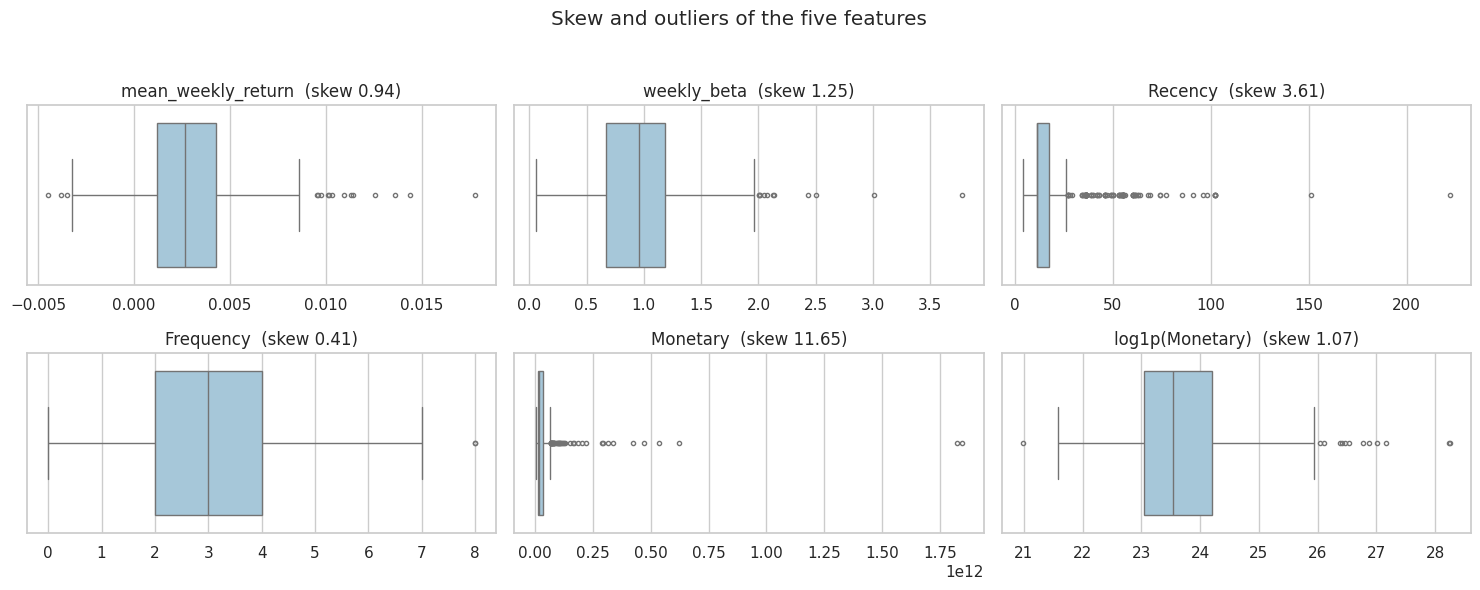

In [77]:
# Chart: boxplots of each feature to show skew and outliers (Monetary before and after log1p).
plot_cols = RAW_COLS + ["log1p(Monetary)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(x=check[col], ax=ax, color="#9ecae1", fliersize=3)
    ax.set_title(f"{col}  (skew {check[col].skew():.2f})")
    ax.set_xlabel("")
fig.suptitle("Skew and outliers of the five features")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Output:
# Recency and raw Monetary show a long line of outliers far to the right, and log1p pulls most of
# the Monetary outliers back in.
# Frequency has a tidy box (2 to 4) with a couple of outliers at 8. Return and beta each have a few
# high outliers, with CVNA far to the right on beta.

In [78]:
# Step 3: build the two separate feature matrices: risk-return (mean return and beta) and trading
# activity (Recency, Frequency and log1p Monetary).
X_rr = features[["mean_weekly_return", "weekly_beta"]].copy()
X_rfm = features[["Recency", "Frequency"]].copy()
X_rfm["log1p_Monetary"] = np.log1p(features["Monetary"])

assert X_rr.index.equals(X_rfm.index)
print("Risk-return matrix:", X_rr.shape, "| Activity (RFM) matrix:", X_rfm.shape)
display(X_rr.head(3))
display(X_rfm.head(3))

# Output:
# The risk-return matrix is 490 x 2 and the activity matrix is 490 x 3, with the same shares in
# both. The previews show MMM, AOS and ABT.

Risk-return matrix: (490, 2) | Activity (RFM) matrix: (490, 3)


,mean_weekly_return,weekly_beta
MMM,0.0011,0.8691
AOS,0.0020,1.0428
ABT,0.0010,0.5835


,Recency,Frequency,log1p_Monetary
MMM,11,4,23.9810
AOS,11,2,22.2812
ABT,11,1,24.2852


In [79]:
# Step 4: standardise each matrix separately (mean 0, standard deviation 1) so no feature dominates
# because of its scale, then check the means and standard deviations.
scaler_rr, scaler_rfm = StandardScaler(), StandardScaler()
Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)
Z_rfm = pd.DataFrame(scaler_rfm.fit_transform(X_rfm), index=X_rfm.index, columns=X_rfm.columns)

display(
    pd.concat({"risk-return": Z_rr.agg(["mean", "std"]).T, "activity (RFM)": Z_rfm.agg(["mean", "std"]).T})
)

# Output:
# Every standardised feature has a mean of 0 and a standard deviation of about 1.001 (a tiny bit
# above 1 because the scaler divides by n and pandas divides by n - 1).

mean    std
risk-return    mean_weekly_return  0.0000 1.0010
               weekly_beta         0.0000 1.0010
activity (RFM) Recency            -0.0000 1.0010
               Frequency          -0.0000 1.0010
               log1p_Monetary     -0.0000 1.0010

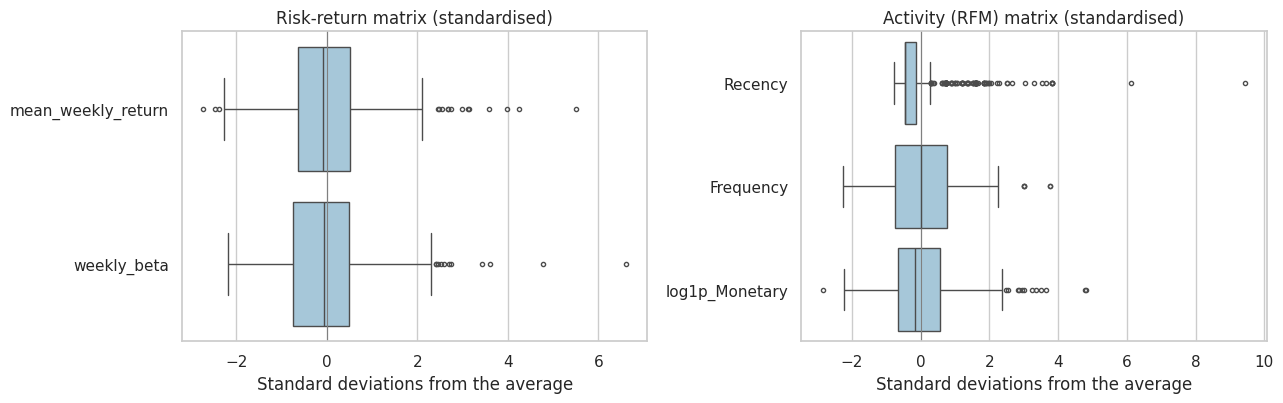

In [80]:
# Chart: boxplots of the standardised features to see which shares are extreme.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, Z, title in zip(
    axes, [Z_rr, Z_rfm], ["Risk-return matrix (standardised)", "Activity (RFM) matrix (standardised)"]
):
    sns.boxplot(data=Z, orient="h", ax=ax, color="#9ecae1", fliersize=3)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("Standard deviations from the average")
plt.tight_layout()
plt.show()

# Output:
# After scaling the features are on the same scale. Recency has the most extreme points (one at
# about 9.5 standard deviations).
# On the risk-return side the biggest points are about 5.5 for return and 6.6 for beta. These
# extreme shares were kept.

### 2.2 Agglomerative clustering (Ward linkage)

In [81]:
# Build the Ward hierarchy for each matrix and define a helper to cut it into k clusters. As a
# check, scikit-learn's Ward is compared with scipy's using the adjusted Rand index (ARI).
link_rr = linkage(Z_rr.to_numpy(), method="ward", metric="euclidean")
link_rfm = linkage(Z_rfm.to_numpy(), method="ward", metric="euclidean")


def ward_labels(link, k):
    return fcluster(link, t=k, criterion="maxclust") - 1


for name, Z, link in [("risk-return", Z_rr, link_rr), ("RFM", Z_rfm, link_rfm)]:
    sk = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(Z)
    print(
        f"{name}: scikit-learn Ward agrees with scipy Ward (ARI = {adjusted_rand_score(sk, ward_labels(link, 4)):.3f})"
    )

# Output:
# ARI is 1.000 for both matrices, so scikit-learn and scipy give identical Ward groups.

risk-return: scikit-learn Ward agrees with scipy Ward (ARI = 1.000)
RFM: scikit-learn Ward agrees with scipy Ward (ARI = 1.000)


In [82]:
# Compare k = 2 to 8 for Ward on each matrix using the silhouette score (how well shares fit their
# own cluster, higher is better), the Calinski-Harabasz and Davies-Bouldin indices (see 2.3.1), the
# within-cluster spread and the cluster sizes.
def within_ss(Z, labels):
    Za = Z.to_numpy()
    return float(
        sum(((Za[labels == c] - Za[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))
    )


def diagnostics(Z, label_fn):
    rows = []
    for k in K_RANGE:
        lab = label_fn(k)
        sizes = np.bincount(lab)
        rows.append(
            {
                "k": k,
                "silhouette": silhouette_score(Z, lab),
                "calinski_harabasz": calinski_harabasz_score(Z, lab),
                "davies_bouldin": davies_bouldin_score(Z, lab),
                "within_SS": within_ss(Z, lab),
                "smallest_cluster": int(sizes.min()),
                "smallest_pct": sizes.min() / len(lab) * 100,
                "largest_pct": sizes.max() / len(lab) * 100,
                "sizes": " / ".join(map(str, sorted(sizes, reverse=True))),
            }
        )
    return pd.DataFrame(rows)


diag_ward_rr = diagnostics(Z_rr, lambda k: ward_labels(link_rr, k))
diag_ward_rfm = diagnostics(Z_rfm, lambda k: ward_labels(link_rfm, k))

print("Ward - risk-return matrix")
display(diag_ward_rr)
print("Ward - activity (RFM) matrix")
display(diag_ward_rfm)

# Output:
# Risk-return: the best silhouette is at k = 2 (0.508), but that is a 454 / 36 split. From k = 3 the
# scores are lower (0.26 to 0.32), with k = 6 at 0.324 and k = 5 at 0.319.
# From k = 6 the smallest cluster has only 6 shares (1.2%).
# Activity (RFM): the best silhouette is also at k = 2 (0.361), followed by k = 6 (0.320) and k = 5
# (0.312). The smallest cluster is 43 shares at k = 4 and only 10 shares from k = 5.

Ward - risk-return matrix


,k,silhouette,calinski_harabasz,davies_bouldin,within_SS,smallest_cluster,smallest_pct,largest_pct,sizes
0,2,0.5079,178.4150,0.8420,717.6309,36,7.3469,92.6531,454 / 36
1,3,0.2618,193.7924,1.0210,545.6990,36,7.3469,67.5510,331 / 123 / 36
2,4,0.2944,223.9319,1.0381,411.3679,36,7.3469,35.7143,175 / 156 / 123 / 36
3,5,0.3191,229.1454,0.9009,339.1169,36,7.3469,35.7143,175 / 123 / 111 / 45 / 36
4,6,0.3243,235.5840,0.8797,285.4048,6,1.2245,35.7143,175 / 123 / 111 / 45 / 30 / 6
5,7,0.3064,232.3620,0.8611,252.1559,6,1.2245,35.7143,175 / 123 / 91 / 45 / 30 / 20 / 6
6,8,0.2936,233.6519,0.9499,223.0677,6,1.2245,25.1020,123 / 106 / 91 / 69 / 45 / 30 / 20 / 6


Ward - activity (RFM) matrix


,k,silhouette,calinski_harabasz,davies_bouldin,within_SS,smallest_cluster,smallest_pct,largest_pct,sizes
0,2,0.3607,163.0552,1.1936,"1,101.8421",92,18.7755,81.2245,398 / 92
1,3,0.3072,182.2134,1.1694,840.8122,92,18.7755,51.2245,251 / 147 / 92
2,4,0.2927,170.9790,1.0143,715.1802,43,8.7755,42.4490,208 / 147 / 92 / 43
3,5,0.3118,177.8825,0.9753,595.8481,10,2.0408,42.4490,208 / 147 / 82 / 43 / 10
4,6,0.3200,186.6820,0.9458,501.9578,10,2.0408,42.4490,208 / 127 / 82 / 43 / 20 / 10
5,7,0.2991,189.5339,0.9241,438.2227,10,2.0408,28.9796,142 / 127 / 82 / 66 / 43 / 20 / 10
6,8,0.3050,192.4161,0.9075,387.4105,10,2.0408,28.9796,142 / 82 / 70 / 66 / 57 / 43 / 20 / 10


In [83]:
# Choose k with one rule for every solution: k must be at least 3, the smallest cluster must hold at
# least 5% of the shares, and then the best index value wins (the highest silhouette by default).
# Davies-Bouldin is the one index where lower is better.
def select_k(diag):
    feasible = diag[(diag["k"] >= MIN_K) & (diag["smallest_pct"] >= MIN_CLUSTER_SHARE * 100)]
    note = "highest silhouette among feasible k" if SELECTION_METRIC == "silhouette" else f"best {SELECTION_METRIC.replace('_', '-')}- among feasible k"
    if feasible.empty:
        feasible, note = diag[diag["k"] >= MIN_K], "no k met the 5% size rule, so the size rule was relaxed"
    ascending = SELECTION_METRIC == "davies_bouldin"
    return int(feasible.sort_values(SELECTION_METRIC, ascending=ascending).iloc[0]["k"]), note


k_ward_rr, note_ward_rr = select_k(diag_ward_rr)
k_ward_rfm, note_ward_rfm = select_k(diag_ward_rfm)
print(f"Selected k  ->  risk-return Ward: {k_ward_rr} | RFM Ward: {k_ward_rfm}")

# Output:
# Ward picks k = 5 for risk-return and k = 3 for RFM.
# For RFM, k = 3 has the selected silhouette of 0.3072. k = 4 is also feasible, with a smallest
# cluster of 8.78% of the shares, but k = 3 is selected because it has the highest silhouette.

Selected k  ->  risk-return Ward: 5 | RFM Ward: 3


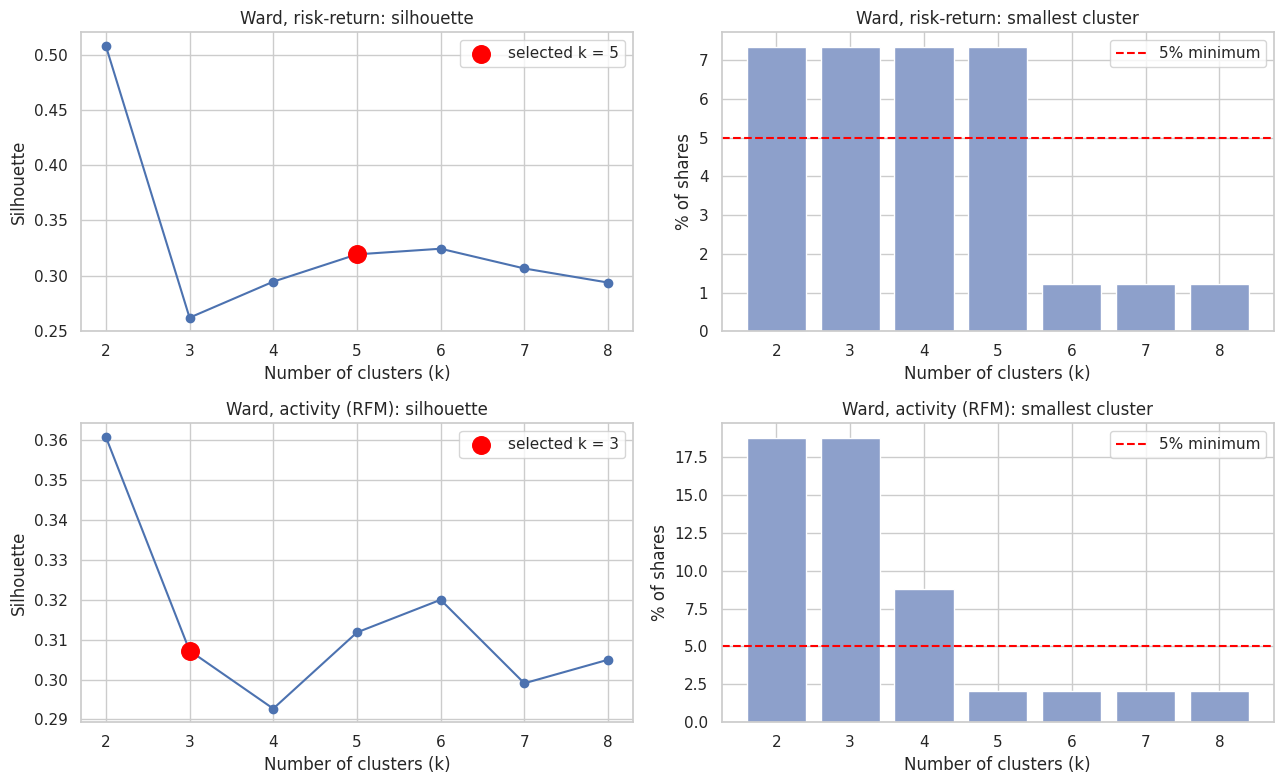

In [84]:
# Chart: silhouette and smallest-cluster size for k = 2 to 8 (the chosen k is marked in red).
def plot_diag(diag, k_sel, title, axes):
    axes[0].plot(diag["k"], diag["silhouette"], marker="o", color="#4C72B0")
    axes[0].scatter(
        [k_sel],
        diag.loc[diag["k"] == k_sel, "silhouette"],
        s=160,
        color="red",
        zorder=3,
        label=f"selected k = {k_sel}",
    )
    axes[0].set_title(f"{title}: silhouette")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Silhouette")
    axes[0].legend()
    axes[1].bar(diag["k"], diag["smallest_pct"], color="#8da0cb")
    axes[1].axhline(MIN_CLUSTER_SHARE * 100, color="red", ls="--", label=f"{MIN_CLUSTER_SHARE:.0%} minimum")
    axes[1].set_title(f"{title}: smallest cluster")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("% of shares")
    axes[1].legend()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_diag(diag_ward_rr, k_ward_rr, "Ward, risk-return", axes[0])
plot_diag(diag_ward_rfm, k_ward_rfm, "Ward, activity (RFM)", axes[1])
plt.tight_layout()
plt.show()

# Output:
# The top row is risk-return and the bottom row is RFM. In both, silhouette is highest at k = 2 and
# drops at k = 3. The red dots mark the chosen k (5 and 3).
# The smallest-cluster bars show why larger k were ruled out: risk-return falls under the 5% line
# from k = 6 and RFM from k = 5.

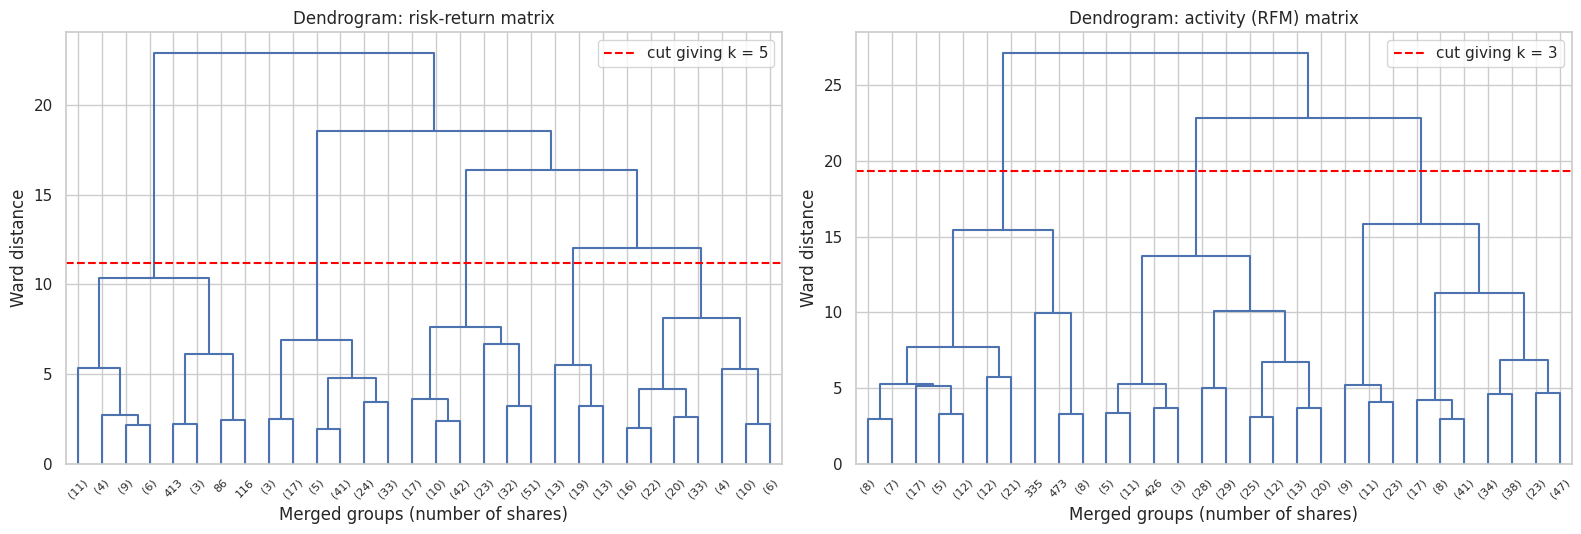

In [85]:
# Chart: dendrograms for each matrix (only the last 30 merges are drawn). The red dashed line shows
# the cut that gives the chosen k.
def plot_dendrogram(ax, link, k, title):
    dendrogram(
        link,
        truncate_mode="lastp",
        p=30,
        ax=ax,
        color_threshold=0,
        above_threshold_color="#4C72B0",
        show_leaf_counts=True,
        leaf_font_size=8,
    )
    cut = (link[-k, 2] + link[-(k - 1), 2]) / 2
    ax.axhline(cut, color="red", ls="--", label=f"cut giving k = {k}")
    ax.set_title(title)
    ax.set_xlabel("Merged groups (number of shares)")
    ax.set_ylabel("Ward distance")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
plot_dendrogram(axes[0], link_rr, k_ward_rr, "Dendrogram: risk-return matrix")
plot_dendrogram(axes[1], link_rfm, k_ward_rfm, "Dendrogram: activity (RFM) matrix")
plt.tight_layout()
plt.show()

# Output:
# The red line cuts the risk-return tree at about 11.2 to give 5 groups, and the RFM tree at about
# 19 to give 3 groups.
# The last merge happens at about 23 in the risk-return tree and about 27 in the RFM tree.
# The tree does not decide k on its own. The choice comes from the silhouette and the cluster sizes.

In [86]:
# Create the final Ward solutions with the chosen k. As a robustness check, repeat the RFM Ward
# using log1p(Recency) instead of Recency in days and compare the groups with ARI.
ward_rr = ward_labels(link_rr, k_ward_rr)
ward_rfm = ward_labels(link_rfm, k_ward_rfm)

X_rfm_logR = X_rfm.assign(Recency=np.log1p(X_rfm["Recency"]))
Z_rfm_logR = StandardScaler().fit_transform(X_rfm_logR)
ward_rfm_logR = ward_labels(linkage(Z_rfm_logR, method="ward", metric="euclidean"), k_ward_rfm)
ari_logR = adjusted_rand_score(ward_rfm, ward_rfm_logR)
print(f"ARI between Ward RFM (R in days) and Ward RFM (log1p of R): {ari_logR:.3f}")

# Output:
# The ARI between the two RFM versions is 0.897, so the groups are very similar when Recency is
# logged. How Recency is treated does not change the final clusters much.

ARI between Ward RFM (R in days) and Ward RFM (log1p of R): 0.897


### 2.3 K-means clustering

In [87]:
# Compare k = 2 to 8 for K-means on each matrix using silhouette, inertia (total squared distance to
# the centres, smaller is tighter) and cluster sizes. Every fit uses k-means++ with 50 starts and a
# fixed seed.
def kmeans_fit(Z, k, seed=SEED, n_init=N_INIT):
    return KMeans(n_clusters=k, init="k-means++", n_init=n_init, random_state=seed).fit(Z)


def kmeans_diagnostics(Z):
    rows = []
    for k in K_RANGE:
        km = kmeans_fit(Z, k)
        lab = km.labels_
        sizes = np.bincount(lab)
        rows.append(
            {
                "k": k,
                "silhouette": silhouette_score(Z, lab),
                "calinski_harabasz": calinski_harabasz_score(Z, lab),
                "davies_bouldin": davies_bouldin_score(Z, lab),
                "inertia": km.inertia_,
                "smallest_cluster": int(sizes.min()),
                "smallest_pct": sizes.min() / len(lab) * 100,
                "largest_pct": sizes.max() / len(lab) * 100,
                "sizes": " / ".join(map(str, sorted(sizes, reverse=True))),
            }
        )
    return pd.DataFrame(rows)


diag_km_rr = kmeans_diagnostics(Z_rr)
diag_km_rfm = kmeans_diagnostics(Z_rfm)
print("K-means - risk-return matrix")
display(diag_km_rr)
print("K-means - activity (RFM) matrix")
display(diag_km_rfm)

# Output:
# Risk-return: the best silhouette is at k = 2 (about 0.39), then k = 8 (0.355). The smallest
# cluster drops to 7 shares from k = 6.
# RFM: the best silhouette is at k = 2 (0.418), then k = 5 (0.357). The smallest cluster is 11
# shares at k = 5 and 6, and just 1 share at k = 7 and 8.
# Inertia falls steadily with k in both.

K-means - risk-return matrix


,k,silhouette,calinski_harabasz,davies_bouldin,inertia,smallest_cluster,smallest_pct,largest_pct,sizes
0,2,0.3895,279.2164,1.0695,623.3443,147,30.0000,70.0000,343 / 147
1,3,0.3218,263.2161,1.0182,470.9343,122,24.8980,41.4286,203 / 165 / 122
2,4,0.3244,265.2141,0.9293,371.6169,39,7.9592,35.7143,175 / 155 / 121 / 39
3,5,0.3376,259.5955,0.9045,312.0032,22,4.4898,30.6122,150 / 135 / 131 / 52 / 22
4,6,0.3356,268.0892,0.8592,259.9803,7,1.4286,32.0408,157 / 128 / 106 / 51 / 41 / 7
5,7,0.3327,271.3390,0.8470,224.2219,7,1.4286,28.7755,141 / 92 / 86 / 74 / 49 / 41 / 7
6,8,0.3548,282.6275,0.8362,191.9856,7,1.4286,28.1633,138 / 80 / 76 / 76 / 44 / 40 / 29 / 7


K-means - activity (RFM) matrix


,k,silhouette,calinski_harabasz,davies_bouldin,inertia,smallest_cluster,smallest_pct,largest_pct,sizes
0,2,0.4183,177.4275,1.0699,"1,078.0439",71,14.4898,85.5102,419 / 71
1,3,0.3238,200.2511,1.1497,806.6346,64,13.0612,55.3061,271 / 155 / 64
2,4,0.3399,224.2626,0.9407,616.5236,60,12.2449,43.4694,213 / 122 / 95 / 60
3,5,0.3567,221.0107,0.8949,520.7653,11,2.2449,40.6122,199 / 122 / 89 / 69 / 11
4,6,0.3471,225.8208,0.9072,441.0627,11,2.2449,29.1837,143 / 119 / 104 / 71 / 42 / 11
5,7,0.3490,222.8172,0.7779,390.1362,1,0.2041,29.1837,143 / 119 / 104 / 70 / 42 / 11 / 1
6,8,0.3483,222.9337,0.7855,346.8923,1,0.2041,28.7755,141 / 106 / 81 / 66 / 65 / 19 / 11 / 1


In [88]:
# Choose k for K-means with the same rule used for Ward.
k_km_rr, note_km_rr = select_k(diag_km_rr)
k_km_rfm, note_km_rfm = select_k(diag_km_rfm)
print(f"Selected k  ->  risk-return K-means: {k_km_rr} | RFM K-means: {k_km_rfm}")

# Output:
# K-means picks k = 4 for both matrices. k = 5 is ruled out because its smallest cluster is below 5%
# in both cases (4.5% and 2.2%).

Selected k  ->  risk-return K-means: 4 | RFM K-means: 4


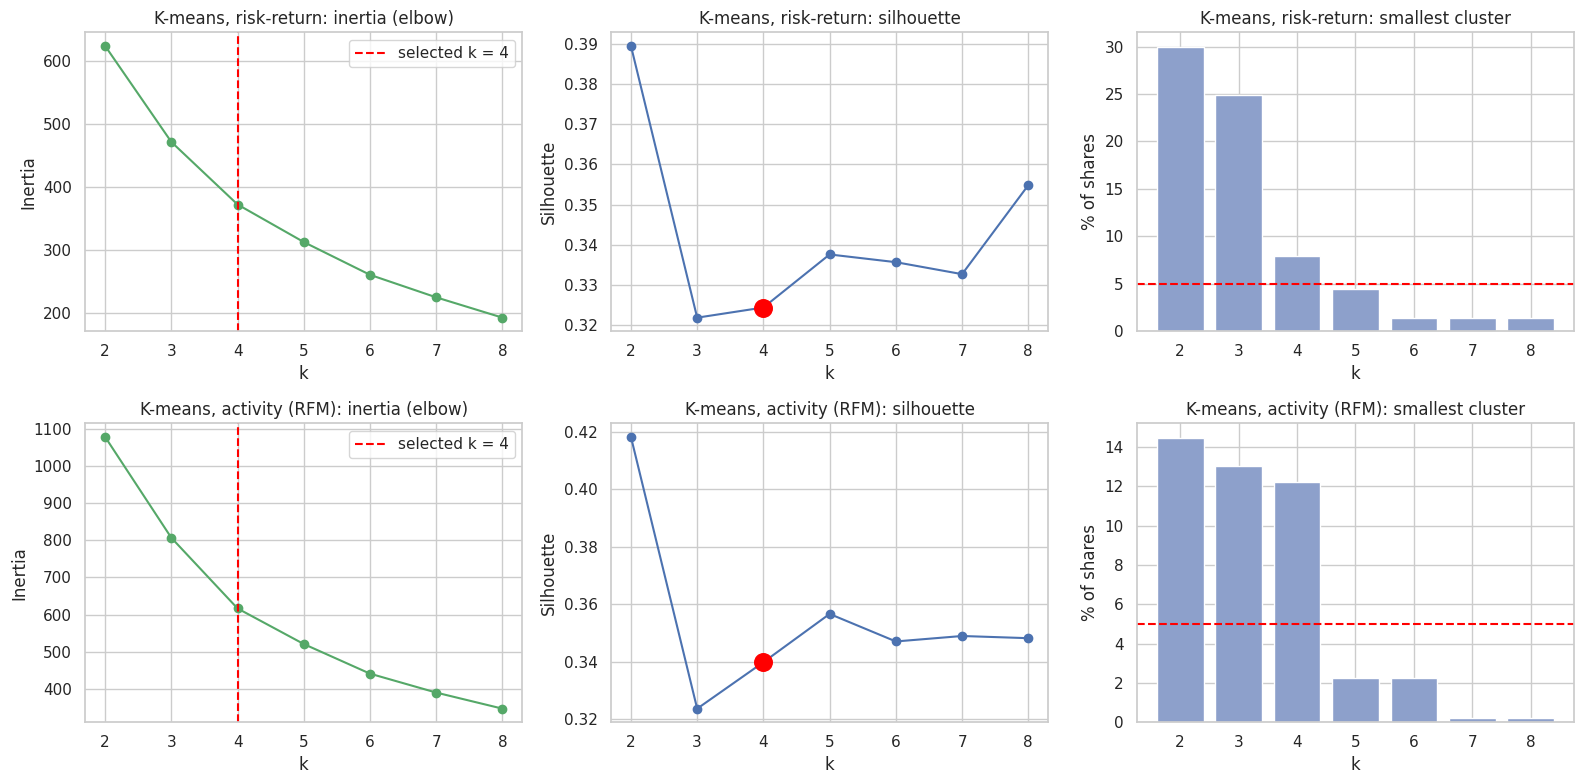

In [89]:
# Chart: inertia (elbow), silhouette and smallest-cluster size for k = 2 to 8 (the chosen k is
# marked in red).
def plot_km_diag(diag, k_sel, title, axes):
    axes[0].plot(diag["k"], diag["inertia"], marker="o", color="#55A868")
    axes[0].axvline(k_sel, color="red", ls="--", label=f"selected k = {k_sel}")
    axes[0].set_title(f"{title}: inertia (elbow)")
    axes[0].set_xlabel("k")
    axes[0].set_ylabel("Inertia")
    axes[0].legend()
    axes[1].plot(diag["k"], diag["silhouette"], marker="o", color="#4C72B0")
    axes[1].scatter([k_sel], diag.loc[diag["k"] == k_sel, "silhouette"], s=160, color="red", zorder=3)
    axes[1].set_title(f"{title}: silhouette")
    axes[1].set_xlabel("k")
    axes[1].set_ylabel("Silhouette")
    axes[2].bar(diag["k"], diag["smallest_pct"], color="#8da0cb")
    axes[2].axhline(MIN_CLUSTER_SHARE * 100, color="red", ls="--")
    axes[2].set_title(f"{title}: smallest cluster")
    axes[2].set_xlabel("k")
    axes[2].set_ylabel("% of shares")


fig, axes = plt.subplots(2, 3, figsize=(16, 8))
plot_km_diag(diag_km_rr, k_km_rr, "K-means, risk-return", axes[0])
plot_km_diag(diag_km_rfm, k_km_rfm, "K-means, activity (RFM)", axes[1])
plt.tight_layout()
plt.show()

# Output:
# The inertia curves drop smoothly with no sharp elbow, so the elbow alone cannot choose k.
# Silhouette is highest at k = 2 and lowest at k = 3 in both rows, and the red dot marks the chosen
# k = 4.
# The smallest-cluster bars fall under the 5% line from k = 5 in both rows.

In [90]:
# Fit the final K-means solutions, then test how stable they are by comparing them with 10 runs that
# each use a single random start.
km_rr_model, km_rfm_model = kmeans_fit(Z_rr, k_km_rr), kmeans_fit(Z_rfm, k_km_rfm)
km_rr, km_rfm = km_rr_model.labels_, km_rfm_model.labels_


def stability(Z, k, base_model, n_runs=10):
    aris, inertias = [], []
    for s in range(n_runs):
        single = KMeans(n_clusters=k, init="random", n_init=1, random_state=s).fit(Z)
        aris.append(adjusted_rand_score(base_model.labels_, single.labels_))
        inertias.append(single.inertia_)
    return pd.Series(
        {
            "base inertia (50 starts)": base_model.inertia_,
            "single-start inertia: best": min(inertias),
            "single-start inertia: worst": max(inertias),
            "ARI vs baseline: lowest": min(aris),
            "ARI vs baseline: average": float(np.mean(aris)),
        }
    )


stab = pd.DataFrame(
    {
        "risk-return": stability(Z_rr, k_km_rr, km_rr_model),
        "activity (RFM)": stability(Z_rfm, k_km_rfm, km_rfm_model),
    }
)
display(stab)

# Output:
# The 50-start solution reaches an inertia of 371.62 (risk-return) and 616.52 (RFM), which is the
# best a single random start can reach too.
# At worst a single start gives 397.42 and 674.55. The groups from single starts match the final
# ones with an average ARI of 0.80 (risk-return) and 0.84 (RFM).

,risk-return,activity (RFM)
base inertia (50 starts),371.6169,616.5236
single-start inertia: best,371.6169,616.5236
single-start inertia: worst,397.4244,674.5483
ARI vs baseline: lowest,0.2740,0.3237
ARI vs baseline: average,0.7973,0.8377


#### 2.3.1 Extra cluster-quality checks: Calinski-Harabasz and Davies-Bouldin

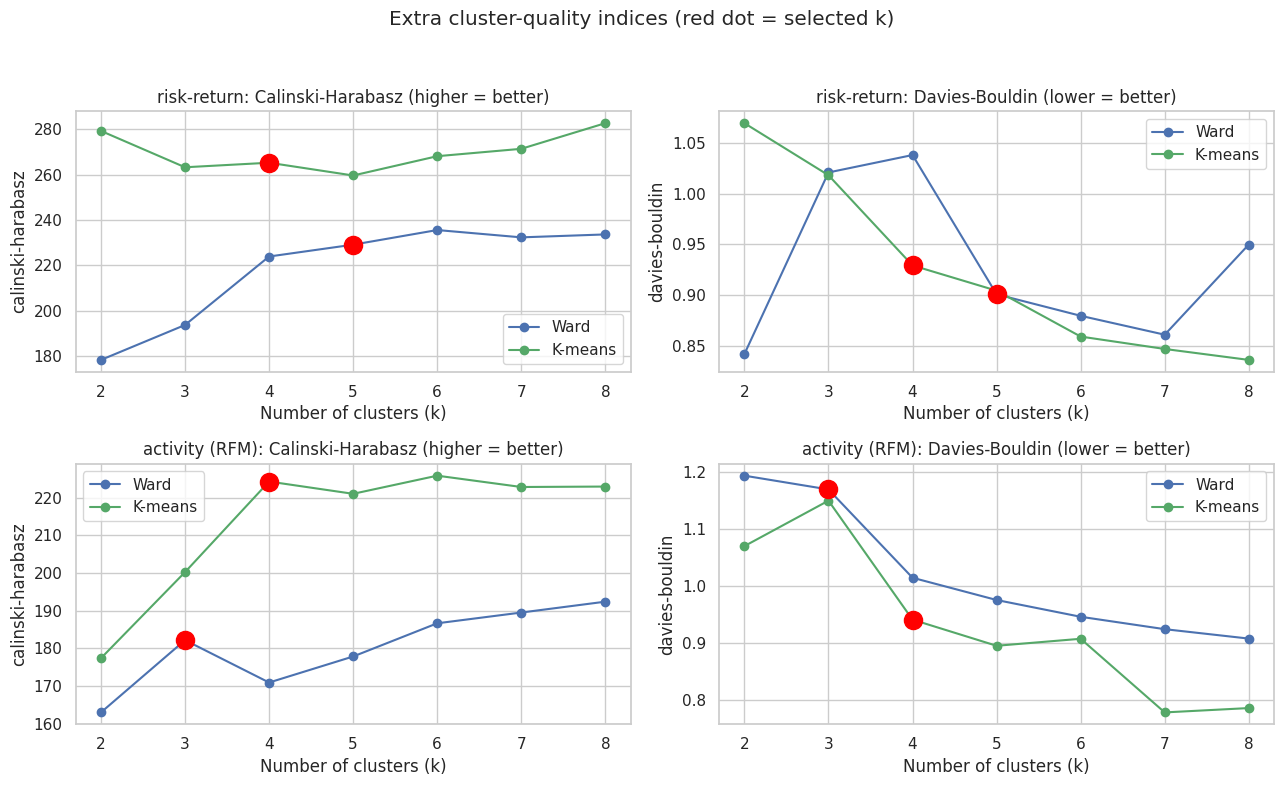

In [91]:
# Chart: Calinski-Harabasz (left, higher is better) and Davies-Bouldin (right, lower is better) for
# k = 2 to 8. Rows are the two feature matrices and each panel compares Ward and K-means. The red
# dots mark the selected k.
solutions_diag = {
    "Ward": {"risk-return": (diag_ward_rr, k_ward_rr), "activity (RFM)": (diag_ward_rfm, k_ward_rfm)},
    "K-means": {"risk-return": (diag_km_rr, k_km_rr), "activity (RFM)": (diag_km_rfm, k_km_rfm)},
}
colours = {"Ward": "#4C72B0", "K-means": "#55A868"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, matrix in enumerate(["risk-return", "activity (RFM)"]):
    for c, (metric, label) in enumerate([("calinski_harabasz", "Calinski-Harabasz (higher = better)"),
                                         ("davies_bouldin", "Davies-Bouldin (lower = better)")]):
        ax = axes[r, c]
        for method in ["Ward", "K-means"]:
            diag, k_sel = solutions_diag[method][matrix]
            ax.plot(diag["k"], diag[metric], marker="o", color=colours[method], label=method)
            ax.scatter([k_sel], diag.loc[diag["k"] == k_sel, metric], s=170, color="red", zorder=3)
        ax.set_title(f"{matrix}: {label}")
        ax.set_xlabel("Number of clusters (k)")
        ax.set_ylabel(metric.replace("_", "-"))
        ax.legend()
fig.suptitle("Extra cluster-quality indices (red dot = selected k)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [92]:
# Table 1: do the three indices point to the same k? For each solution, the best k by each index
# over all k and over the feasible k only (k of at least MIN_K and every cluster holding at least
# MIN_CLUSTER_SHARE of the shares).
def best_k(diag, metric, feasible_only):
    d = diag
    if feasible_only:
        d = diag[(diag["k"] >= MIN_K) & (diag["smallest_pct"] >= MIN_CLUSTER_SHARE * 100)]
        if d.empty:
            d = diag[diag["k"] >= MIN_K]
    return int(d.sort_values(metric, ascending=(metric == "davies_bouldin")).iloc[0]["k"])

rows, quality = [], []
for method, per_matrix in solutions_diag.items():
    for matrix, (diag, k_sel) in per_matrix.items():
        name = f"{method}, {matrix}"
        rows.append({"Solution": name, "Selected k": k_sel,
                     "Silhouette: best k (all)": best_k(diag, "silhouette", False),
                     "Calinski-Harabasz: best k (all)": best_k(diag, "calinski_harabasz", False),
                     "Davies-Bouldin: best k (all)": best_k(diag, "davies_bouldin", False),
                     "Silhouette: best k (feasible)": best_k(diag, "silhouette", True),
                     "Calinski-Harabasz: best k (feasible)": best_k(diag, "calinski_harabasz", True),
                     "Davies-Bouldin: best k (feasible)": best_k(diag, "davies_bouldin", True)})
        at = diag[diag["k"] == k_sel].iloc[0]
        quality.append({"Solution": name, "Selected k": k_sel, "Silhouette": at["silhouette"],
                        "Calinski-Harabasz": at["calinski_harabasz"], "Davies-Bouldin": at["davies_bouldin"]})
metric_agreement = pd.DataFrame(rows).set_index("Solution")
display(metric_agreement)
metric_agreement.to_csv(f"{DATA_DIR}/cluster_index_agreement.csv")

# Table 2: the three indices at the selected k of each solution.
quality_at_k = pd.DataFrame(quality).set_index("Solution")
display(quality_at_k)
quality_at_k.to_csv(f"{DATA_DIR}/cluster_quality_at_selected_k.csv")

,Selected k,Silhouette: best k (all),Calinski-Harabasz: best k (all),Davies-Bouldin: best k (all),Silhouette: best k (feasible),Calinski-Harabasz: best k (feasible),Davies-Bouldin: best k (feasible)
Solution,,,,,,,
"Ward, risk-return",5,2,6,2,5,5,5
"Ward, activity (RFM)",3,2,8,8,3,3,4
"K-means, risk-return",4,2,8,8,4,4,4
"K-means, activity (RFM)",4,2,6,7,4,4,4


,Selected k,Silhouette,Calinski-Harabasz,Davies-Bouldin
Solution,,,,
"Ward, risk-return",5,0.3191,229.1454,0.9009
"Ward, activity (RFM)",3,0.3072,182.2134,1.1694
"K-means, risk-return",4,0.3244,265.2141,0.9293
"K-means, activity (RFM)",4,0.3399,224.2626,0.9407


### 2.4 Cluster profiles and algorithm comparison

In [93]:
# Describe each cluster by its median share in original units (return %, beta, days, busy days, USD
# traded). Each cluster also gets an automatic name from comparing its medians with the overall
# medians (in IQR units). The profile tables are saved as CSV.
overall_med = features[RAW_COLS].median()
overall_iqr = features[RAW_COLS].quantile(0.75) - features[RAW_COLS].quantile(0.25)


def tag(value, col, words):
    spread = max(overall_iqr[col], 0.25 * features[col].std(), 1e-9)
    z = (value - overall_med[col]) / spread
    return (
        words[0]
        if z > 1.5
        else words[1] if z > 0.4 else words[4] if z < -1.5 else words[3] if z < -0.4 else words[2]
    )


W_BETA = ("very high beta", "higher beta", "market-like beta", "lower beta", "very low beta")
W_RET = ("very high return", "higher return", "average return", "lower return", "very low return")
W_REC = ("much older spikes", "older spikes", "typical timing", "more recent spikes", "very recent spikes")
W_FREQ = ("very frequent spikes", "frequent spikes", "typical frequency", "rarer spikes", "very rare spikes")
W_MON = (
    "very high traded value",
    "high traded value",
    "mid traded value",
    "low traded value",
    "very low traded value",
)


def build_profile(labels, matrix):
    d = features[RAW_COLS].copy()
    d["cluster"] = labels
    g = d.groupby("cluster")
    med = g[RAW_COLS].median()
    prof = pd.DataFrame({"Shares": g.size(), "Share of shares %": g.size() / len(d) * 100})
    prof["Median weekly return %"] = med["mean_weekly_return"] * 100
    prof["Median beta"] = med["weekly_beta"]
    if matrix == "rfm":
        prof["Median Recency (days)"] = med["Recency"]
        prof["Median Frequency (busy days)"] = med["Frequency"]
        prof["Median traded value, 60d (USD bn)"] = med["Monetary"] / 1e9
        prof["Median traded value per day (USD m)"] = med["Monetary"] / 60 / 1e6
    names = {}
    for c in med.index:
        if matrix == "rr":
            names[c] = (
                f'{tag(med.loc[c, "weekly_beta"], "weekly_beta", W_BETA)}, {tag(med.loc[c, "mean_weekly_return"], "mean_weekly_return", W_RET)}'
            )
        else:
            names[c] = (
                f'{tag(med.loc[c, "Recency"], "Recency", W_REC)}, {tag(med.loc[c, "Frequency"], "Frequency", W_FREQ)}, {tag(med.loc[c, "Monetary"], "Monetary", W_MON)}'
            )
    seen = {}
    for c in sorted(names):
        seen[names[c]] = seen.get(names[c], 0) + 1
        if list(names.values()).count(names[c]) > 1:
            names[c] = f"{names[c]} ({seen[names[c]]})"
    prof.insert(0, "Segment", [names[c] for c in prof.index])
    return prof, names


solutions = {
    "RR_Ward": (ward_rr, "rr"),
    "RR_KMeans": (km_rr, "rr"),
    "RFM_Ward": (ward_rfm, "rfm"),
    "RFM_KMeans": (km_rfm, "rfm"),
}
profiles, seg_names = {}, {}
for key, (lab, mat) in solutions.items():
    profiles[key], seg_names[key] = build_profile(lab, mat)
    profiles[key].to_csv(f"{DATA_DIR}/profile_{key}.csv")

for key in solutions:
    print(f"\n=== {key} ===")
    display(profiles[key])

# Output:
# Risk-return Ward (k = 5): 36 high-beta, very-high-return shares (median return 0.80% a week, beta
# 1.44), 123 low-beta shares (beta 0.52), 175 market-like shares with higher return, 45 higher-beta
# shares with average return, and 111 market-like shares with lower return.
# Risk-return K-means (k = 4): 175 low-beta shares (beta 0.61), 39 higher-beta, higher-return shares
# (beta 1.69, return 0.72%) and two market-like groups of 155 and 121 shares.
# Activity Ward (k = 3): 92 shares with older spikes (median Recency 53 days, 2 busy days) and two
# typical-timing groups of 147 and 251 shares with the same 3 busy days but high ($41.19 billion)
# and lower ($11.20 billion) traded value over 60 days.
# Activity K-means (k = 4): 60 shares with older spikes, 213 and 122 shares in two typical-timing
# groups (2 and 4 busy days), and 95 shares with high traded value (median about $1.0 billion a
# day).


=== RR_Ward ===


,Segment,Shares,Share of shares %,Median weekly return %,Median beta
cluster,,,,,
0,"higher beta, very high return",36,7.3469,0.8024,1.4445
1,"lower beta, average return",123,25.1020,0.1953,0.5187
2,"market-like beta, higher return",175,35.7143,0.4108,0.9994
3,"higher beta, average return",45,9.1837,0.2615,1.5012
4,"market-like beta, lower return",111,22.6531,0.0758,1.0307



=== RR_KMeans ===


,Segment,Shares,Share of shares %,Median weekly return %,Median beta
cluster,,,,,
0,"market-like beta, higher return",155,31.6327,0.4446,0.9935
1,"market-like beta, lower return",121,24.6939,0.1121,1.1601
2,"lower beta, average return",175,35.7143,0.1852,0.6105
3,"higher beta, higher return",39,7.9592,0.7192,1.6850



=== RFM_Ward ===


,Segment,Shares,Share of shares %,Median weekly return %,Median beta,Median Recency (days),Median Frequency (busy days),"Median traded value, 60d (USD bn)",Median traded value per day (USD m)
cluster,,,,,,,,,
0,"much older spikes, rarer spikes, mid traded value",92,18.7755,0.2537,1.0466,53.0000,2.0000,20.9502,349.1700
1,"typical timing, typical frequency, high traded...",147,30.0000,0.3260,0.9935,11.0000,3.0000,41.1917,686.5290
2,"typical timing, typical frequency, mid traded ...",251,51.2245,0.2501,0.9274,11.0000,3.0000,11.2016,186.6936



=== RFM_KMeans ===


,Segment,Shares,Share of shares %,Median weekly return %,Median beta,Median Recency (days),Median Frequency (busy days),"Median traded value, 60d (USD bn)",Median traded value per day (USD m)
cluster,,,,,,,,,
0,"much older spikes, rarer spikes, mid traded value",60,12.2449,0.2369,1.0346,55.5000,2.0000,21.1474,352.4559
1,"typical timing, rarer spikes, mid traded value",213,43.4694,0.2593,0.9314,11.0000,2.0000,13.3432,222.3863
2,"typical timing, frequent spikes, mid traded value",122,24.8980,0.2533,0.9224,11.0000,4.0000,12.8259,213.7649
3,"typical timing, typical frequency, high traded...",95,19.3878,0.3237,1.0677,11.0000,3.0000,60.1834,"1,003.0574"


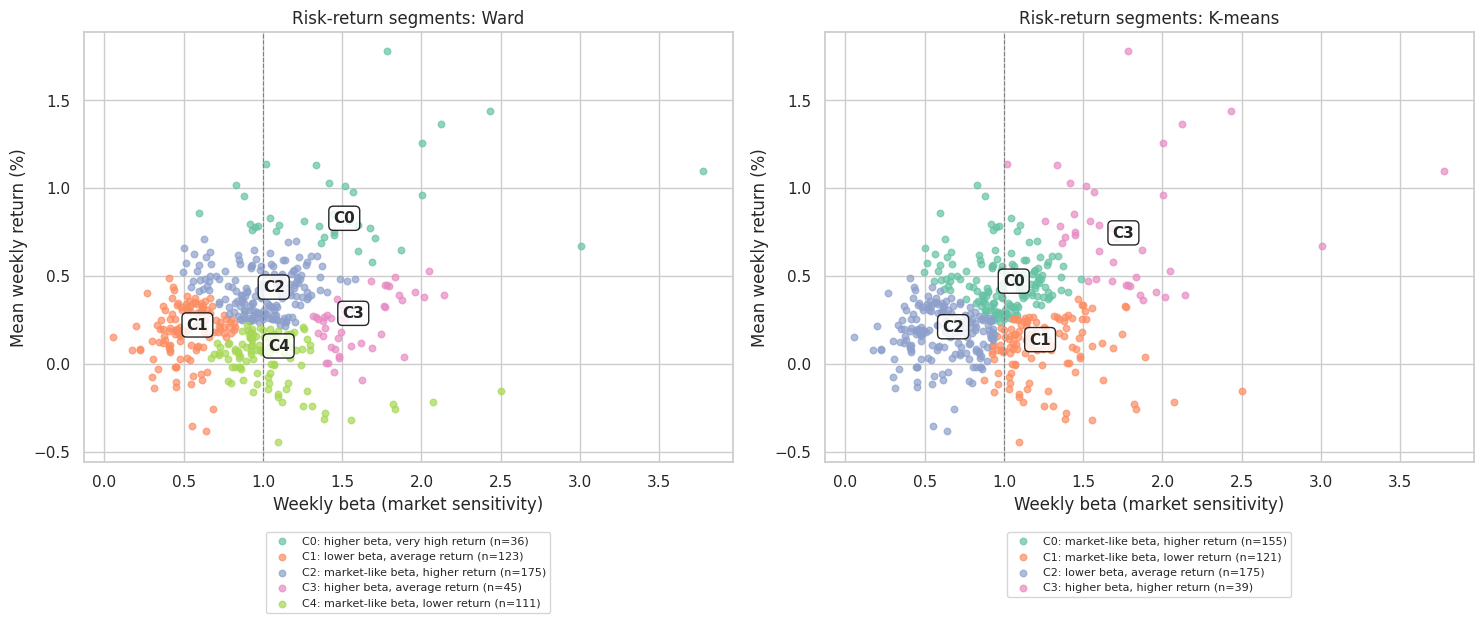

In [94]:
# Chart: the risk-return clusters in original units (beta vs weekly return) for Ward and K-means.
def plot_rr(ax, labels, key, title):
    palette = sns.color_palette("Set2", len(np.unique(labels)))
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(
            features.loc[m, "weekly_beta"],
            features.loc[m, "mean_weekly_return"] * 100,
            s=22,
            alpha=0.7,
            color=palette[c],
            label=f"C{c}: {seg_names[key][c]} (n={m.sum()})",
        )
        ax.annotate(
            f"C{c}",
            (features.loc[m, "weekly_beta"].median(), features.loc[m, "mean_weekly_return"].median() * 100),
            fontsize=11,
            weight="bold",
            bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.85),
        )
    ax.axvline(1, color="grey", ls="--", lw=0.8)
    ax.set_xlabel("Weekly beta (market sensitivity)")
    ax.set_ylabel("Mean weekly return (%)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))


fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_rr(axes[0], ward_rr, "RR_Ward", "Risk-return segments: Ward")
plot_rr(axes[1], km_rr, "RR_KMeans", "Risk-return segments: K-means")
plt.tight_layout()
plt.show()

# Output:
# In the Ward panel C0 (36 shares) sits top-right with high return, C1 (123) sits bottom-left with
# low beta, C2 and C4 are market-like shares with different returns, and C3 has higher beta with
# average return.
# K-means finds similar groups but merges some of them into 4 clusters. The groups overlap a lot, so
# the boundaries are not sharp.

PC1 + PC2 keep 79.5% of the variation (PC1 45.6%, PC2 33.9%)


,PC1,PC2
Recency,0.7149,0.0393
Frequency,-0.6441,0.4255
log1p_Monetary,0.2721,0.9041


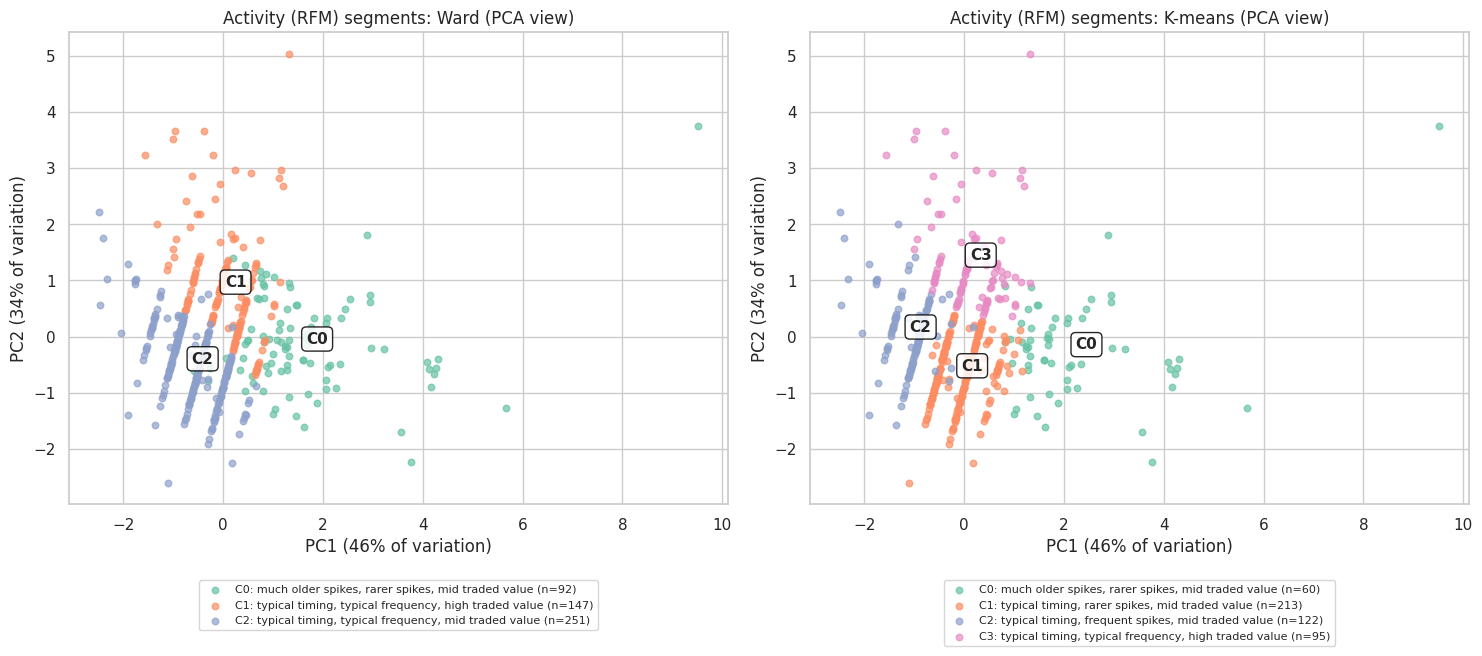

In [95]:
# Chart: the activity clusters on a 2-D PCA view (three features cannot be drawn directly). This
# also prints how much variation PC1 and PC2 keep, and the loadings.
pca = PCA(n_components=2, random_state=SEED).fit(Z_rfm)
coords = pca.transform(Z_rfm)
explained = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=Z_rfm.columns, columns=["PC1", "PC2"])
print(
    f"PC1 + PC2 keep {explained.sum():.1%} of the variation (PC1 {explained[0]:.1%}, PC2 {explained[1]:.1%})"
)
display(loadings)


def plot_pca(ax, labels, key, title):
    palette = sns.color_palette("Set2", len(np.unique(labels)))
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(
            coords[m, 0],
            coords[m, 1],
            s=22,
            alpha=0.7,
            color=palette[c],
            label=f"C{c}: {seg_names[key][c]} (n={m.sum()})",
        )
        ax.annotate(
            f"C{c}",
            (coords[m, 0].mean(), coords[m, 1].mean()),
            fontsize=11,
            weight="bold",
            bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.85),
        )
    ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variation)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))


fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
plot_pca(axes[0], ward_rfm, "RFM_Ward", "Activity (RFM) segments: Ward (PCA view)")
plot_pca(axes[1], km_rfm, "RFM_KMeans", "Activity (RFM) segments: K-means (PCA view)")
plt.tight_layout()
plt.show()

# Output:
# PC1 and PC2 keep 79.5% of the variation (45.6% and 33.9%). PC1 is mostly Recency (loading 0.71,
# with Frequency at -0.64) and PC2 is mostly log1p Monetary (0.90).
# In the plots the older-spike group sits on the right (high Recency). Only two dimensions are
# shown, so groups that look close can still differ on what is hidden.

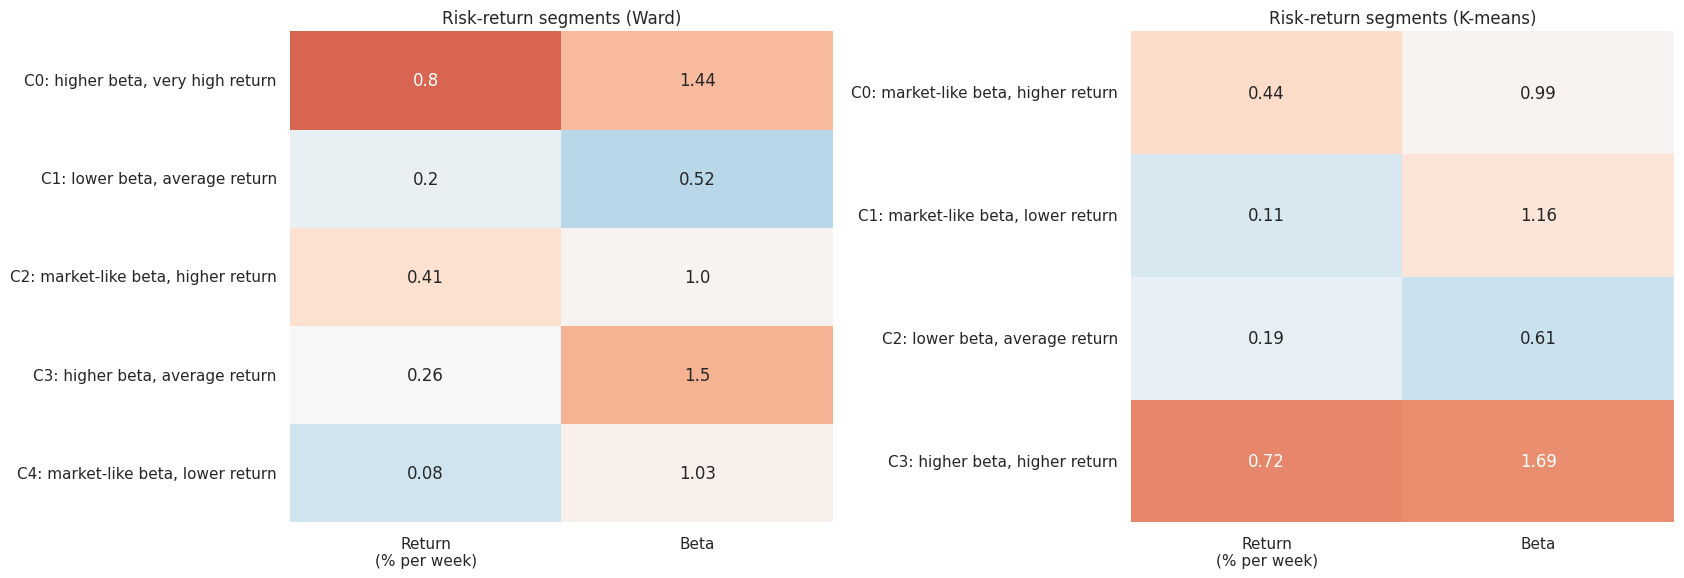

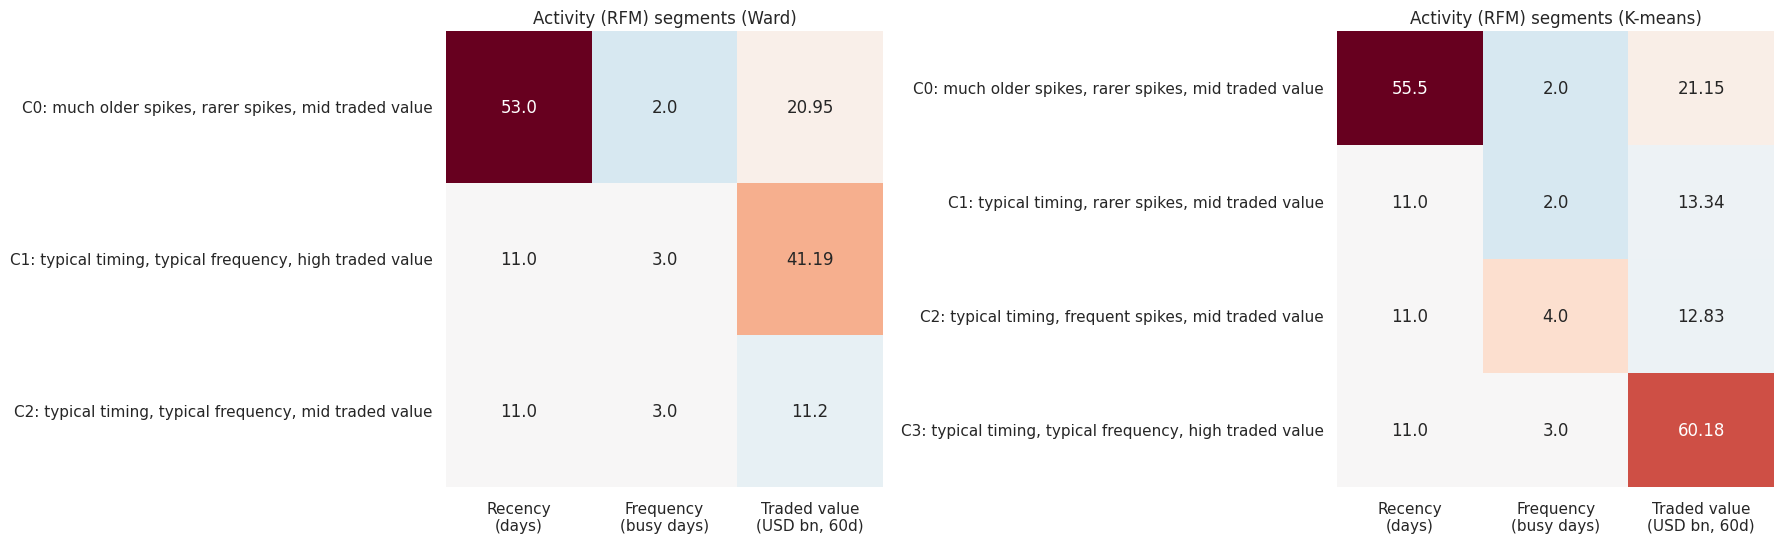

In [96]:
# Chart: 'fingerprint' heatmaps. Each cell shows the cluster's median in original units and the
# colour shows how far it is from the overall median.
def profile_heatmap(ax, labels, key, cols, col_names, scale, title):
    d = features[cols].copy()
    d["cluster"] = labels
    med = d.groupby("cluster")[cols].median()
    rel = (med - overall_med[cols]) / overall_iqr[cols].clip(lower=1e-9)
    annot = (med * scale).round(2)
    annot.columns = col_names
    rel.columns = col_names
    ylabels = [f"C{c}: {seg_names[key][c]}" for c in med.index]
    sns.heatmap(
        rel,
        annot=annot,
        fmt="",
        cmap="RdBu_r",
        center=0,
        vmin=-3,
        vmax=3,
        cbar=False,
        ax=ax,
        yticklabels=ylabels,
    )
    ax.set_title(title)
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=0)


fig, axes = plt.subplots(1, 2, figsize=(17, 4.2 + 0.35 * max(k_ward_rr, k_km_rr)))
for ax, (lab, key, t) in zip(axes, [(ward_rr, "RR_Ward", "Ward"), (km_rr, "RR_KMeans", "K-means")]):
    profile_heatmap(
        ax,
        lab,
        key,
        ["mean_weekly_return", "weekly_beta"],
        ["Return\n(% per week)", "Beta"],
        np.array([100, 1]),
        f"Risk-return segments ({t})",
    )
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 4.2 + 0.35 * max(k_ward_rfm, k_km_rfm)))
for ax, (lab, key, t) in zip(axes, [(ward_rfm, "RFM_Ward", "Ward"), (km_rfm, "RFM_KMeans", "K-means")]):
    profile_heatmap(
        ax,
        lab,
        key,
        ["Recency", "Frequency", "Monetary"],
        ["Recency\n(days)", "Frequency\n(busy days)", "Traded value\n(USD bn, 60d)"],
        np.array([1, 1, 1e-9]),
        f"Activity (RFM) segments ({t})",
    )
plt.tight_layout()
plt.show()

# Output:
# Risk-return: Ward C0 has the highest return (0.8% a week) with a beta of 1.44, and K-means C3 has
# the highest beta (1.69) with a return of 0.72%.
# Activity: the older-spike group stands out on Recency (53 days for Ward, 55.5 for K-means) and
# K-means C3 stands out on traded value ($60.18 billion over 60 days).
# In the Ward solution, traded value ranges from 11.20 to 41.19 billion USD.

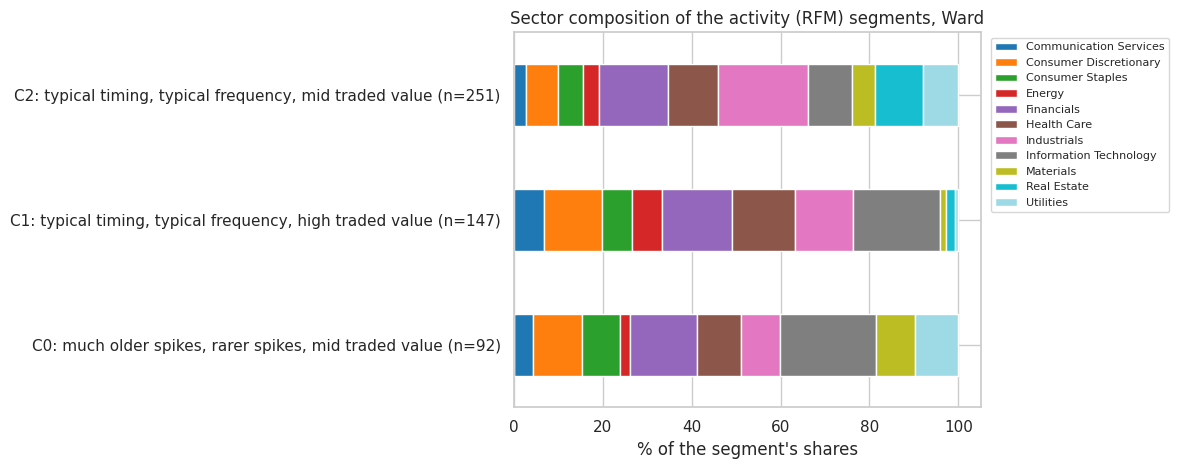

In [97]:
# Chart: sector mix of each activity segment (Ward).
sector_mix = pd.crosstab(ward_rfm, features["Sector"], normalize="index") * 100
sector_mix.index = [
    f"C{c}: {seg_names['RFM_Ward'][c]} (n={int((ward_rfm == c).sum())})" for c in sector_mix.index
]
sector_mix.plot(kind="barh", stacked=True, figsize=(12, 3.2 + 0.55 * len(sector_mix)), colormap="tab20")
plt.xlabel("% of the segment's shares")
plt.title("Sector composition of the activity (RFM) segments, Ward")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Output:
# Every activity segment contains a mix of sectors, so trading activity does not line up neatly with
# industries.
# Information Technology is the biggest slice in the older-spike group C0 (about 22%) and in C1
# (about 20%), while C2 is led by Industrials (about 20%), Financials (16%) and Health Care (11%).

,Ward k,K-means k,ARI (selected solutions),ARI (K-means refit at Ward's k)
Risk-return,5,4,0.5674,0.6005
Activity (RFM),3,4,0.3252,0.8332


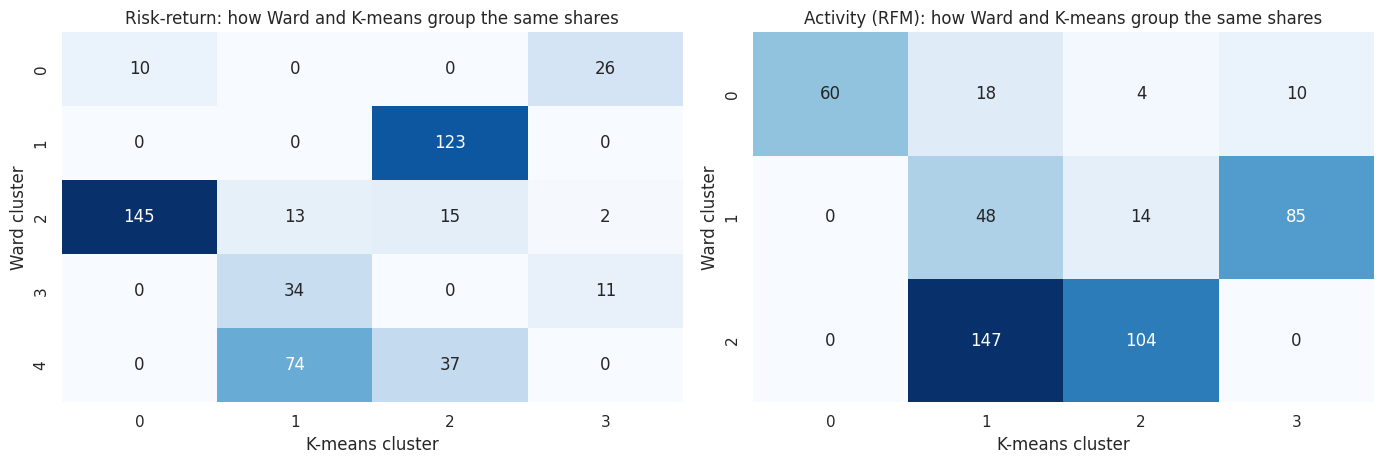

In [98]:
# Compare Ward and K-means on the same shares using ARI (1 = identical groups, near 0 = no better
# than chance) and cross-tables. K-means is also refit at Ward's k for a fair comparison.
ari_rr = adjusted_rand_score(ward_rr, km_rr)
ari_rfm = adjusted_rand_score(ward_rfm, km_rfm)
ari_rr_samek = adjusted_rand_score(ward_rr, kmeans_fit(Z_rr, k_ward_rr).labels_)
ari_rfm_samek = adjusted_rand_score(ward_rfm, kmeans_fit(Z_rfm, k_ward_rfm).labels_)

agree = pd.DataFrame(
    {
        "Ward k": [k_ward_rr, k_ward_rfm],
        "K-means k": [k_km_rr, k_km_rfm],
        "ARI (selected solutions)": [ari_rr, ari_rfm],
        "ARI (K-means refit at Ward's k)": [ari_rr_samek, ari_rfm_samek],
    },
    index=["Risk-return", "Activity (RFM)"],
)
display(agree)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (a, b, t) in zip(axes, [(ward_rr, km_rr, "Risk-return"), (ward_rfm, km_rfm, "Activity (RFM)")]):
    ct = pd.crosstab(pd.Series(a, name="Ward cluster"), pd.Series(b, name="K-means cluster"))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{t}: how Ward and K-means group the same shares")
plt.tight_layout()
plt.show()

# Output:
# Risk-return agreement is 0.5674 (0.6005 when K-means uses Ward's k = 5). For activity (RFM), the
# agreement is 0.3252 (0.8332 at the same k = 3).
# Risk-return cross-table: all 123 low-beta shares match exactly (Ward C1 and K-means C2) and Ward
# C2 mostly maps to K-means C0 (145 of 175).
# RFM cross-table: Ward C0 (92 shares) matches K-means C0 for 60 of them, Ward C2 is split between
# K-means clusters 1 (147) and 2 (104), and Ward C1 maps mostly to K-means cluster 3 (85).

### 2.5 RFM sensitivity and correlated inputs

#### 2.5.1 Correlation analysis

Pearson correlation


,Recency,Frequency,log1p_Monetary
Recency,1.0000,-0.3392,0.1604
Frequency,-0.3392,1.0000,0.0232
log1p_Monetary,0.1604,0.0232,1.0000


Spearman (rank) correlation


,Recency,Frequency,log1p_Monetary
Recency,1.0000,-0.1831,0.1494
Frequency,-0.1831,1.0000,-0.0361
log1p_Monetary,0.1494,-0.0361,1.0000


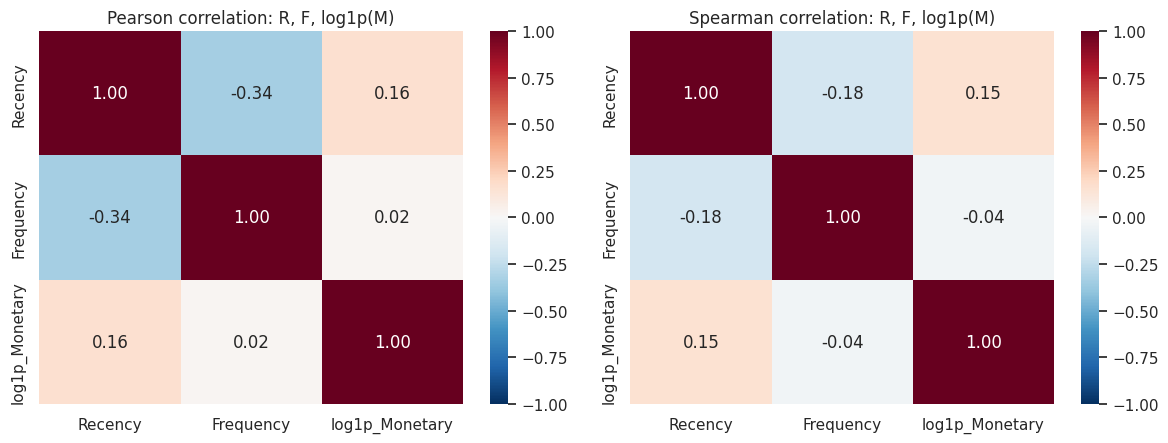

In [99]:
# Correlations among Recency, Frequency and log1p Monetary using Pearson (straight-line) and
# Spearman (rank-based), saved as CSV and shown as heatmaps.
corr_pearson = X_rfm.corr(method="pearson")
corr_spearman = X_rfm.corr(method="spearman")
print("Pearson correlation")
display(corr_pearson)
print("Spearman (rank) correlation")
display(corr_spearman)
corr_pearson.to_csv(f"{DATA_DIR}/rfm_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, c, t in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{t} correlation: R, F, log1p(M)")
plt.tight_layout()
plt.show()

# Output:
# The strongest link is Recency and Frequency (Pearson -0.34, Spearman -0.18). Recency and Monetary
# are slightly positive (0.16 and 0.15) and Frequency and Monetary are almost unrelated (0.02 and
# -0.04).
# All the correlations are weak.

In [100]:
# See how much the three features overlap using PCA on the standardised RFM matrix (independent
# features would keep about a third each), and list the shared variance for each pair of features.
pca_full = PCA(n_components=3, random_state=SEED).fit(Z_rfm)
overlap = pd.DataFrame(
    {"Share of variation kept": pca_full.explained_variance_ratio_}, index=["PC1", "PC2", "PC3"]
)
display(overlap)
pairs = {
    ("Recency", "Frequency"): corr_pearson.loc["Recency", "Frequency"],
    ("Recency", "log1p_Monetary"): corr_pearson.loc["Recency", "log1p_Monetary"],
    ("Frequency", "log1p_Monetary"): corr_pearson.loc["Frequency", "log1p_Monetary"],
}
display(
    pd.DataFrame(
        {
            "Pearson r": pairs,
            "Variance along shared direction (1 + |r|)": {k: 1 + abs(v) for k, v in pairs.items()},
        }
    )
)

# Output:
# PC1 keeps 45.6% of the variation, PC2 33.9% and PC3 20.5%, against 33% each if the features were
# independent, so there is some overlap but not a lot.
# Among the pairs, Recency and Frequency share the most (1.34), then Recency and Monetary (1.16) and
# Frequency and Monetary (1.02).

,Share of variation kept
PC1,0.4556
PC2,0.3393
PC3,0.2051


Pearson r  Variance along shared direction (1 + |r|)
Recency   Frequency         -0.3392                                     1.3392
          log1p_Monetary     0.1604                                     1.1604
Frequency log1p_Monetary     0.0232                                     1.0232

#### 2.5.2 Removal of Monetary

In [101]:
# Repeat Ward on Recency and Frequency only (same shares, same k, standardised again) and compare it
# with the full RFM solution using ARI and silhouette.
X_rf = X_rfm[["Recency", "Frequency"]]
Z_rf = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)
link_rf = linkage(Z_rf.to_numpy(), method="ward", metric="euclidean")
ward_rf = ward_labels(link_rf, k_ward_rfm)

ari_rf = adjusted_rand_score(ward_rfm, ward_rf)
print(
    f"k = {k_ward_rfm} | shares = {len(Z_rf)} | ARI between RFM (3 features) and R+F only (2 features): {ari_rf:.3f}"
)
print(
    f"Silhouette: RFM = {silhouette_score(Z_rfm, ward_rfm):.3f} | R+F only = {silhouette_score(Z_rf, ward_rf):.3f}"
)

display(
    pd.crosstab(
        pd.Series(ward_rfm, name="RFM cluster (3 features)"),
        pd.Series(ward_rf, name="R+F cluster (2 features)"),
    )
)

# Output:
# The ARI between the 3-feature and 2-feature solutions is 0.324, so removing Monetary changes the
# groups a lot. The silhouette rises from 0.307 to 0.485 without Monetary (not like-for-like, as the
# matrices differ).
# In the cross-table RFM cluster 0 (92 shares) mostly stays together (89), while RFM clusters 1 (147
# shares) and 2 (251 shares) are both split between R+F clusters 1 and 2 (59 / 87 and 66 / 184).

k = 3 | shares = 490 | ARI between RFM (3 features) and R+F only (2 features): 0.324
Silhouette: RFM = 0.307 | R+F only = 0.485


R+F cluster (2 features),0,1,2
RFM cluster (3 features),,,
0,89,0,3
1,1,59,87
2,1,66,184


Selected RFM Ward solution (R, F, log1p M)


,Shares,Median Recency,Median Frequency,Median traded value/day (USD m),Mean traded value/day (USD m)
cluster,,,,,
0,92,53.0000,2.0000,349.1700,766.4160
1,147,11.0000,3.0000,686.5290,"1,398.8858"
2,251,11.0000,3.0000,186.6936,196.2142


R + F only Ward solution (Monetary removed)


,Shares,Median Recency,Median Frequency,Median traded value/day (USD m),Mean traded value/day (USD m)
cluster,,,,,
0,91,53.0000,2.0000,350.8765,806.4437
1,125,11.0000,2.0000,294.9832,572.2983
2,274,11.0000,4.0000,247.5891,658.6591


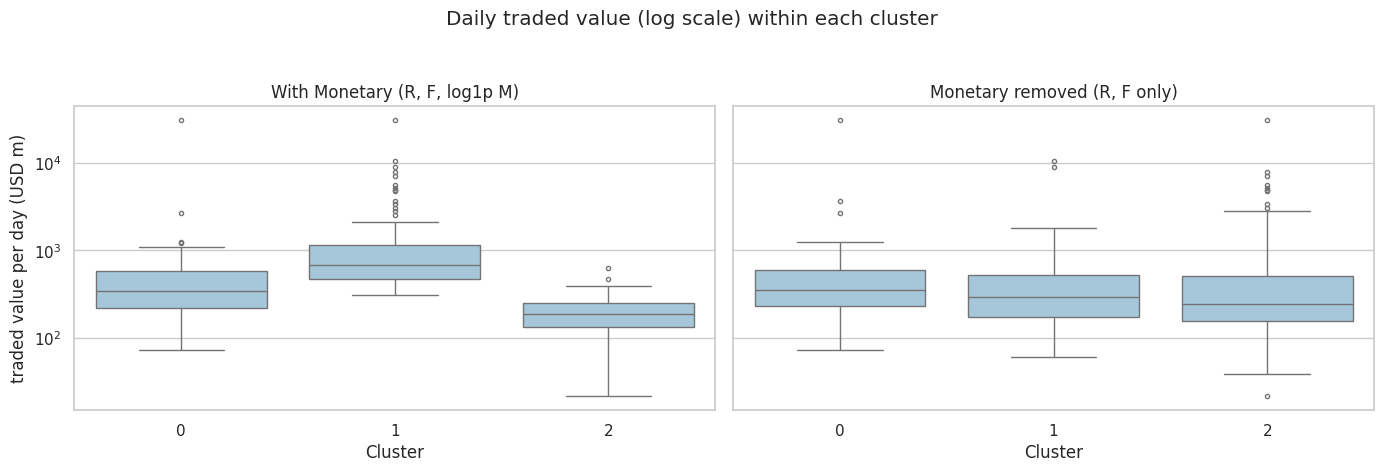

In [102]:
# Compare traded value across the clusters with and without Monetary, to see whether Monetary mainly
# separates liquidity levels. The profiles are saved as CSV.
def traded_profile(labels):
    d = pd.DataFrame(
        {
            "cluster": labels,
            "traded_value_per_day_m": features["Monetary"].to_numpy() / 60 / 1e6,
            "Recency": features["Recency"].to_numpy(),
            "Frequency": features["Frequency"].to_numpy(),
        }
    )
    g = d.groupby("cluster")
    return pd.DataFrame(
        {
            "Shares": g.size(),
            "Median Recency": g["Recency"].median(),
            "Median Frequency": g["Frequency"].median(),
            "Median traded value/day (USD m)": g["traded_value_per_day_m"].median(),
            "Mean traded value/day (USD m)": g["traded_value_per_day_m"].mean(),
        }
    )


tp_full, tp_rf = traded_profile(ward_rfm), traded_profile(ward_rf)
print("Selected RFM Ward solution (R, F, log1p M)")
display(tp_full)
print("R + F only Ward solution (Monetary removed)")
display(tp_rf)
tp_full.to_csv(f"{DATA_DIR}/traded_value_profile_RFM.csv")
tp_rf.to_csv(f"{DATA_DIR}/traded_value_profile_RF_only.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, labels, t in zip(
    axes, [ward_rfm, ward_rf], ["With Monetary (R, F, log1p M)", "Monetary removed (R, F only)"]
):
    d = pd.DataFrame(
        {"cluster": labels, "traded value per day (USD m)": features["Monetary"].to_numpy() / 60 / 1e6}
    )
    sns.boxplot(data=d, x="cluster", y="traded value per day (USD m)", ax=ax, color="#9ecae1", fliersize=3)
    ax.set_yscale("log")
    ax.set_title(t)
    ax.set_xlabel("Cluster")
fig.suptitle("Daily traded value (log scale) within each cluster")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# Output:
# With Monetary the median traded value per day differs across the clusters (187 to 687 million USD,
# about 3.7 times).
# Without Monetary the medians are much closer (248 to 351 million USD, about 1.4 times) and the
# boxplots in the right panel overlap much more.
# So Monetary is what separates the groups by traded value.

In [103]:
# Eta-squared: the share of each feature's variation that lies between the clusters (0 = clusters do
# not differ on it, 1 = clusters completely separate it), for the full RFM solution and the R+F only
# solution.
def eta_sq(values, labels):
    v = np.asarray(values, dtype=float)
    lab = np.asarray(labels)
    total = ((v - v.mean()) ** 2).sum()
    between = sum((lab == c).sum() * (v[lab == c].mean() - v.mean()) ** 2 for c in np.unique(lab))
    return between / total


eta = pd.DataFrame(
    {
        "Full RFM solution": {f: eta_sq(X_rfm[f], ward_rfm) for f in X_rfm.columns},
        "R+F only solution": {f: eta_sq(X_rfm[f], ward_rf) for f in X_rfm.columns},
    }
)
display(eta)

# Output:
# In the full solution Recency (0.64) and log1p Monetary (0.52) separate the groups the most, while
# Frequency is low (0.13).
# Without Monetary the value for log1p Monetary falls to 0.006, so the R+F groups say almost nothing
# about traded value, and Frequency becomes much more important (0.53).

,Full RFM solution,R+F only solution
Recency,0.6370,0.6481
Frequency,0.1284,0.5351
log1p_Monetary,0.5187,0.0057


### Saved outputs

In [104]:
# Save the cluster assignments of every solution (with the segment names) and the diagnostics table
# for all four runs.
assignments = features[["Company", "Sector"]].copy()
assignments["RR_Ward"], assignments["RR_KMeans"] = ward_rr, km_rr
assignments["RFM_Ward"], assignments["RFM_KMeans"] = ward_rfm, km_rfm
assignments["RFM_Ward_RF_only"] = ward_rf
for key in solutions:
    assignments[f"{key}_segment"] = [seg_names[key][c] for c in assignments[key]]
assignments.to_csv(f"{DATA_DIR}/cluster_assignments.csv")

diagnostics_all = pd.concat(
    {
        "Ward risk-return": diag_ward_rr,
        "Ward RFM": diag_ward_rfm,
        "K-means risk-return": diag_km_rr,
        "K-means RFM": diag_km_rfm,
    },
    names=["solution"],
).reset_index(level=0)
diagnostics_all.to_csv(f"{DATA_DIR}/cluster_diagnostics.csv", index=False)
print(
    "Saved:", f"{DATA_DIR}/cluster_assignments.csv", f"{DATA_DIR}/cluster_diagnostics.csv", "+ profile tables"
)
display(assignments.head())

# Output:
# The assignments and diagnostics were saved in the data folder together with the profile tables. In
# the first five rows, for example, MMM is in Ward cluster 4 and K-means cluster 2 for risk-return.

Saved: data/cluster_assignments.csv data/cluster_diagnostics.csv + profile tables


,Company,Sector,RR_Ward,RR_KMeans,RFM_Ward,RFM_KMeans,RFM_Ward_RF_only,RR_Ward_segment,RR_KMeans_segment,RFM_Ward_segment,RFM_KMeans_segment
MMM,3M,Industrials,4,2,1,2,2,"market-like beta, lower return","lower beta, average return","typical timing, typical frequency, high traded...","typical timing, frequent spikes, mid traded value"
AOS,A. O. Smith,Industrials,4,1,2,1,1,"market-like beta, lower return","market-like beta, lower return","typical timing, typical frequency, mid traded ...","typical timing, rarer spikes, mid traded value"
ABT,Abbott Laboratories,Health Care,1,2,1,1,1,"lower beta, average return","lower beta, average return","typical timing, typical frequency, high traded...","typical timing, rarer spikes, mid traded value"
ABBV,AbbVie,Health Care,1,2,1,3,2,"lower beta, average return","lower beta, average return","typical timing, typical frequency, high traded...","typical timing, typical frequency, high traded..."
ACN,Accenture,Information Technology,2,1,1,3,1,"market-like beta, higher return","market-like beta, lower return","typical timing, typical frequency, high traded...","typical timing, typical frequency, high traded..."


In [105]:
# Save the Task 2 run details (settings, selected k and ARI values) as JSON.
task2_metadata = {
    "package_versions": PACKAGE_VERSIONS,
    "settings": {
        "seed": SEED,
        "k_range": [K_RANGE[0], K_RANGE[-1]],
        "kmeans_n_init": N_INIT,
        "min_k": MIN_K,
        "min_cluster_share": MIN_CLUSTER_SHARE,
        "selection_metric": SELECTION_METRIC,
    },
    "input": {"file": FEATURES_CSV, "shares": int(len(features))},
    "selected_k": {
        "RR_Ward": int(k_ward_rr),
        "RR_KMeans": int(k_km_rr),
        "RFM_Ward": int(k_ward_rfm),
        "RFM_KMeans": int(k_km_rfm),
    },
    "agreement_ARI": {
        "RR_Ward_vs_KMeans": round(float(ari_rr), 4),
        "RFM_Ward_vs_KMeans": round(float(ari_rfm), 4),
        "RFM_vs_RF_only": round(float(ari_rf), 4),
        "RFM_vs_logR": round(float(ari_logR), 4),
    },
}
json.dump(task2_metadata, open(f"{DATA_DIR}/task2_metadata.json", "w"), indent=2)
task2_metadata["selected_k"]

# Output:
# The selected k is 5 (risk-return Ward), 4 (risk-return K-means), 3 (RFM Ward) and 4 (RFM K-means).

{'RR_Ward': 5, 'RR_KMeans': 4, 'RFM_Ward': 3, 'RFM_KMeans': 4}

In [106]:
# Zip the data folder for download.
import shutil

shutil.make_archive("task2_data", "zip", DATA_DIR)
try:
    from google.colab import files

    files.download("task2_data.zip")
except ImportError:
    print("Not running in Colab - the zip is saved as task2_data.zip")

# Output:
# The zip download was triggered in Colab (task2_data.zip).

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 3.2 supporting evidence: risk-return segments versus activity segments

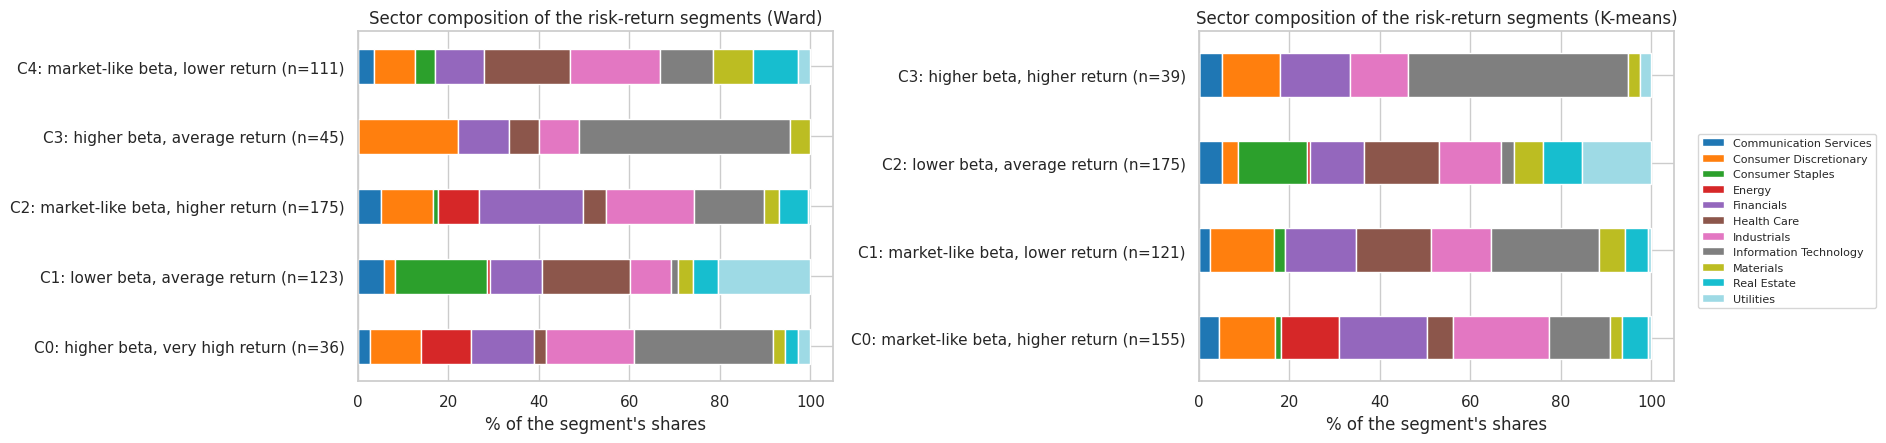

In [107]:
# Chart: sector mix of each risk-return segment (Ward left, K-means right), in the same style as the
# activity-segment chart.
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), sharex=True)
for ax, (labels, key, title) in zip(axes, [(ward_rr, "RR_Ward", "Ward"), (km_rr, "RR_KMeans", "K-means")]):
    mix = pd.crosstab(labels, features["Sector"], normalize="index") * 100
    mix.index = [f"C{c}: {seg_names[key][c]} (n={int((labels == c).sum())})" for c in mix.index]
    mix.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", legend=False)
    ax.set_title(f"Sector composition of the risk-return segments ({title})")
    ax.set_xlabel("% of the segment's shares")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

In [108]:
# Table: for every segment of all four solutions, the three biggest sectors and the sector that is
# most over-represented compared with the whole share set (lift = segment share / overall share).
# Sectors with fewer than 5 shares in a segment are ignored so tiny counts do not look important.
overall_sector = features["Sector"].value_counts(normalize=True) * 100
rows = []
for key, (labels, matrix) in solutions.items():
    mix = pd.crosstab(labels, features["Sector"], normalize="index") * 100
    counts = pd.crosstab(labels, features["Sector"])
    for c in mix.index:
        top3 = mix.loc[c].sort_values(ascending=False).head(3)
        lift = (mix.loc[c] / overall_sector).where(counts.loc[c] >= 5)
        rows.append({"Solution": key, "Cluster": c, "Segment": seg_names[key][c], "Shares": int((labels == c).sum()),
                     "Top 3 sectors (% of segment)": ", ".join(f"{s} {v:.0f}%" for s, v in top3.items()),
                     "Most over-represented sector": f"{lift.idxmax()} ({lift.max():.1f}x overall)"})
sector_table = pd.DataFrame(rows)
sector_table.to_csv(f"{DATA_DIR}/sector_composition_by_segment.csv", index=False)
display(sector_table)

,Solution,Cluster,Segment,Shares,Top 3 sectors (% of segment),Most over-represented sector
0,RR_Ward,0,"higher beta, very high return",36,"Information Technology 31%, Industrials 19%, F...",Information Technology (2.0x overall)
1,RR_Ward,1,"lower beta, average return",123,"Consumer Staples 20%, Utilities 20%, Health Ca...",Utilities (3.3x overall)
2,RR_Ward,2,"market-like beta, higher return",175,"Financials 23%, Industrials 19%, Information T...",Energy (2.1x overall)
3,RR_Ward,3,"higher beta, average return",45,"Information Technology 47%, Consumer Discretio...",Information Technology (3.1x overall)
4,RR_Ward,4,"market-like beta, lower return",111,"Industrials 20%, Health Care 19%, Information ...",Materials (1.9x overall)
5,RR_KMeans,0,"market-like beta, higher return",155,"Industrials 21%, Financials 19%, Information T...",Energy (3.0x overall)
6,RR_KMeans,1,"market-like beta, lower return",121,"Information Technology 24%, Health Care 17%, F...",Information Technology (1.6x overall)
7,RR_KMeans,2,"lower beta, average return",175,"Health Care 17%, Utilities 15%, Consumer Stapl...",Utilities (2.5x overall)
8,RR_KMeans,3,"higher beta, higher return",39,"Information Technology 49%, Financials 15%, Co...",Information Technology (3.2x overall)
9,RFM_Ward,0,"much older spikes, rarer spikes, mid traded value",92,"Information Technology 22%, Financials 15%, Co...",Materials (1.9x overall)


,ARI between risk-return and activity segments
Ward,0.0161
K-means,0.0198


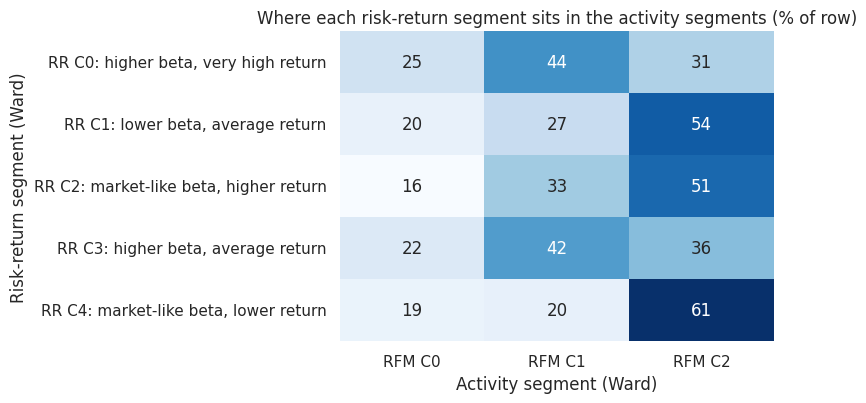

In [109]:
# Chart: how the risk-return segments (rows) overlap with the activity segments (columns) for the
# Ward solutions. Each cell shows the % of the row's shares that fall in that activity segment. If
# the two lenses measured the same thing, each row would sit almost entirely in one column.
ari_lenses = pd.Series({"Ward": adjusted_rand_score(ward_rr, ward_rfm), "K-means": adjusted_rand_score(km_rr, km_rfm)},
                       name="ARI between risk-return and activity segments")
display(ari_lenses.to_frame())

overlap = pd.crosstab(pd.Series([f"RR C{c}: {seg_names['RR_Ward'][c]}" for c in ward_rr], name="Risk-return segment (Ward)"),
                      pd.Series([f"RFM C{c}" for c in ward_rfm], name="Activity segment (Ward)"), normalize="index") * 100
plt.figure(figsize=(8, 4.2))
sns.heatmap(overlap, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.title("Where each risk-return segment sits in the activity segments (% of row)")
plt.tight_layout()
plt.show()

In [110]:
# Table: all segments of all four solutions described with the same five measures in original units
# (median return %, beta, Recency, busy days, traded value per day), so the lenses can be compared
# like for like.
cols = ["mean_weekly_return", "weekly_beta", "Recency", "Frequency", "Monetary"]
parts = []
for key, (labels, matrix) in solutions.items():
    med = features[cols].assign(cluster=labels).groupby("cluster").median()
    parts.append(pd.DataFrame({
        "Solution": key, "Segment": [seg_names[key][c] for c in med.index],
        "Shares": pd.Series(labels).value_counts().sort_index().to_numpy(),
        "Median return % per week": med["mean_weekly_return"].to_numpy() * 100, "Median beta": med["weekly_beta"].to_numpy(),
        "Median Recency (days)": med["Recency"].to_numpy(), "Median busy days": med["Frequency"].to_numpy(),
        "Median traded value per day (USD m)": med["Monetary"].to_numpy() / 60 / 1e6}))
cross_profile = pd.concat(parts, ignore_index=True)
cross_profile.to_csv(f"{DATA_DIR}/cross_profile_all_segments.csv", index=False)
display(cross_profile)

# Spread of the segment medians for each solution: wide means the lens separates that measure,
# narrow means it does not.
spread = cross_profile.groupby("Solution")[["Median return % per week", "Median beta", "Median Recency (days)",
                                            "Median busy days", "Median traded value per day (USD m)"]].agg(["min", "max"])
display(spread)

,Solution,Segment,Shares,Median return % per week,Median beta,Median Recency (days),Median busy days,Median traded value per day (USD m)
0,RR_Ward,"higher beta, very high return",36,0.8024,1.4445,11.0000,3.0000,449.6645
1,RR_Ward,"lower beta, average return",123,0.1953,0.5187,11.0000,3.0000,242.7770
2,RR_Ward,"market-like beta, higher return",175,0.4108,0.9994,11.0000,3.0000,304.8901
3,RR_Ward,"higher beta, average return",45,0.2615,1.5012,11.0000,3.0000,484.4995
4,RR_Ward,"market-like beta, lower return",111,0.0758,1.0307,11.0000,3.0000,226.6074
5,RR_KMeans,"market-like beta, higher return",155,0.4446,0.9935,11.0000,3.0000,306.2551
6,RR_KMeans,"market-like beta, lower return",121,0.1121,1.1601,11.0000,3.0000,246.1252
7,RR_KMeans,"lower beta, average return",175,0.1852,0.6105,11.0000,3.0000,236.7599
8,RR_KMeans,"higher beta, higher return",39,0.7192,1.6850,18.0000,3.0000,766.9249
9,RFM_Ward,"much older spikes, rarer spikes, mid traded value",92,0.2537,1.0466,53.0000,2.0000,349.1700


Median return % per week        Median beta         \
                                min    max         min    max   
Solution                                                        
RFM_KMeans                   0.2369 0.3237      0.9224 1.0677   
RFM_Ward                     0.2501 0.3260      0.9274 1.0466   
RR_KMeans                    0.1121 0.7192      0.6105 1.6850   
RR_Ward                      0.0758 0.8024      0.5187 1.5012   

           Median Recency (days)         Median busy days         \
                             min     max              min    max   
Solution                                                           
RFM_KMeans               11.0000 55.5000           2.0000 4.0000   
RFM_Ward                 11.0000 53.0000           2.0000 3.0000   
RR_KMeans                11.0000 18.0000           3.0000 3.0000   
RR_Ward                  11.0000 11.0000           3.0000 3.0000   

           Median traded value per day (USD m)             
                                           min        max  
Solution                                                   
RFM_KMeans                            213.7649 1,003.0574  
RFM_Ward                              186.6936   686.5290  
RR_KMeans                             236.7599   766.9249  
RR_Ward                               226.6074   484.4995

### More charts for 3.2

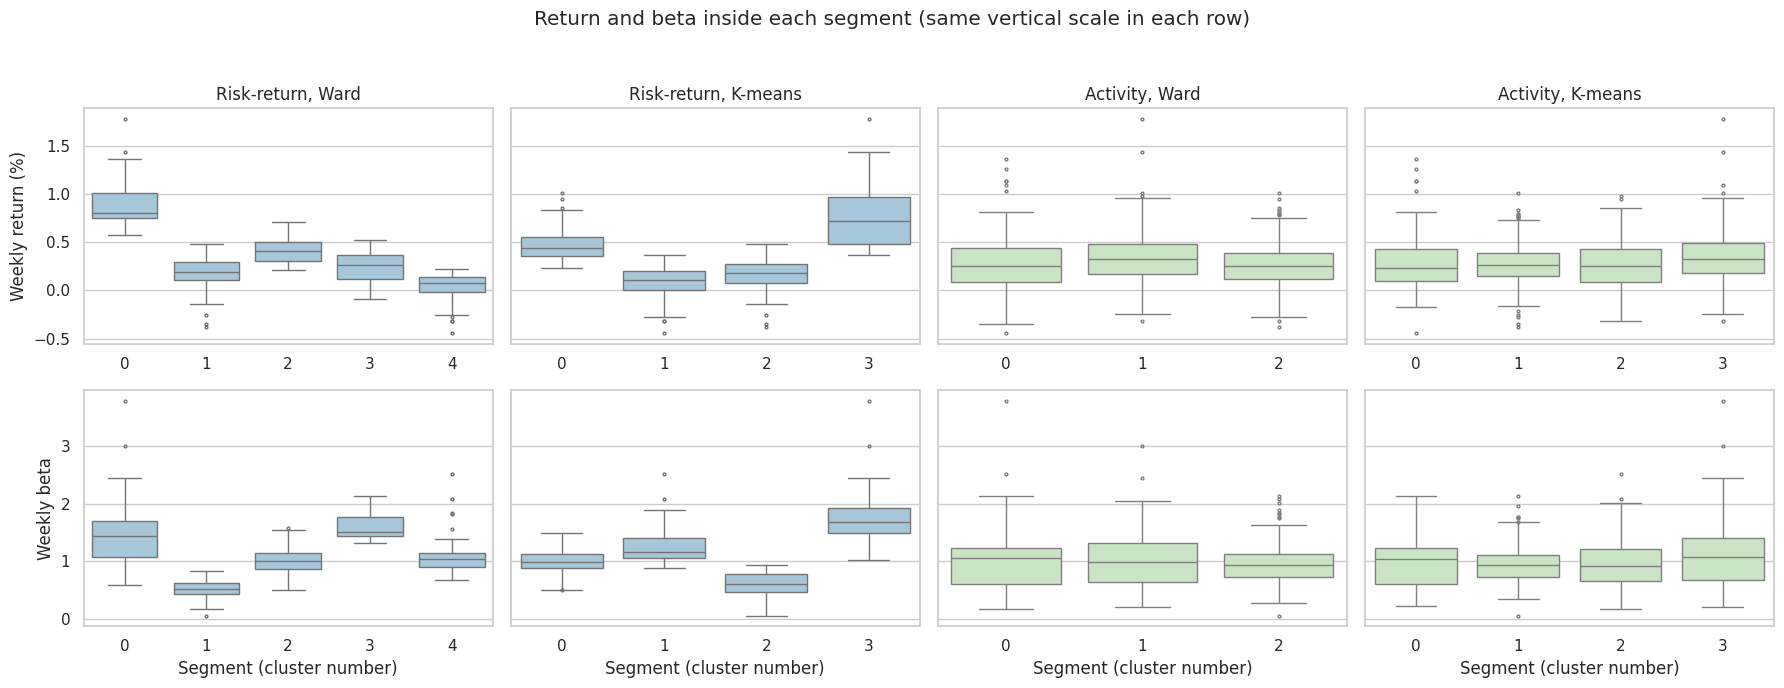

In [111]:
# Chart: weekly return (top row) and beta (bottom row) inside every segment of all four solutions.
# Each row shares one vertical axis, so big differences between boxes mean the lens separates that
# measure, and boxes at the same height mean it does not.
titles = {"RR_Ward": "Risk-return, Ward", "RR_KMeans": "Risk-return, K-means", "RFM_Ward": "Activity, Ward", "RFM_KMeans": "Activity, K-means"}
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
for j, (key, (labels, matrix)) in enumerate(solutions.items()):
    d = pd.DataFrame({"cluster": labels, "Weekly return (%)": features["mean_weekly_return"].to_numpy() * 100,
                      "Weekly beta": features["weekly_beta"].to_numpy()})
    colour = "#9ecae1" if matrix == "rr" else "#c7e9c0"
    sns.boxplot(data=d, x="cluster", y="Weekly return (%)", ax=axes[0, j], color=colour, fliersize=2)
    sns.boxplot(data=d, x="cluster", y="Weekly beta", ax=axes[1, j], color=colour, fliersize=2)
    axes[0, j].set_title(titles[key]); axes[0, j].set_xlabel("")
    axes[1, j].set_xlabel("Segment (cluster number)")
    if j > 0:
        axes[0, j].set_ylabel(""); axes[1, j].set_ylabel("")
fig.suptitle("Return and beta inside each segment (same vertical scale in each row)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

,"Risk-return, Ward","Risk-return, K-means","Activity, Ward","Activity, K-means"
Weekly return,0.6955,0.5910,0.0222,0.0168
Beta,0.6124,0.6506,0.0108,0.0219
Recency,0.0181,0.0364,0.6370,0.6440
Frequency,0.0136,0.0088,0.1284,0.5737
log1p Monetary,0.0956,0.1178,0.5187,0.5240


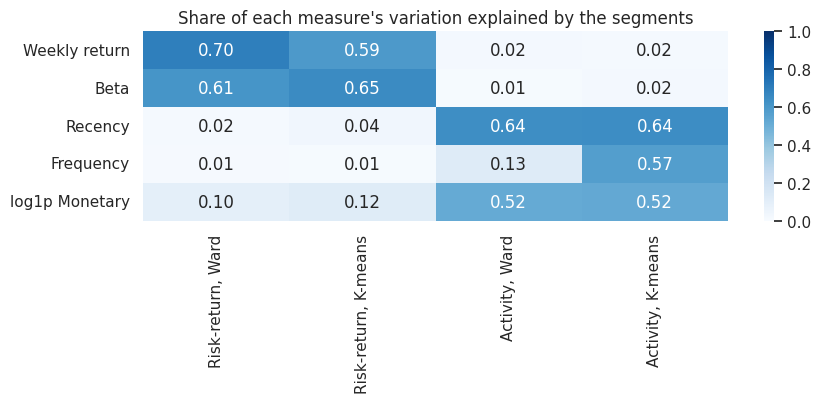

In [112]:
# Chart: which measures does each lens separate? Eta-squared is the share of a measure's variation
# that lies between the segments (0 = segments do not differ on it, 1 = segments completely separate
# it). All five measures, all four solutions.
def eta_share(values, labels):
    v = np.asarray(values, dtype=float); lab = np.asarray(labels)
    total = ((v - v.mean()) ** 2).sum()
    between = sum((lab == c).sum() * (v[lab == c].mean() - v.mean()) ** 2 for c in np.unique(lab))
    return between / total

measures = pd.DataFrame({"Weekly return": features["mean_weekly_return"], "Beta": features["weekly_beta"],
                         "Recency": features["Recency"], "Frequency": features["Frequency"],
                         "log1p Monetary": np.log1p(features["Monetary"])})
eta_all = pd.DataFrame({titles[key]: {m: eta_share(measures[m], labels) for m in measures.columns}
                        for key, (labels, matrix) in solutions.items()})
display(eta_all)
eta_all.to_csv(f"{DATA_DIR}/eta_squared_all_solutions.csv")

plt.figure(figsize=(9, 4.2))
sns.heatmap(eta_all, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Share of each measure's variation explained by the segments")
plt.tight_layout()
plt.show()

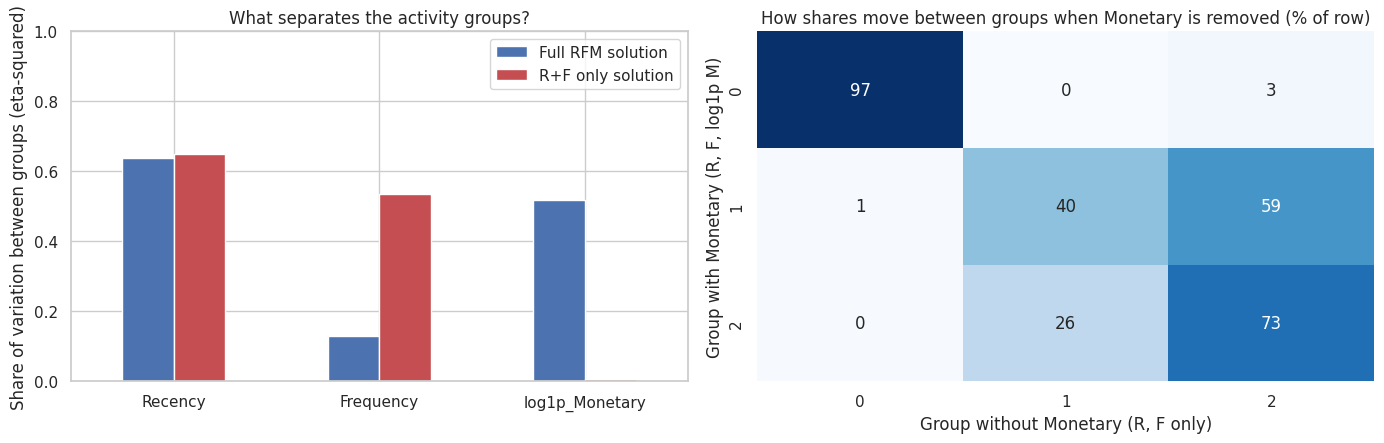

In [113]:
# Charts for 3.2.2: (left) which activity measures separate the Ward groups, with and without
# Monetary; (right) where the shares of each full-RFM group end up when Monetary is removed (% of
# row).
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
eta.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0)
axes[0].set_ylabel("Share of variation between groups (eta-squared)")
axes[0].set_title("What separates the activity groups?")
axes[0].set_ylim(0, 1)

move = pd.crosstab(pd.Series(ward_rfm, name="Group with Monetary (R, F, log1p M)"),
                   pd.Series(ward_rf, name="Group without Monetary (R, F only)"), normalize="index") * 100
sns.heatmap(move, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("How shares move between groups when Monetary is removed (% of row)")
plt.tight_layout()
plt.show()

Average pairwise weekly-return correlation across all shares: 0.30


,Average correlation within segments,Average correlation between segments
Solution,,
"Risk-return, Ward",0.3480,0.2816
"Risk-return, K-means",0.3371,0.2825
"Activity, Ward",0.3117,0.2902
"Activity, K-means",0.3134,0.2921


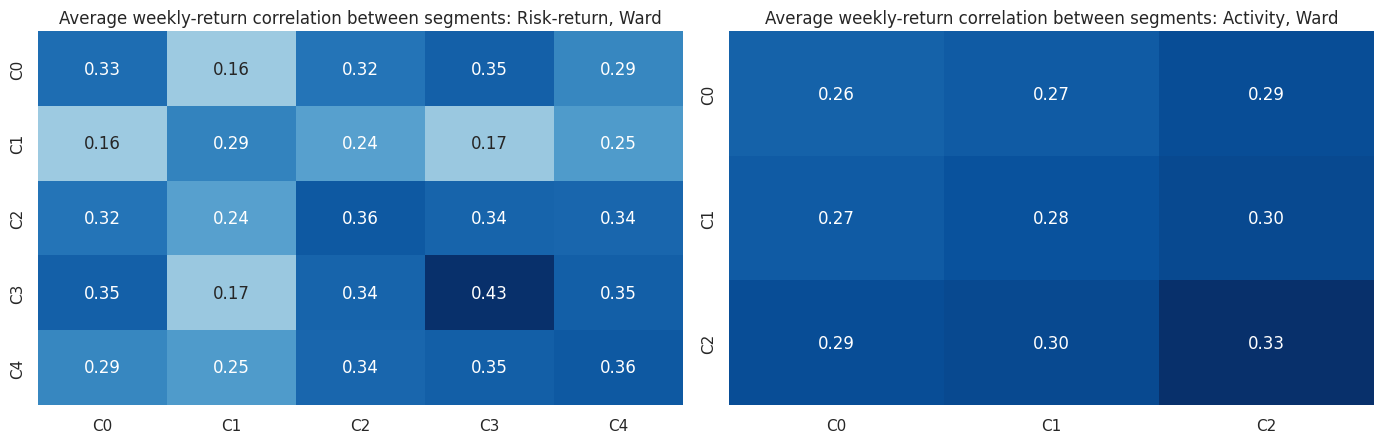

In [114]:
# Return dependencies (3.2.3): do shares in the same segment move together? Average pairwise
# correlation of weekly returns between segments (diagonal = within a segment). Each share's
# correlation with itself is ignored. High values everywhere mean the market drives all shares, so
# similar beta or activity alone does not prove diversification.
rets = weekly_ret.loc[:, features.index]
corr = rets.corr().to_numpy().copy()
np.fill_diagonal(corr, np.nan)
print(f"Average pairwise weekly-return correlation across all shares: {np.nanmean(corr):.2f}")

def segment_corr(labels):
    ids = np.unique(labels)
    out = pd.DataFrame(index=[f"C{c}" for c in ids], columns=[f"C{c}" for c in ids], dtype=float)
    for a in ids:
        for b in ids:
            out.loc[f"C{a}", f"C{b}"] = np.nanmean(corr[np.ix_(labels == a, labels == b)])
    return out

rows = []
for key, (labels, matrix) in solutions.items():
    same = labels[:, None] == labels[None, :]
    rows.append({"Solution": titles[key], "Average correlation within segments": np.nanmean(corr[same]),
                 "Average correlation between segments": np.nanmean(corr[~same])})
dependency = pd.DataFrame(rows).set_index("Solution")
display(dependency)
dependency.to_csv(f"{DATA_DIR}/return_dependency_by_solution.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (labels, key) in zip(axes, [(ward_rr, "RR_Ward"), (ward_rfm, "RFM_Ward")]):
    sns.heatmap(segment_corr(labels), annot=True, fmt=".2f", cmap="Blues", vmin=0, cbar=False, ax=ax)
    ax.set_title(f"Average weekly-return correlation between segments: {titles[key]}")
plt.tight_layout()
plt.show()

### Save Task 3 Outputs

In [115]:
# Save the Task 3 metadata, then zip the data folder and download it.
import json
import os
import shutil

# Task 3 metadata
task3_metadata = {
    "study_period": {
        "start": START_DATE,
        "end_exclusive": END_DATE,
        "benchmark": BENCHMARK,
        "observation_date": str(observation_date.date()),
        "final_share_count": int(len(features))
    },
    "evaluation": {
        "average_pairwise_return_correlation": round(float(np.nanmean(corr)), 4)
    }
}

# Save the metadata in the data folder
with open(f"{DATA_DIR}/task3_metadata.json", "w") as f:
    json.dump(task3_metadata, f, indent=2)

# Zip the data folder
shutil.make_archive("task3_data", "zip", DATA_DIR)

try:
    from google.colab import files
    files.download("task3_data.zip")
    print("Task 3 outputs zipped and download initiated.")
except ImportError:
    print("Not running in Colab - the zip is saved as task3_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Task 3 outputs zipped and download initiated.
